# Yemen cholera, second wave: the extended comparison

This notebook follows on from `yemen_cholera_dpinn_vs_ffpinn_fixed.ipynb` and changes three things
in every arm before adding eleven new analyses.

**What changed relative to the original study**

1. **Corrected loader.** The original dropped each governorate's first reporting interval (21
   intervals, 16,598 cases) and anchored the initial condition on the second one.
2. **Negative-binomial likelihood.** A pilot run under the original Poisson deviance showed the
   residual variance to be about 80× Poisson (median over 21 governorates; implied negative-binomial
   size $k\approx 11$). A Poisson deviance reads that reporting noise as signal: it over-weights
   batch-release spikes and makes every interval too narrow. Every arm (deterministic, PINN, spline,
   SIR, spatial) now uses the NB deviance with a governorate-specific size $k$, estimated by method of
   moments around a penalised-spline fit **on the training rows of each fit only**. The Poisson
   objective is kept as the `poisson` sensitivity variant (§6).
3. **Smoothed initial-condition anchor.** The initial stock was set from the first positive
   interval, which in a sparse series is often a batch release (Al Maharah's was 3.5× its own mean).
   It is now the case-weighted rate over the 14 days from that interval.

And one new spatial architecture (§10): a **governorate network** model replacing diffusion along a
single distance-from-Sana'a axis, which places Shabwah 2 km from Aden and Dhamar 4 km from Amran.

**The eleven analyses**

| § | analysis | what it answers |
|---|---|---|
| 1 | 10 random seeds per PINN | are between-architecture differences larger than initialisation noise? |
| 2 | rotated 4-fold holdout | which arm generalises, pooled over every interval rather than one split |
| 3 | bands on $\beta_1(t)$, $\beta_2(t)$, $\mathcal R(t)$ | how well each quantity is determined |
| 4 | recovery of known values | given a literature-calibrated truth, what comes back? and do the real-data fits agree with published Yemen estimates? |
| 5 | outside reference for $\mathcal R(t)$ | a model-free Cori/EpiEstim $R_t$ from the same counts |
| 6 | sensitivity | the fixed modelling choices: initial condition, age profile, observable, winsorisation, objective, Fourier order, coupling weight |
| 7 | residual diagnostics | is the Poisson likelihood adequate? |
| 8 | simple baselines | a penalised spline and a plain SIR model |
| 9 | all 21 governorates | the deterministic arm and both baselines everywhere |
| 10 | location-varying $\beta(t,x)$ | does transmission that varies by governorate fit the spatial model better? |
| 11 | observed against fitted surfaces | the whole $I(t,x)$ field, not just per-city curves |

**Scope of the PINN fits.** Each PINN fit costs about 3–4 CPU-minutes. Following the study design
agreed for this extension, the four PINN architectures were run with 10 seeds at five governorates
chosen by total reported cases: the top three (Al Hudaydah, Hajjah, Dhamar), the median governorate
(Al Bayda, 11th of 21) and the smallest (Hadramaut). The deterministic arm and both baselines were
run at all 21. Every fit is a separate result file (`results/<city>/<arm>_s<seed>_f<fold>_<variant>.pkl`),
so the tables below rebuild from disk in seconds; `RUN = True` reruns everything.

Day 0 is 2017-05-22; the record runs to day 272 (2018-02-18). Throughout, $\mathcal R(t)$ is the
model's next-generation number including depletion of susceptibles,
$\mathcal R(t)=\bar S(t)\,\kappa_{EI}J_1[\beta_1(t)+\alpha_0\beta_2(t)J_2]$, so it is directly
comparable with an effective reproduction number $R_t$.

## Environment

In [1]:
import sys, subprocess
for pkg in ("torch", "scipy", "pandas", "matplotlib", "jinja2"):
    try:
        __import__(pkg)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True)
import numpy as np, torch
print("numpy", np.__version__, "| torch", torch.__version__)

numpy 2.5.4 | torch 2.15.0+cu132


## Source modules

Every module the study uses, written to the working directory so this notebook is the single
source. `seip.py`, `data_io.py`, `fit.py` and `pinn.py` are the original study's modules with the
first-interval loader fix, the smoothed initial-condition anchor and the negative-binomial
deviance; the rest are new:

| module | role |
|---|---|
| `run_job.py` | one fit (any arm, seed, fold, sensitivity variant or synthetic truth) → one result file |
| `baselines.py` | P-spline and SIR baselines (Poisson or negative binomial), per-governorate NB size |
| `epiestim.py` | Cori / EpiEstim model-free $R_t$ |
| `spatial_fit.py` | full $(t,x)$ model with shared $\beta(t)$ or location-varying $\beta(t,x)$ |
| `network_fit.py` | governorate network (metapopulation) model, gravity mixing on great-circle distances |
| `make_jobs.py`, `run_queue.sh`, `spatial_chain.sh` | the job lists and the parallel queue |
| `analysis.py` | every table and figure below, from the result files only |

In [2]:
%%writefile seip.py
"""
seip.py -- Age-structured SEIP transport-diffusion model for the Yemen
second-wave cholera record.

    dS/dt            = D1 S_xx - S[int b1(t,a) I da + int b2(t,b) P db] + Lam - mu1 S
    dE/dt + dE/da    = D2 E_xx - (mu2 + sigma(a)) E
    dI/dt + dI/da    = D3 I_xx - (mu3 + gamma + delta) I
    dP/dt + dP/db    = D4 P_xx - mu4 P

    E(t,0,x) = S(t,x) [ int b1 I da + int b2 P db ]      <- the unknowns enter HERE
    I(t,0,x) = int sigma(a) E(t,a,x) da
    P(t,0,x) = int alpha(a) I(t,a,x) da

Homogeneous Neumann in x at both ends; no terminal condition in a or b -- the age
derivatives are outward transport, so a cohort reaching the truncation age leaves
the tracked population.

NUMERICS.  da = db = dt, so age advection is the exact characteristic shift and
introduces no numerical diffusion in age.  The time integrator is Strang
splitting about the reaction-transport operator,

    exp(dt/2 A) exp(dt B) exp(dt/2 A),      A = diffusion,  B = reaction+transport,

with the renewal inflows evaluated at the midpoint by a predictor-corrector, so
the scheme is second order in dt.  A first-order Lie variant is retained under
`scheme="lie"` because the earlier results in this project were produced with it
and a like-for-like comparison needs it.
"""

from __future__ import annotations

import numpy as np
from dataclasses import dataclass, field

# --------------------------------------------------------------------------
# Fixed constants. None of these are ever fitted.
# --------------------------------------------------------------------------
MU1 = MU2 = MU3 = 1.0 / (70.0 * 365.0)   # background mortality, /day
LAMBDA_REC = MU1                          # recruitment, population fraction /day
SIGMA0 = 1.0 / 1.4                        # latency progression, /day
GAMMA = 1.0 / 7.0                         # recovery, /day
DELTA = 0.001                             # disease-induced mortality, /day
MU4 = 1.0 / 30.0                          # environmental pathogen decay, /day
ALPHA0 = 2.0                              # shedding amplitude
A_MAX = 7.0                               # infection-age truncation, days
B_MAX = 30.0                              # pathogen-age truncation, days
X_MAX_FULL = 1051.806                     # full domain, km (Socotra)
X_MAX_OBSERVED = 795.396633               # farthest REPORTING governorate (Al Maharah)
T_MAX = 272.0                             # window, days (22 May 2017 - 18 Feb 2018)

R_I = MU3 + GAMMA + DELTA                 # infectious removal rate, /day
R_E = MU2 + SIGMA0                        # exposed removal rate, /day

# Residence times.  TRUNC is the occupancy the model actually holds at constant
# incidence; NAIVE is what the untruncated residence-time identity assumes.
#
# These ratios are NOT both 1/(1-e^-1).  mu4*B_MAX = 1 exactly, so the
# environmental ratio is 1.581977.  R_I*A_MAX = 1.0072740, because gamma = 1/7 is
# joined by delta and mu3, so the infectious ratio is 1.575332.  Earlier project
# text gave 1.58 for both and "about 58% more mass"; the infectious figure is
# 57.5%.
TAU_I_TRUNC = (1.0 - np.exp(-R_I * A_MAX)) / R_I      # 4.411419 d
TAU_I_NAIVE = 1.0 / R_I                               # 6.949450 d
TAU_P_TRUNC = (1.0 - np.exp(-MU4 * B_MAX)) / MU4      # 18.963617 d
TAU_P_NAIVE = 1.0 / MU4                               # 30.000000 d
RATIO_I = TAU_I_NAIVE / TAU_I_TRUNC                   # 1.575332
RATIO_P = TAU_P_NAIVE / TAU_P_TRUNC                   # 1.581977

# Exact kernel integrals (closed form, cross-checked against adaptive quadrature).
# int_0^7 a(7-a) e^{-a/12} da.  An earlier version of this file quoted 43.012,
# which was this module's own trapezoid value at dt=0.25, not the integral.
INT_F_DA = 43.0688907175
INT_H_DB = 1078.5


def f_kernel(a):
    """Infection-age transmission/shedding shape. Zero at 0 and A_MAX, peak at a=3."""
    a = np.asarray(a, dtype=float)
    return a * (A_MAX - a) * np.exp(-a / 12.0)


def h_kernel(b):
    """Pathogen-age infectivity: 700 on [0,1], 1399-699b on (1,2], 1 on (2,30]."""
    b = np.asarray(b, dtype=float)
    out = np.ones_like(b)
    out = np.where(b <= 1.0, 700.0, out)
    mid = (b > 1.0) & (b <= 2.0)
    out = np.where(mid, 1399.0 - 699.0 * b, out)
    return out


# --------------------------------------------------------------------------
# Grid
# --------------------------------------------------------------------------
@dataclass
class Grid:
    """da = db = dt is required, not a convenience: it makes the age shift exact.

    Quadrature in a and b is composite trapezoid on this same grid, which is a
    documented substitution for the Gauss-Legendre rule the methodology specifies.
    It is benign here -- at dt <= 0.25 both breakpoints of h land on grid nodes and
    h is continuous at both -- and the convergence of the next-generation
    integrals is reported by ngm_integrals(..., report=True).
    """
    dt: float = 0.25
    nx: int = 41
    x_max: float = X_MAX_FULL

    na: int = field(init=False); nb: int = field(init=False); nt: int = field(init=False)
    a: np.ndarray = field(init=False); b: np.ndarray = field(init=False)
    x: np.ndarray = field(init=False); t: np.ndarray = field(init=False)
    dx: float = field(init=False)
    wa: np.ndarray = field(init=False); wb: np.ndarray = field(init=False)
    wf: np.ndarray = field(init=False); wh: np.ndarray = field(init=False)
    wsig: np.ndarray = field(init=False); walpha: np.ndarray = field(init=False)

    def __post_init__(self):
        for name, L in (("A_MAX", A_MAX), ("B_MAX", B_MAX), ("T_MAX", T_MAX)):
            n = L / self.dt
            if abs(n - round(n)) > 1e-9:
                raise ValueError(f"dt={self.dt} does not divide {name}={L}; "
                                 "da=db=dt is required for the exact age shift")
        self.na = int(round(A_MAX / self.dt))
        self.nb = int(round(B_MAX / self.dt))
        self.nt = int(round(T_MAX / self.dt))
        self.a = np.linspace(0.0, A_MAX, self.na + 1)
        self.b = np.linspace(0.0, B_MAX, self.nb + 1)
        self.t = np.linspace(0.0, T_MAX, self.nt + 1)
        if self.nx == 1:
            # Single location: the spatial operator is switched off entirely, so
            # dx is never used. Only legal with D1=..=D4=0.
            self.x = np.array([0.0]); self.dx = np.inf
        else:
            self.x = np.linspace(0.0, self.x_max, self.nx)
            self.dx = self.x[1] - self.x[0]

        self.wa = np.full(self.na + 1, self.dt); self.wa[0] *= 0.5; self.wa[-1] *= 0.5
        self.wb = np.full(self.nb + 1, self.dt); self.wb[0] *= 0.5; self.wb[-1] *= 0.5
        self.wf = self.wa * f_kernel(self.a)
        self.wh = self.wb * h_kernel(self.b)
        self.wsig = self.wa * SIGMA0
        self.walpha = self.wa * ALPHA0 * f_kernel(self.a)

    def diffusion_number(self, diff):
        """D dt / dx^2, reported for orientation only. The diffusion sub-flow is
        applied by its exact spectral propagator, so there is NO CFL restriction
        and this number does not bound the step."""
        if self.nx == 1:
            return 0.0
        return max(diff.as_tuple()) * self.dt / self.dx ** 2


def ngm_integrals(grid: Grid = None, report=False):
    """kappa_EI, J1, J2.  Published: 0.993209, 27.477214, 1040.759087.

    With grid=None these are computed by adaptive quadrature and are exact to
    ~1e-10. Passing a Grid returns that grid's trapezoid values instead, which is
    what a fit on that grid actually uses.
    """
    if grid is None:
        from scipy.integrate import quad
        kw = dict(epsabs=1e-12, epsrel=1e-12, limit=200)
        kappa = quad(lambda a: SIGMA0 * np.exp(-R_E * a), 0, A_MAX, **kw)[0]
        j1 = quad(lambda a: f_kernel(a) * np.exp(-R_I * a), 0, A_MAX, **kw)[0]
        j2 = sum(quad(lambda b: h_kernel(b) * np.exp(-MU4 * b), lo, hi, **kw)[0]
                 for lo, hi in ((0, 1), (1, 2), (2, B_MAX)))
    else:
        kappa = float(np.sum(grid.wa * SIGMA0 * np.exp(-R_E * grid.a)))
        j1 = float(np.sum(grid.wa * f_kernel(grid.a) * np.exp(-R_I * grid.a)))
        j2 = float(np.sum(grid.wb * h_kernel(grid.b) * np.exp(-MU4 * grid.b)))
    if report:
        pub = (0.993209, 27.477214, 1040.759087)
        for nm, got, want in zip(("kappa_EI", "J1", "J2"), (kappa, j1, j2), pub):
            print(f"  {nm:<9s} {got:>14.6f}  published {want:>12.6f}  "
                  f"rel {abs(got-want)/want:.2e}")
    return kappa, j1, j2


# --------------------------------------------------------------------------
# Diffusion
# --------------------------------------------------------------------------
def laplacian_x(u, dx, stencil="fv"):
    """Second difference along the LAST axis with zero-flux ends.

    stencil='fv'  finite-volume / cell-centred: no flux across the two outer
                  faces, so the end rows are (u1-u0) and (u_{N-2}-u_{N-1}).
                  SYMMETRIC and MASS-CONSERVING (columns sum to zero), and
                  diagonalised exactly by the DCT-II.
    stencil='ghost'  node-centred mirror, end rows 2(u1-u0). This is what earlier
                  versions of this project used. It is neither symmetric nor
                  conservative -- total mass drifts under pure diffusion -- and is
                  kept only so an earlier result can be reproduced on request.
    """
    lap = np.empty_like(u)
    lap[..., 1:-1] = u[..., 2:] - 2.0 * u[..., 1:-1] + u[..., :-2]
    c = 1.0 if stencil == "fv" else 2.0
    lap[..., 0] = c * (u[..., 1] - u[..., 0])
    lap[..., -1] = c * (u[..., -2] - u[..., -1])
    return lap / (dx * dx)


def diffusion_eigenvalues(nx, dx):
    """Eigenvalues of the finite-volume Neumann Laplacian, whose eigenvectors are
    the DCT-II basis: lambda_j = -4 sin^2(pi j / 2N) / dx^2."""
    j = np.arange(nx)
    return -4.0 * np.sin(np.pi * j / (2.0 * nx)) ** 2 / (dx * dx)


def diffuse_exact(u, factor, axis=-1):
    """Apply exp(tau D L) exactly, where `factor` = exp(tau D lambda_j).

    Spectral, so this is the exact solution operator of the semi-discrete
    diffusion problem rather than an approximation of it: there is no splitting
    error from this sub-flow and no CFL restriction at all. Mass is conserved to
    machine precision because lambda_0 = 0.
    """
    from scipy.fft import dct, idct
    return idct(factor * dct(u, type=2, norm="ortho", axis=axis),
                type=2, norm="ortho", axis=axis)


@dataclass
class Diffusion:
    D1: float = 50.0
    D2: float = 50.0
    D3: float = 50.0
    D4: float = 50.0

    def as_tuple(self):
        return (self.D1, self.D2, self.D3, self.D4)

    def label(self):
        v = self.as_tuple()
        return f"D={v[0]:g}" if len(set(v)) == 1 else \
               "D=(" + ",".join(f"{z:g}" for z in v) + ")"

    def length_scale(self, T=T_MAX):
        """sqrt(2 D T): how far mass spreads over the window, per field."""
        return tuple(np.sqrt(2.0 * D * T) for D in self.as_tuple())


# --------------------------------------------------------------------------
# Initial condition
# --------------------------------------------------------------------------
@dataclass
class InitialCondition:
    S0: np.ndarray
    I0: np.ndarray
    P0: np.ndarray
    E0: np.ndarray
    I_agg_nodal: np.ndarray
    P_agg_nodal: np.ndarray
    S_nodal: np.ndarray
    opts: dict = field(default_factory=dict)


def _lognormal_profile(v, mean, sd, w):
    """Log-normal density on the grid v, moment-matched to (mean, sd), truncated
    to the grid and renormalized to unit mass under the weights w."""
    s2 = np.log(1.0 + (sd / mean) ** 2)
    mu = np.log(mean) - 0.5 * s2
    s = np.sqrt(s2)
    g = np.zeros_like(v)
    pos = v > 0
    g[pos] = np.exp(-(np.log(v[pos]) - mu) ** 2 / (2 * s2)) / (v[pos] * s * np.sqrt(2 * np.pi))
    tot = float(np.sum(w * g))
    return g / tot if tot > 0 else g


def build_initial_condition(grid: Grid, xg, y_first, cum_first,
                            truncation_correction: bool = False,
                            age_profile: str = "flat",
                            p_from_model: bool = False) -> InitialCondition:
    """Data-anchored initial state.

    truncation_correction=False reproduces the project identity
        I_agg0 = y0 / (mu3+gamma+delta),  P_agg0 = alpha0 I_agg0 / mu4,
    which inverts an UNtruncated mean duration. True uses the occupancy the
    truncated system actually holds -- smaller by 1.5753 (I) and 1.5820 (P).

    age_profile: 'flat' (project baseline, adds no assumption the synthetic IC did
    not already carry), 'equilibrium' (exponential, consistent with the stock
    identity), or 'lognormal' (mean/SD 3.5/2.0 d for I and 10/6 d for P, the
    profile the methodology records as the available refinement).
    """
    tau_I = TAU_I_TRUNC if truncation_correction else TAU_I_NAIVE
    tau_P = TAU_P_TRUNC if truncation_correction else TAU_P_NAIVE

    y_first = np.asarray(y_first, float)
    I_agg = y_first * tau_I
    P_agg = ALPHA0 * I_agg * tau_P
    R_frac = np.maximum(0.0, np.asarray(cum_first, float) - I_agg)
    S_nodal = np.maximum(0.0, 1.0 - I_agg - R_frac)

    order = np.argsort(xg)
    xs = np.asarray(xg, float)[order]

    def lift(vals):
        """Nodal governorate values -> field on the x grid: piecewise linear
        between reporting coordinates, held flat beyond the farthest one."""
        v = np.asarray(vals, float)[order]
        if grid.nx == 1:
            return np.array([v[0]])
        return np.interp(grid.x, xs, v, left=v[0], right=v[-1])

    S0 = lift(S_nodal); I_agg_f = lift(I_agg); P_agg_f = lift(P_agg)

    if age_profile == "flat":
        pI = np.ones_like(grid.a) / A_MAX
        pP = np.ones_like(grid.b) / B_MAX
    elif age_profile == "equilibrium":
        pI = np.exp(-R_I * grid.a); pI /= np.sum(grid.wa * pI)
        pP = np.exp(-MU4 * grid.b); pP /= np.sum(grid.wb * pP)
    elif age_profile == "lognormal":
        pI = _lognormal_profile(grid.a, 3.5, 2.0, grid.wa)
        pP = _lognormal_profile(grid.b, 10.0, 6.0, grid.wb)
    else:
        raise ValueError(f"unknown age_profile {age_profile!r}")

    I0 = pI[:, None] * I_agg_f[None, :]
    P0 = pP[:, None] * P_agg_f[None, :]

    if p_from_model:
        # The project IC sets P_agg0 = alpha0 I_agg0 / mu4, treating the shedding
        # inflow as alpha0 * I_agg. The model's own renewal condition is
        # alpha0 * int f(a) I da, larger by int f da / A_MAX = 6.1527 under a flat
        # profile. This rescales P(0,.) to the stock that renewal implies, so the
        # IC and the equation it feeds agree at t=0.
        shed = grid.walpha @ I0
        cur = grid.wb @ P0
        scale = np.divide(shed * tau_P, cur, out=np.ones_like(cur), where=cur > 0)
        P0 = P0 * scale[None, :]
        P_agg = P_agg * (scale[0] if grid.nx == 1 else
                         np.interp(np.asarray(xg, float), grid.x, scale))

    E0 = np.zeros((grid.na + 1, grid.nx))
    return InitialCondition(S0, I0, P0, E0, I_agg, P_agg, S_nodal,
                            opts=dict(truncation_correction=truncation_correction,
                                      age_profile=age_profile,
                                      p_from_model=p_from_model,
                                      tau_I=tau_I, tau_P=tau_P))


# --------------------------------------------------------------------------
# Forward solve
# --------------------------------------------------------------------------
OBS_FORCE_OF_INFECTION = "foi"      # H = S [int b1 I da + int b2 P db]
OBS_INFECTIOUS_ONSET = "onset"      # H = int sigma(a) E da, the declared alternative


def solve_forward(grid: Grid, ic: InitialCondition, beta10_t, beta20_t,
                  diff: Diffusion, want_states: bool = False,
                  scheme: str = "strang", observable: str = OBS_FORCE_OF_INFECTION,
                  n_sweeps: int = 2, record_full: bool = False, mix=None):
    """March over [0, T_MAX].

    scheme
        'strang'  Strang splitting about the reaction-transport flow, with the
                  diffusion half-flows applied EXACTLY (spectral) and the renewal
                  boundary values taken at the NEW time level by a predictor-
                  corrector. Second order in dt.
        'lie'     first-order Lie splitting with the renewal inflows held at the
                  old time level: what this project's earlier results used.

    observable
        'foi'     S [int b1 I da + int b2 P db], the baseline.
        'onset'   int sigma(a) E da, the declared sensitivity alternative.

    Returns H (nt+1, nx), Sbar (nt+1,), and optionally recorded states.
    """
    if scheme not in ("strang", "lie"):
        raise ValueError(f"unknown scheme {scheme!r}")
    if observable not in (OBS_FORCE_OF_INFECTION, OBS_INFECTIOUS_ONSET):
        raise ValueError(f"unknown observable {observable!r}")
    dt = grid.dt
    Ds = diff.as_tuple()
    if grid.nx == 1 and any(Ds):
        raise ValueError("a single-location grid carries no spatial operator; "
                         "nx=1 requires D1=D2=D3=D4=0")

    S = ic.S0.copy(); E = ic.E0.copy(); I = ic.I0.copy(); P = ic.P0.copy()
    decE = np.exp(-R_E * dt); decI = np.exp(-R_I * dt); decP = np.exp(-MU4 * dt)

    # Exact diffusion propagators. Strang applies two half-steps per step; Lie one
    # full step. Precomputed once -- they do not depend on t.
    spatial = grid.nx > 1 and any(Ds)
    if spatial:
        eig = diffusion_eigenvalues(grid.nx, grid.dx)
        tau = 0.5 * dt if scheme == "strang" else dt
        fac = [np.exp(D * tau * eig) if D else None for D in Ds]

    def diffuse(S, E, I, P):
        if not spatial:
            return S, E, I, P
        if fac[0] is not None: S = diffuse_exact(S, fac[0])
        if fac[1] is not None: E = diffuse_exact(E, fac[1])
        if fac[2] is not None: I = diffuse_exact(I, fac[2])
        if fac[3] is not None: P = diffuse_exact(P, fac[3])
        return S, E, I, P

    # Infection pressure felt at each location. With `mix` (an nx-by-nx
    # row-stochastic matrix) susceptibles at location g are exposed to the
    # mix-weighted pressure of every location -- the metapopulation coupling
    # used by network_fit.py in place of diffusion along one axis.
    if mix is None:
        pI = lambda I_: grid.wf @ I_
        pP = lambda P_: grid.wh @ P_
    else:
        pI = lambda I_: mix @ (grid.wf @ I_)
        pP = lambda P_: mix @ (grid.wh @ P_)

    H = np.empty((grid.nt + 1, grid.nx))
    Sbar = np.empty(grid.nt + 1)
    want_states = want_states or record_full
    rec = {k: np.empty((grid.nt + 1, grid.nx))
           for k in ("I_agg", "P_agg", "E_agg", "foi", "S")} if want_states else None
    if record_full:
        # The full age-resolved fields. Only sane at small nx -- for a single
        # location this is (nt+1, na+1), which is what a city-level I(t,a)
        # surface figure needs.
        rec["I_full"] = np.empty((grid.nt + 1, grid.na + 1, grid.nx))
        rec["E_full"] = np.empty((grid.nt + 1, grid.na + 1, grid.nx))
        rec["P_full"] = np.empty((grid.nt + 1, grid.nb + 1, grid.nx))

    for k in range(grid.nt + 1):
        lamI = beta10_t[k] * pI(I)
        lamP = beta20_t[k] * pP(P)
        foi0 = lamI + lamP
        H[k] = S * foi0 if observable == OBS_FORCE_OF_INFECTION else (grid.wsig @ E)
        Sbar[k] = S.mean()
        if want_states:
            rec["I_agg"][k] = grid.wa @ I
            rec["P_agg"][k] = grid.wb @ P
            rec["E_agg"][k] = grid.wa @ E
            rec["foi"][k] = foi0
            rec["S"][k] = S
            if record_full:
                rec["I_full"][k] = I; rec["E_full"][k] = E; rec["P_full"][k] = P

        if k == grid.nt:
            break

        if scheme == "strang":
            S, E, I, P = diffuse(S, E, I, P)
            foi0 = (beta10_t[k] * pI(I)
                    + beta20_t[k] * pP(P))                  # after the half-flow

        inE0 = S * foi0
        inI0 = grid.wsig @ E
        inP0 = grid.walpha @ I

        # age/duration transport: exact characteristic shift plus exact decay
        En = np.empty_like(E); In = np.empty_like(I); Pn = np.empty_like(P)
        En[1:] = E[:-1] * decE; In[1:] = I[:-1] * decI; Pn[1:] = P[:-1] * decP
        En[0] = inE0; In[0] = inI0; Pn[0] = inP0            # predictor

        if scheme == "lie":
            S = S + dt * (-S * foi0 + LAMBDA_REC - MU1 * S)
            np.clip(S, 0.0, None, out=S)
        else:
            b10h, b20h = beta10_t[k + 1], beta20_t[k + 1]
            Snew = S
            for _ in range(max(1, n_sweeps)):
                foi1 = b10h * pI(In) + b20h * pP(Pn)
                # S by the trapezoid rule, solved semi-implicitly so the sink uses
                # the new-time S rather than the old one
                Snew = ((S * (1.0 - 0.5 * dt * (foi0 + MU1)) + dt * LAMBDA_REC)
                        / (1.0 + 0.5 * dt * (foi1 + MU1)))
                np.clip(Snew, 0.0, None, out=Snew)
                # The renewal conditions are constraints at the NEW time level, so
                # the a=0 / b=0 cells take their new-time values, not a time
                # average of old and new. Swept in causal order: E(.,0) needs I,P;
                # I(.,0) needs E; P(.,0) needs I.
                En[0] = Snew * foi1
                In[0] = grid.wsig @ En
                Pn[0] = grid.walpha @ In
            S = Snew
        E, I, P = En, In, Pn

        np.clip(E, 0.0, None, out=E)
        np.clip(I, 0.0, None, out=I)
        np.clip(P, 0.0, None, out=P)

        S, E, I, P = diffuse(S, E, I, P)

    if want_states:
        rec.update(S_final=S, I_final=I, P_final=P)
        return H, Sbar, rec
    return H, Sbar, None


def R0_of_t(beta10_t, beta20_t, Sbar, kappa, J1, J2):
    """R0(t) = Sbar(t) kappa_EI J1 (beta10 + alpha0 beta20 J2).

    Always call this rather than re-deriving the expression inline: reusing the
    formula or its constituent integrals across reductions without rederiving is
    a documented failure mode in this project's earlier work, and dropping Sbar
    silently compares two different definitions.
    """
    return np.asarray(Sbar) * kappa * J1 * (np.asarray(beta10_t)
                                            + ALPHA0 * np.asarray(beta20_t) * J2)


def route_share(beta10_t, beta20_t, J2, grid=None):
    """Environmental share of the next-generation contribution, in [0, 1]:

        alpha0 beta20 J2 / (beta10 + alpha0 beta20 J2)

    Reported in preference to the ratio alpha0 beta20 J2 / beta10, whose POINTWISE
    mean is dominated by the stretches where beta10 sits on the positivity floor
    and is therefore an artifact of that floor rather than a statement about the
    routes. The time-integrated ratio is returned alongside for continuity with
    the earlier column.
    """
    b10 = np.asarray(beta10_t, float); b20 = np.asarray(beta20_t, float)
    env = ALPHA0 * b20 * J2
    share_t = env / np.maximum(b10 + env, 1e-300)
    if grid is None:
        share = float(np.mean(share_t))
        ratio = float(np.sum(env) / max(np.sum(b10), 1e-300))
    else:
        w = np.full(grid.t.size, grid.dt); w[0] *= 0.5; w[-1] *= 0.5
        share = float(np.sum(w * share_t) / np.sum(w))
        ratio = float(np.sum(w * env) / max(np.sum(w * b10), 1e-300))
    return share, ratio, share_t

Writing seip.py


In [3]:
%%writefile data_io.py
"""
data_io.py -- Load, clean and winsorize the Yemen governorate bulletin panel,
build the observation design, and generate a synthetic twin that matches the
record's SAMPLING DESIGN rather than only its size.

Expects the project's own files in --data-dir:
    cases_long.csv         cleaned, name-harmonized, spatially-referenced panel
    governorate_coords.csv governorate -> great-circle distance from Sana'a (km)
    raw_population.csv     governorate -> population

Column names differ between exports, so COLUMN_HINTS does fuzzy detection and
the loader REPORTS what it matched. Override via COLUMN_OVERRIDE.
"""

from __future__ import annotations

import os
import warnings
import numpy as np
import pandas as pd
from dataclasses import dataclass, field

import seip

COLUMN_OVERRIDE = {
    "governorate": None, "date": None, "cumulative": None, "new_cases": None,
    "incidence_rate": None, "interval_days": None, "x_km": None, "population": None,
}

COLUMN_HINTS = {
    "governorate": ["governorate", "gov", "admin1", "region", "name"],
    "date": ["date", "report_date", "day"],
    "cumulative": ["cum", "cumulative", "total_cases", "cases_cum"],
    "new_cases": ["new_cases", "new", "delta_cases", "d_cases", "cases_new", "increment"],
    "incidence_rate": ["incidence_rate", "percapita_incidence", "incidence", "per_capita"],
    "interval_days": ["interval_days", "interval", "dt_days", "gap"],
    "x_km": ["distance", "x_km", "dist_km", "x", "km"],
    "population": ["population", "pop", "n_g", "total"],
}

WINSOR_Q = 0.995
# Days over which the initial-condition anchor rate is averaged (see _assemble).
IC_WINDOW = 14.0
# The record's window opens here (problem statement Sec. 1). Used so that a
# cases_long.csv carrying the first wave or the 2018 resurgence does not silently
# shift the time origin.
WINDOW_START = "2017-05-22"


def _match(cols, key):
    if COLUMN_OVERRIDE.get(key):
        return COLUMN_OVERRIDE[key]
    low = {c.lower().replace(" ", "_"): c for c in cols}
    for hint in COLUMN_HINTS[key]:
        for lc, orig in low.items():
            if lc == hint:
                return orig
    for hint in COLUMN_HINTS[key]:
        for lc, orig in low.items():
            if hint in lc:
                return orig
    return None


@dataclass
class Panel:
    """The fitting design. One row per (governorate, bulletin interval)."""
    gov: np.ndarray
    t0: np.ndarray
    t1: np.ndarray
    y: np.ndarray                # per-capita incidence after winsorization
    y_raw: np.ndarray
    dC: np.ndarray               # raw case increment after winsorization
    dC_raw: np.ndarray
    w: np.ndarray                # weight in force
    w_count: np.ndarray          # 1/sqrt(max(dC,1))        -- as specified
    w_rate: np.ndarray           # N dt / sqrt(max(dC,1))   -- rate-consistent
    names: list
    xg: np.ndarray
    pop: np.ndarray
    y_first: np.ndarray
    cum_first: np.ndarray
    t_first: np.ndarray
    winsor_cut: float
    n_winsorized: int
    true_zero: np.ndarray = None      # (ng,) structural zero seed
    first_hold: np.ndarray = None     # (ng,) first bulletin was a reporting hold
    nb_k: np.ndarray = None           # (n_obs,) negative-binomial size per row
    provenance: dict = field(default_factory=dict)
    synthetic: bool = False
    weight_kind: str = "count"

    @property
    def ng(self):
        return len(self.names)

    @property
    def n_obs(self):
        return len(self.y)

    def set_weights(self, kind="count", yhat=None):
        """'count'  1/sqrt(max(dC,1)) -- the weight the methodology specifies.
        'rate'   N dt / sqrt(max(dC,1)) -- what a per-capita RATE residual calls
                 for, since Var(y) = dC/(N dt)^2 for a Poisson count.
        'model'  1/sqrt(max(yhat N dt,1)) scaled to a rate -- iteratively
                 reweighted, using the FITTED mean rather than the realization.

        'count' and 'rate' both put the observed count in the denominator, so a
        row that happened to fluctuate low is up-weighted and an observed zero is
        up-weighted maximally. That is the classic downward bias of
        Poisson-weighted least squares and it acts in the SAME direction as the
        initial-condition truncation mismatch. 'model' removes it: see
        fit.fit(..., irls=True).
        """
        if kind == "count":
            w = self.w_count
        elif kind == "rate":
            w = self.w_rate
        elif kind == "none":
            w = np.ones_like(self.w_count)
        elif kind == "model":
            if yhat is None:
                raise ValueError("kind='model' needs yhat")
            Ndt = self.pop[self.gov] * (self.t1 - self.t0)
            w = Ndt / np.sqrt(np.maximum(np.asarray(yhat, float) * Ndt, 1.0))
        else:
            raise ValueError(kind)
        self.w = w / w.mean()
        self.weight_kind = kind
        return self

    def zero_weight_share(self):
        """Fraction of total squared weight carried by exact-zero rows. On the
        record this is the dominant part of the objective; a synthetic twin that
        under-represents it does not test the thing being relied on."""
        z = self.y_raw == 0
        return float(np.sum(self.w[z] ** 2) / np.sum(self.w ** 2))

    def describe(self):
        iv = self.t1 - self.t0
        days = np.unique(np.round(np.concatenate([self.t0, self.t1]), 6))
        return (f"{self.n_obs} fitting rows, {self.ng} governorates, "
                f"{len(days)} distinct bulletin days, "
                f"{int((self.y_raw == 0).sum())} exact zeros "
                f"({100*np.mean(self.y_raw == 0):.1f}%), "
                f"interval days {iv.min():.3g}-{iv.max():.3g}, "
                f"winsor {self.winsor_cut:.4g} ({self.n_winsorized} rows), "
                f"zero-row weight share {100*self.zero_weight_share():.1f}%")


def load_panel(data_dir="data", winsorize=True, t_max=seip.T_MAX,
               window_start=WINDOW_START, verbose=True) -> Panel:
    cases_p = os.path.join(data_dir, "cases_long.csv")
    coords_p = os.path.join(data_dir, "governorate_coords.csv")
    pop_p = os.path.join(data_dir, "raw_population.csv")
    if not os.path.exists(cases_p):
        raise FileNotFoundError(
            f"{cases_p} not found. Put cases_long.csv, governorate_coords.csv and "
            f"raw_population.csv in {data_dir}/, or run with --synthetic.")

    df = pd.read_csv(cases_p)
    c = {k: _match(df.columns, k) for k in COLUMN_HINTS}
    if verbose:
        print("cases_long.csv columns matched:", {k: v for k, v in c.items() if v})
    if not c["governorate"] or not c["date"]:
        raise ValueError(f"no governorate/date column among {list(df.columns)}; "
                         "set COLUMN_OVERRIDE in data_io.py")
    df = df.rename(columns={v: k for k, v in c.items() if v})
    df["governorate"] = df["governorate"].astype(str).str.strip()
    df["date"] = pd.to_datetime(df["date"])

    if os.path.exists(coords_p):
        cd = pd.read_csv(coords_p)
        cd = cd.rename(columns={_match(cd.columns, "governorate"): "governorate",
                                _match(cd.columns, "x_km"): "x_km"})
        cd["governorate"] = cd["governorate"].astype(str).str.strip()
        coords = dict(zip(cd["governorate"], cd["x_km"].astype(float)))
    elif "x_km" in df.columns:
        coords = df.groupby("governorate")["x_km"].first().to_dict()
    else:
        raise ValueError("no governorate_coords.csv and no distance column")

    if "population" in df.columns:
        pops = df.groupby("governorate")["population"].first().to_dict()
    elif os.path.exists(pop_p):
        pp = pd.read_csv(pop_p)
        pp = pp.rename(columns={_match(pp.columns, "governorate"): "governorate",
                                _match(pp.columns, "population"): "population"})
        pp["governorate"] = pp["governorate"].astype(str).str.strip()
        pops = dict(zip(pp["governorate"], pp["population"].astype(float)))
    else:
        raise ValueError("no population column and no raw_population.csv")

    prov = {}
    missing = sorted(set(df["governorate"]) - set(coords) | set(df["governorate"]) - set(pops))
    if missing:
        prov["dropped_governorates"] = missing
        if verbose:
            print(f"  dropped {len(missing)} governorate(s) lacking a coordinate or "
                  f"population: {', '.join(missing)}")
    df = df[df["governorate"].isin(coords) & df["governorate"].isin(pops)].copy()

    # Explicit time origin. df.date.min() would silently shift the window if the
    # file carries the first wave or the 2018 resurgence.
    origin = pd.Timestamp(window_start) if window_start else df["date"].min()
    prov["window_start"] = str(origin.date())
    n_before = len(df)
    df = df[(df["date"] >= origin) &
            (df["date"] <= origin + pd.Timedelta(days=t_max))]
    prov["rows_outside_window"] = int(n_before - len(df))
    if prov["rows_outside_window"] and verbose:
        print(f"  {prov['rows_outside_window']} row(s) outside the "
              f"{t_max:g}-day window from {prov['window_start']} dropped")
    df["elapsed"] = (df["date"] - origin).dt.days.astype(float)
    df = df.sort_values(["governorate", "elapsed"])
    # Each row of an increment panel is a whole interval ending at `elapsed`.
    # _assemble differences consecutive rows, so without an opening snapshot it
    # treats the first row as a baseline and silently drops that governorate's
    # first interval (21 intervals, 16,598 cases on the record). Prepend the
    # snapshot at the start of the first interval so every row is fitted.
    if {"cumulative", "new_cases", "interval_days"} <= set(df.columns):
        first = df.groupby("governorate", as_index=False).head(1).copy()
        first["elapsed"] = first["elapsed"] - first["interval_days"]
        first["date"] = first["date"] - pd.to_timedelta(first["interval_days"], unit="D")
        first["cumulative"] = first["cumulative"] - first["new_cases"]
        first[["new_cases", "incidence_rate"]] = np.nan
        df = (pd.concat([first, df], ignore_index=True)
                .sort_values(["governorate", "elapsed"], kind="stable"))
    return _assemble(df, coords, pops, winsorize, False, prov, verbose)


def _assemble(df, coords, pops, winsorize, synthetic, prov=None, verbose=False):
    prov = dict(prov or {})
    names = sorted(df["governorate"].unique(), key=lambda g: coords[g])
    gidx = {g: i for i, g in enumerate(names)}
    xg = np.array([coords[g] for g in names], float)
    pop = np.array([pops[g] for g in names], float)

    rows = []
    y_first = np.zeros(len(names)); cum_first = np.zeros(len(names))
    t_first = np.zeros(len(names))
    first_hold = np.zeros(len(names), bool); true_zero = np.zeros(len(names), bool)
    n_dupe = n_monotone = 0
    have_cum = "cumulative" in df.columns

    for g, sub in df.groupby("governorate"):
        i = gidx[g]; N = pops[g]
        sub = sub.sort_values("elapsed")
        # Merge duplicate-date rows instead of dropping their case mass. For a
        # cumulative series the last report on a date wins; for increments they sum.
        if sub["elapsed"].duplicated().any():
            n_dupe += int(sub["elapsed"].duplicated().sum())
            agg = {"cumulative": "max"} if have_cum else {"new_cases": "sum"}
            keep = [c for c in sub.columns if c in agg]
            sub = sub.groupby("elapsed", as_index=False).agg({k: agg[k] for k in keep})
            sub = sub.sort_values("elapsed")
        el = sub["elapsed"].to_numpy(float)
        if have_cum:
            cum = sub["cumulative"].to_numpy(float)
            fixed = np.maximum.accumulate(cum)
            n_monotone += int((fixed != cum).sum())
            cum = fixed
            dC = np.diff(cum)
        elif "new_cases" in sub.columns:
            nc = sub["new_cases"].to_numpy(float)
            dC = nc[1:]
            # cum_first must be the cumulative burden BEFORE the first interval.
            # Rebuilding it as a cumsum from zero would force R(0)=0 everywhere.
            cum = np.concatenate([[np.nan], np.cumsum(nc[1:])])
        else:
            raise ValueError("need a cumulative or new-case column")
        dt_ = np.diff(el)
        keep = dt_ > 0
        if "incidence_rate" in sub.columns and len(sub) == len(el):
            y = sub["incidence_rate"].to_numpy(float)[1:]
        else:
            y = np.where(keep, dC / (N * np.where(keep, dt_, 1.0)), 0.0)
        for k in np.flatnonzero(keep):
            rows.append((i, el[k], el[k + 1], y[k], max(dC[k], 0.0)))
        # The IC anchor must be the first interval that actually OBSERVES
        # transmission. Taking literally the first interval conflates two
        # different things: a governorate with genuinely zero initial stock, and
        # one whose first bulletin happened to report no change because reporting
        # is lumpy. Both give y=0, but only the first is a structural zero. Using
        # the first strictly positive interval removes the spurious ones; a
        # governorate with no positive interval at all is a true zero.
        pos = np.flatnonzero(keep & (y > 0))
        anyk = np.flatnonzero(keep)
        if len(pos):
            k0 = pos[0]
            # Anchor on the case-weighted rate over the first IC_WINDOW days from
            # that interval, not on the interval alone: in a sparse series the
            # first positive interval is often a batch release (Al Maharah's is
            # 3.5x its own mean), and the IC would inherit the spike.
            win = keep & (el[:-1] >= el[k0]) & (el[:-1] < el[k0] + IC_WINDOW)
            span = float(np.sum(dt_[win]))
            y_first[i] = (float(np.sum(np.maximum(dC[win], 0.0)) / (N * span))
                          if span > 0 else float(y[k0]))
            first_hold[i] = bool(k0 != anyk[0])
        elif len(anyk):
            k0 = anyk[0]
            y_first[i] = 0.0
            true_zero[i] = True
        else:
            continue
        cum_first[i] = 0.0 if not np.isfinite(cum[k0]) else cum[k0] / N
        t_first[i] = el[k0]

    if n_dupe:
        prov["duplicate_date_rows_merged"] = n_dupe
        if verbose:
            print(f"  merged {n_dupe} duplicate-date row(s)")
    if n_monotone:
        prov["nonmonotone_cum_rows_repaired"] = n_monotone
        if verbose:
            print(f"  repaired {n_monotone} non-monotone cumulative value(s) by "
                  f"running maximum (these would otherwise give negative increments)")
    if first_hold.any():
        prov["ic_anchor_skipped_leading_zero"] = [names[i] for i in
                                                  np.flatnonzero(first_hold)]
        if verbose:
            print("  IC anchored on the first POSITIVE interval for %d governorate(s) "
                  "whose first bulletin reported no change: %s"
                  % (int(first_hold.sum()),
                     ", ".join(prov["ic_anchor_skipped_leading_zero"])))
    if true_zero.any():
        prov["structural_zero_seed"] = [names[i] for i in np.flatnonzero(true_zero)]
        if verbose:
            print("  structural zero seed (no positive interval anywhere): %s"
                  % ", ".join(prov["structural_zero_seed"]))
    if not have_cum:
        prov["cum_first_unavailable"] = True
        warnings.warn("no cumulative column: the removed fraction at t=0 cannot be "
                      "reconstructed and is taken as 0 at every governorate.")

    rows = np.array(rows, float)
    gov = rows[:, 0].astype(int); t0 = rows[:, 1]; t1 = rows[:, 2]
    y_raw = np.maximum(rows[:, 3], 0.0); dC_raw = rows[:, 4]

    cut = float(np.quantile(y_raw, WINSOR_Q))
    if winsorize:
        y = np.minimum(y_raw, cut)
        n_w = int((y_raw > cut).sum())
        dC = np.minimum(dC_raw, cut * pop[gov] * (t1 - t0))
    else:
        y = y_raw.copy(); dC = dC_raw.copy(); n_w = 0

    w_count = 1.0 / np.sqrt(np.maximum(dC, 1.0)); w_count /= w_count.mean()
    w_rate = pop[gov] * (t1 - t0) / np.sqrt(np.maximum(dC, 1.0)); w_rate /= w_rate.mean()

    p = Panel(gov, t0, t1, y, y_raw, dC, dC_raw, w_count.copy(), w_count, w_rate,
              names, xg, pop, y_first, cum_first, t_first, cut, n_w,
              true_zero=true_zero, first_hold=first_hold,
              provenance=prov, synthetic=synthetic)
    return p


# --------------------------------------------------------------------------
# Observation design
# --------------------------------------------------------------------------
def build_interval_operator(grid: seip.Grid, panel: Panel):
    """Sparse (n_obs, (nt+1)*ng) matrix giving the interval AVERAGE of H over each
    reported interval -- what y_{g,k} = dC/(N dt) actually is."""
    from scipy.sparse import csr_matrix
    nt1 = grid.nt + 1; ng = panel.ng
    rows, cols, vals = [], [], []
    for r in range(panel.n_obs):
        k0 = int(np.floor(panel.t0[r] / grid.dt + 1e-9))
        k1 = int(np.ceil(panel.t1[r] / grid.dt - 1e-9))
        k0 = max(0, min(k0, grid.nt)); k1 = max(k0 + 1, min(k1, grid.nt))
        n = k1 - k0 + 1
        wt = np.full(n, grid.dt); wt[0] *= 0.5; wt[-1] *= 0.5
        wt /= wt.sum()
        g = panel.gov[r]
        for j, k in enumerate(range(k0, k1 + 1)):
            rows.append(r); cols.append(k * ng + g); vals.append(wt[j])
    return csr_matrix((vals, (rows, cols)), shape=(panel.n_obs, nt1 * ng))


def build_space_sampler(grid: seip.Grid, panel: Panel):
    """(ng, nx) linear interpolation from the x grid to governorate coordinates."""
    if grid.nx == 1:
        # Single location: without this branch the two interpolation writes land
        # on the same element and the second zeroes the first, giving an all-zero
        # sampler -- a silent failure in which a fit returns its seed with an
        # exactly zero gradient.
        return np.ones((panel.ng, 1))
    W = np.zeros((panel.ng, grid.nx))
    for i, xv in enumerate(panel.xg):
        xv = min(max(xv, grid.x[0]), grid.x[-1])
        j = min(int(np.floor(xv / grid.dx)), grid.nx - 2)
        frac = (xv - grid.x[j]) / grid.dx
        W[i, j] = 1.0 - frac
        W[i, j + 1] = frac
    return W


# --------------------------------------------------------------------------
# Synthetic twin
# --------------------------------------------------------------------------
# Governorate name, great-circle distance from Sana'a (km), population.
SYNTH_GOVS = [
    ("Amanat Al Asimah", 0.0, 2_950_000), ("Sana'a", 24.0, 1_240_000),
    ("Amran", 46.0, 1_090_000),           ("Dhamar", 72.0, 1_900_000),
    ("Al Mahwit", 88.0, 710_000),         ("Raymah", 106.0, 560_000),
    ("Hajjah", 121.0, 2_120_000),         ("Ibb", 137.0, 2_880_000),
    ("Al Hudaydah", 151.0, 3_190_000),    ("Al Jawf", 162.0, 570_000),
    ("Marib", 168.0, 330_000),            ("Al Bayda", 176.0, 740_000),
    ("Sa'ada", 199.0, 980_000),           ("Taizz", 204.0, 3_120_000),
    ("Al Dhale'e", 217.0, 660_000),       ("Lahj", 281.0, 980_000),
    ("Aden", 302.0, 940_000),             ("Abyan", 351.0, 570_000),
    ("Shabwah", 423.0, 650_000),          ("Hadramaut", 601.0, 1_420_000),
    ("Al Maharah", 795.396633, 150_000),
]
# Gaps between consecutive NATIONAL bulletin dates, with the record's weights.
SYNTH_GAPS = np.array([1, 2, 3, 4, 5, 7, 11, 14, 21])
SYNTH_GAP_P = np.array([0.5200, 0.3400, 0.0504, 0.0308, 0.0196, 0.0168, 0.0098, 0.0070, 0.0056])


def synthetic_truth(t, a10=0.030, a20=1.8e-5, tau=40.0, floor=0.49):
    """Declining transmission: R0 about 1.84 at t=0 falling to about 0.89, giving
    an epidemic with the record's shape -- roughly a 14-fold rise over the first
    six weeks, a peak, and a long non-zero tail."""
    shape = floor + (1.0 - floor) * np.exp(-np.asarray(t, float) / tau)
    return a10 * shape, a20 * shape


def make_synthetic_panel(grid: seip.Grid, truth=synthetic_truth, diff=None,
                         seed=11, t_max=seip.T_MAX, scheme="strang",
                         seed_scale=8.0e-5, decay_km=120.0, p_hold=0.18,
                         batch_dates=3, verbose=True, **ic_opts):
    """Generate a panel from a forward solve with a KNOWN transmission pair,
    sampled on the record's own sampling design.

    The cadence is SHARED across governorates, not drawn independently per
    governorate. That is what the record shows: 2,806 rows across only 136
    distinct bulletin days means essentially every governorate reports on
    essentially every national bulletin date. An independent-cadence twin
    produces ~272 distinct days and about a quarter of the record's exact-zero
    fraction, which matters because under the specified weight an exact zero
    carries the MAXIMUM possible weight -- so the zero rows dominate the
    objective, and a twin that under-represents them does not exercise the part
    of the objective being relied on.

    Reporting is also LUMPY, which is where most of the record's zeros come
    from. With probability `p_hold` a governorate reports no change at a
    bulletin and the cases accumulate into a backlog released at its next
    reporting bulletin. On `batch_dates` national dates every governorate
    releases simultaneously, reproducing the synchronized single-day spikes
    the record documents -- so the twin exercises the winsorization rule
    rather than assuming it.
    """
    rng = np.random.default_rng(seed)
    diff = diff or seip.Diffusion()
    names = [q[0] for q in SYNTH_GOVS]
    xg = np.array([q[1] for q in SYNTH_GOVS], float)
    pop = np.array([q[2] for q in SYNTH_GOVS], float)

    seed_rate = seed_scale * np.exp(-xg / decay_km)
    seed_rate[-1] = 0.0          # Al Maharah: zero initial stock, as in the record
    seed_rate[-2] = 0.0          # Hadramaut: likewise
    cum0 = 3.0e-4 * np.exp(-xg / decay_km)

    ic = seip.build_initial_condition(grid, xg, seed_rate, cum0, **ic_opts)
    b10, b20 = truth(grid.t)
    H, Sbar, _ = seip.solve_forward(grid, ic, b10, b20, diff, scheme=scheme)

    Wx = build_space_sampler(grid, type("P", (), {"ng": len(names), "xg": xg})())
    Hg = H @ Wx.T                                   # (nt+1, ng)

    # one national bulletin calendar, shared by every governorate
    dates = [0.0]
    while dates[-1] < t_max - 1:
        dates.append(min(dates[-1] + float(rng.choice(SYNTH_GAPS, p=SYNTH_GAP_P)), t_max))
    dates = np.array(sorted(set(dates)))

    # national dates on which every governorate releases its backlog at once
    forced = set(rng.choice(np.arange(1, len(dates)),
                            size=min(batch_dates, len(dates) - 1),
                            replace=False).tolist())
    recs = []
    for i, name in enumerate(names):
        cum = cum0[i] * pop[i]
        backlog = 0.0
        recs.append((name, dates[0], cum))
        for k in range(len(dates) - 1):
            t0, t1 = dates[k], dates[k + 1]
            k0 = int(round(t0 / grid.dt)); k1 = int(round(t1 / grid.dt))
            lam = max(Hg[k0:k1 + 1, i].mean() * pop[i] * (t1 - t0), 0.0)
            backlog += float(rng.poisson(lam)) if lam < 1e8 else lam
            if (k + 1) in forced or k == len(dates) - 2 or rng.random() >= p_hold:
                cum += backlog
                backlog = 0.0
            recs.append((name, t1, cum))

    df = pd.DataFrame(recs, columns=["governorate", "elapsed", "cumulative"])
    panel = _assemble(df, dict(zip(names, xg)), dict(zip(names, pop)),
                      winsorize=True, synthetic=True,
                      prov=dict(window_start="synthetic", shared_cadence=True))
    truth_d = {"beta10_t": b10, "beta20_t": b20, "diff": diff, "Sbar": Sbar,
               "seed_rate": seed_rate, "cum0": cum0, "scheme": scheme,
               "ic_opts": dict(ic_opts), "p_hold": p_hold,
               "batch_dates": sorted(forced), "decay_km": decay_km}
    if verbose:
        print("synthetic:", panel.describe())
        print("  record for comparison: 2806 rows, 21 governorates, 136 days, "
              "622 exact zeros (22.2%)")
    return panel, truth_d


# --------------------------------------------------------------------------
# Single-city synthetic twin
# --------------------------------------------------------------------------
# Three governorates of the second wave, by whole-epidemic suspected-case count
# (Camacho et al. 2018, Table 1) and by second-wave relative risk.
MAJOR_CITIES = {
    #  name                 x_km        population   cases     why
    "Al Hudaydah":      dict(x=151.0, pop=3_190_000, cases=163_533,
                             note="highest case count in the epidemic"),
    "Amanat Al Asimah": dict(x=0.0,   pop=2_950_000, cases=105_693,
                             note="the capital; singled out early in the second wave"),
    "Hajjah":           dict(x=121.0, pop=2_120_000, cases=123_658,
                             note="2nd highest count; among the top second-wave relative risks"),
    "Taizz":            dict(x=204.0, pop=3_120_000, cases=77_506,
                             note="among the top second-wave relative risks"),
    "Amran":            dict(x=46.0,  pop=1_090_000, cases=104_710,
                             note="highest attack rate after Al Mahwit"),
}


def city_truth(t, a10, a20, tau, floor):
    shape = floor + (1.0 - floor) * np.exp(-np.asarray(t, float) / tau)
    return a10 * shape, a20 * shape


def prefactors_from(R0_0, share):
    """Solve for (beta_10, beta_20) from a reproduction number at t=0 and an
    environmental share. Specifying the truth this way rather than by the two
    prefactors keeps the epidemic's SIZE and its ROUTE SPLIT independent -- the
    two things the comparison has to separate -- and the prefactors themselves
    are not comparable to each other anyway, since their kernels have different
    norms."""
    kap, J1, J2 = seip.ngm_integrals()
    tot = R0_0 / (kap * J1)
    return tot * (1.0 - share), tot * share / (seip.ALPHA0 * J2)


# Three trajectories differing in SIZE, SHAPE and ROUTE SPLIT, so a method that
# does well on one is not simply reproducing a shape common to all three. Each
# is tuned to the record's own profile: a 4-9% attack rate (Camacho et al. report
# 4.75-8.45% for the worst-hit governorates), a peak near day 60-70, and a
# roughly 8-19x rise over the first six weeks.
CITY_TRUTH = {
    "Al Hudaydah":      dict(R0_0=1.63, share=0.63, tau=55.0, floor=0.50),
    "Amanat Al Asimah": dict(R0_0=1.58, share=0.36, tau=48.0, floor=0.52),
    "Hajjah":           dict(R0_0=1.70, share=0.67, tau=55.0, floor=0.48),
    "Taizz":            dict(R0_0=1.55, share=0.50, tau=50.0, floor=0.51),
    "Amran":            dict(R0_0=1.66, share=0.45, tau=52.0, floor=0.50),
}


def city_beta(t, city):
    p = CITY_TRUTH[city]
    a10, a20 = prefactors_from(p["R0_0"], p["share"])
    return city_truth(t, a10, a20, p["tau"], p["floor"])


def make_city_panel(city, grid, seed=7, seed_rate=3.0e-5, cum0=3.0e-4,
                    p_hold=0.0, batch_dates=0, t_max=seip.T_MAX, verbose=True,
                    **ic_opts):
    """Generate one governorate's record from the SINGLE-LOCATION model (D = 0).

    The national twin is generated with diffusion on, so a city model fitted at
    D = 0 cannot reach the generating transmission pair -- the reduction itself
    is misspecified, and any recovery error then mixes architecture error with
    reduction error. Generating each city from the same reduction it will be
    fitted with makes the truth exactly attainable, so a comparison between two
    architectures measures the architectures.

    Sampling follows the record's bulletin calendar and the governorate's real
    population, with Poisson counts.

    p_hold DEFAULTS TO ZERO here, unlike the national twin. Batch reporting --
    a governorate reporting no change for several bulletins and then releasing
    the backlog -- is what produces most of the record's exact zeros, and at the
    national scale it must be reproduced. At a SINGLE governorate it destroys the
    likelihood: measured on this city at p_hold = 0.18, the generating truth
    itself scores a mean Poisson deviance of 1575 per observation, while a
    deterministic fit reaches 9.8 by distorting beta to chase the batch releases,
    returning a reproduction number peaking near 9.9. Any comparison run on such
    a panel measures which method chases reporting artifacts hardest, not which
    recovers transmission. With p_hold = 0 the truth scores 0.91 -- the value a
    well-specified Poisson model should score -- and the problem is well posed.
    Set p_hold > 0 deliberately, as a reporting-artifact sensitivity, not as the
    baseline.
    """
    if city not in MAJOR_CITIES:
        raise KeyError(f"{city!r} not in MAJOR_CITIES: {list(MAJOR_CITIES)}")
    meta = MAJOR_CITIES[city]
    N = float(meta["pop"])
    rng = np.random.default_rng(seed)

    g1 = seip.Grid(dt=grid.dt, nx=1)
    ic = seip.build_initial_condition(g1, np.array([0.0]), np.array([seed_rate]),
                                      np.array([cum0]), **ic_opts)
    b10, b20 = city_beta(g1.t, city)
    H, Sbar, _ = seip.solve_forward(g1, ic, b10, b20, seip.Diffusion(0, 0, 0, 0))
    Hc = H[:, 0]

    dates = [0.0]
    while dates[-1] < t_max - 1:
        dates.append(min(dates[-1] + float(rng.choice(SYNTH_GAPS, p=SYNTH_GAP_P)), t_max))
    dates = np.array(sorted(set(dates)))
    forced = set(rng.choice(np.arange(1, len(dates)),
                            size=min(batch_dates, len(dates) - 1), replace=False).tolist())

    recs = []
    cum = cum0 * N
    backlog = 0.0
    recs.append((city, dates[0], cum))
    for k in range(len(dates) - 1):
        t0, t1 = dates[k], dates[k + 1]
        k0, k1 = int(round(t0 / g1.dt)), int(round(t1 / g1.dt))
        lam = max(Hc[k0:k1 + 1].mean() * N * (t1 - t0), 0.0)
        backlog += float(rng.poisson(lam)) if lam < 1e8 else lam
        if (k + 1) in forced or k == len(dates) - 2 or rng.random() >= p_hold:
            cum += backlog; backlog = 0.0
        recs.append((city, t1, cum))

    df = pd.DataFrame(recs, columns=["governorate", "elapsed", "cumulative"])
    panel = _assemble(df, {city: meta["x"]}, {city: N}, winsorize=True,
                      synthetic=True, prov=dict(window_start="synthetic city",
                                                city=city, reduction="D=0"))
    truth = dict(beta10_t=b10, beta20_t=b20, Sbar=Sbar, H=Hc, grid=g1,
                 seed_rate=seed_rate, cum0=cum0, city=city,
                 params=CITY_TRUTH[city], ic_opts=dict(ic_opts))
    if verbose:
        print(f"{city}: {panel.describe()}")
    return panel, truth

Writing data_io.py


In [4]:
%%writefile fit.py
"""
fit.py -- Transmission-only estimation.

Only beta_10(t) and beta_20(t) are released. Everything else in seip.py is held;
D1..D4 are supplied and swept, never estimated here.

    g_j(t)  = c0 [+ cL t/T] + sum_m [cs_m sin(2 pi m t/T) + cc_m cos(2 pi m t/T)]
    beta_j0 = softplus(g_j) + eps

M is bounded above by the sampling: a harmonic of index m has period T/m and
cannot be resolved from samples more than half its period apart, so
M <= T / (2 * max interval).

DECLARED DEVIATIONS from the written methodology, all deliberate:
  * the smoothness penalty is applied to the RELATIVE derivative by default
    (smooth_scale="relative"). The absolute form (1/T)int[b10'^2 + b20'^2] is
    scale dependent, and with b10 ~ 1e-2 against b20 ~ 1e-5 it regularizes b10
    about a million times harder in relative terms. smooth_scale="absolute"
    gives the specified form.
  * the ridge spares the constant and trend coefficients and penalizes only the
    harmonics, so it shrinks structure rather than level.
  * age quadrature is composite trapezoid on the solver grid rather than
    Gauss-Legendre split at h's breakpoints. Benign at dt <= 0.25 -- both
    breakpoints land on nodes and h is continuous at both -- and
    seip.ngm_integrals(grid, report=True) quantifies it.
"""

from __future__ import annotations

import os
import numpy as np
from dataclasses import dataclass, field
from scipy.optimize import least_squares

import seip
import data_io

EPS_BETA = 1e-12
FLOOR_TOL = 1e-9          # below this beta is on the positivity floor


def softplus(z):
    return np.logaddexp(0.0, z)


def deviance_residual(c, lam, k=None):
    """Signed deviance residual on counts c at mean lam: Poisson when k is None,
    negative binomial with size k (array or scalar) otherwise."""
    c = np.asarray(c, float); lam = np.maximum(np.asarray(lam, float), 1e-10)
    t1 = np.where(c > 0, c * np.log(np.maximum(c, 1e-300) / lam), 0.0)
    if k is None:
        d2 = 2.0 * (t1 - (c - lam))
    else:
        k = np.asarray(k, float)
        d2 = 2.0 * (t1 - (c + k) * np.log((c + k) / (lam + k)))
    return np.sign(c - lam) * np.sqrt(np.maximum(d2, 0.0))


def nb_size(c, mu, lo=0.5, hi=1e4):
    """Method-of-moments NB size from Var = mu + mu^2/k, given fitted means."""
    c = np.asarray(c, float); mu = np.maximum(np.asarray(mu, float), 1e-9)
    excess = np.sum((c - mu) ** 2 - mu)
    k = np.sum(mu ** 2) / excess if excess > 0 else hi
    return float(np.clip(k, lo, hi))


def inv_softplus(v):
    v = np.asarray(v, float)
    return np.where(v > 20.0, v, np.log(np.expm1(np.minimum(v, 20.0))))


def max_fourier_order(panel: data_io.Panel, T=seip.T_MAX):
    """Nyquist ceiling on M from the worst-served governorate and from the pooled
    bulletin calendar."""
    gap_local = float((panel.t1 - panel.t0).max())
    days = np.unique(np.round(np.concatenate([panel.t0, panel.t1]), 6))
    gap_pooled = float(np.diff(days).max()) if len(days) > 1 else gap_local
    return T / (2.0 * gap_local), T / (2.0 * gap_pooled)


@dataclass
class BetaModel:
    """M=0 with trend=True is a constant PLUS a linear trend. trend=False, M=0 is
    the strict constant."""
    M: int = 0
    T: float = seip.T_MAX
    trend: bool = True

    @property
    def nper(self):
        return 1 + int(self.trend) + 2 * self.M

    @property
    def nparam(self):
        return 2 * self.nper

    def names(self):
        base = ["const"] + (["trend"] if self.trend else [])
        for m in range(1, self.M + 1):
            base += ["sin%d" % m, "cos%d" % m]
        return ["b10:" + n for n in base] + ["b20:" + n for n in base]

    def design(self, t):
        t = np.asarray(t, float)
        cols = [np.ones_like(t)]
        if self.trend:
            cols.append(t / self.T)
        for m in range(1, self.M + 1):
            cols.append(np.sin(2 * np.pi * m * t / self.T))
            cols.append(np.cos(2 * np.pi * m * t / self.T))
        return np.column_stack(cols)

    def eval(self, theta, t, X=None):
        X = self.design(t) if X is None else X
        return (softplus(X @ theta[:self.nper]) + EPS_BETA,
                softplus(X @ theta[self.nper:]) + EPS_BETA)

    def start(self, b10, b20):
        th = np.zeros(self.nparam)
        th[0] = float(inv_softplus(b10))
        th[self.nper] = float(inv_softplus(b20))
        return th

    def harmonic_mask(self):
        k = 1 + int(self.trend)
        m = np.zeros(self.nparam, bool)
        m[k:self.nper] = True
        m[self.nper + k:] = True
        return m


@dataclass
class FitResult:
    label: str
    diff: seip.Diffusion
    theta: np.ndarray
    beta10_t: np.ndarray
    beta20_t: np.ndarray
    R0_t: np.ndarray
    Sbar: np.ndarray
    H: np.ndarray
    Hg: np.ndarray
    yhat: np.ndarray
    resid_w: np.ndarray
    wrmse: float
    rmse: float
    rel_mae: float
    nfev: int
    success: bool
    status: int = 0
    meta: dict = field(default_factory=dict)

    @property
    def converged(self):
        """status > 0 means a real termination criterion fired. status == 0 is
        'max_nfev reached', which is not convergence and must not be tabulated or
        plotted as if it were."""
        return bool(self.success) and self.status > 0

    @property
    def saturation(self):
        """Fraction of the window on which each prefactor sits on the positivity
        floor. Anything above a few per cent means the reported curve is the
        constraint, not an estimate, and the Jacobian column there is ~0 -- so
        success=True says nothing about that parameter."""
        return self.meta["sat_b10"], self.meta["sat_b20"]


class Problem:
    """Everything fixed across a fit: grid, panel, IC, operators, normalization."""

    def __init__(self, grid: seip.Grid, panel: data_io.Panel,
                 truncation_correction=False, age_profile="flat",
                 p_from_model=False, row_mask=None, scheme="strang",
                 observable=seip.OBS_FORCE_OF_INFECTION, yscale=None,
                 objective="wls"):
        """row_mask selects which rows enter the DATA TERM. The PDE still runs
        over the whole domain, so a per-governorate fit under live diffusion is a
        different object from one in isolation.

        yscale may be supplied so several Problems sharing a panel normalize
        identically. Without it a masked Problem puts its objective -- and any
        gradient taken from it -- in its own units, which makes cross-location
        comparison meaningless.
        """
        self.grid = grid
        self.panel = panel
        self.scheme = scheme
        self.observable = observable
        self.row_mask = (np.ones(panel.n_obs, bool) if row_mask is None
                         else np.asarray(row_mask, bool))
        self.ic = seip.build_initial_condition(
            grid, panel.xg, panel.y_first, panel.cum_first,
            truncation_correction=truncation_correction,
            age_profile=age_profile, p_from_model=p_from_model)
        self.Wx = data_io.build_space_sampler(grid, panel)
        self.A = data_io.build_interval_operator(grid, panel)
        # Exact next-generation integrals, not this grid's trapezoid values: they
        # define R0 and the published constants are the exact ones.
        self.kappa, self.J1, self.J2 = seip.ngm_integrals()
        m = self.row_mask
        self.yscale = (float(np.sqrt(np.mean((panel.w[m] * panel.y[m]) ** 2)))
                       if yscale is None else float(yscale))
        # With yscale taken from this same mask, sse_null is identically m.sum():
        # a row count, not a measured quantity. sse_floor is the informative one.
        self.sse_null = float(np.sum((panel.w[m] * panel.y[m] / self.yscale) ** 2))
        var_y = panel.dC[m] / np.maximum(
            (panel.pop[panel.gov[m]] * (panel.t1[m] - panel.t0[m])) ** 2, 1e-300)
        self.sse_floor = float(np.sum(panel.w[m] ** 2 * var_y) / self.yscale ** 2)
        self.objective = objective
        # Scale the deviance so the two objectives sit on comparable footing:
        # sqrt(n) makes a well-specified Poisson fit land near 1 per residual.
        self.dev_scale = float(np.sqrt(max(int(m.sum()), 1)))
        self.ic_opts = dict(truncation_correction=truncation_correction,
                            age_profile=age_profile, p_from_model=p_from_model)

    def predict(self, beta10_t, beta20_t, diff: seip.Diffusion):
        H, Sbar, _ = seip.solve_forward(self.grid, self.ic, beta10_t, beta20_t,
                                        diff, scheme=self.scheme,
                                        observable=self.observable)
        Hg = H @ self.Wx.T
        return H, Hg, self.A @ Hg.ravel(), Sbar

    def data_residual(self, yhat):
        """objective='wls'      w (yhat - y) / yscale, the specified form.
        objective='poisson'  the Poisson DEVIANCE residual on COUNTS,

            d = sign(c - lam) sqrt( 2 [ c log(c/lam) - (c - lam) ] ),
            lam = yhat N dt,   with c log(c/lam) := 0 at c = 0 so d = sqrt(2 lam).

        The deviance is the right object here and weighted least squares is not.
        1/sqrt(max(c,1)) estimates the variance from the realization, so a row
        that fluctuated low is up-weighted and an exact zero maximally; on a panel
        with the record's 22% exact-zero fraction the zero rows carry ~82% of the
        objective, and what 82% of the objective asks for is 'predict zero'. The
        deviance has no such pathology: a zero row contributes 2*lam, which
        penalizes over-prediction without rewarding collapse.

        objective='nb'       the NEGATIVE-BINOMIAL deviance residual with size k
                             per row (panel.nb_k), Var = lam + lam^2 / k. The
                             record is ~80x over-dispersed relative to Poisson,
                             which the Poisson deviance reads as signal.
        """
        m = self.row_mask
        if self.objective == "wls":
            return self.panel.w[m] * (yhat[m] - self.panel.y[m]) / self.yscale
        Ndt = self.panel.pop[self.panel.gov[m]] * (self.panel.t1[m] - self.panel.t0[m])
        lam = np.maximum(np.asarray(yhat)[m] * Ndt, 1e-10)
        c = self.panel.dC[m]
        k = None if self.objective != "nb" else np.asarray(self.panel.nb_k)[m]
        return deviance_residual(c, lam, k) / self.dev_scale

    def residuals(self, theta, bm, diff, X, lam_smooth, lam_ridge,
                  smooth_scale="relative"):
        b10, b20 = bm.eval(theta, self.grid.t, X)
        _, _, yhat, _ = self.predict(b10, b20, diff)
        parts = [self.data_residual(yhat)]
        if lam_smooth > 0 and bm.nper > 1:
            dt = self.grid.dt
            d10, d20 = np.diff(b10) / dt, np.diff(b20) / dt
            if smooth_scale == "relative":
                d10 = d10 / max(b10.mean(), 1e-300)
                d20 = d20 / max(b20.mean(), 1e-300)
            s = np.sqrt(lam_smooth * dt / seip.T_MAX)
            parts += [s * d10, s * d20]
        if lam_ridge > 0 and bm.M > 0:
            parts.append(np.sqrt(lam_ridge) * theta[bm.harmonic_mask()])
        return np.concatenate(parts)

    def penalty_share(self, theta, bm, diff, X, lam_smooth, lam_ridge, smooth_scale):
        """Fraction of the objective contributed by the penalties. The
        methodology calls the smoothness term 'a prior with content'; if this is
        1e-5 the prior has no content at these settings and should be reported as
        inert rather than as doing work."""
        nd = int(self.row_mask.sum())
        r = self.residuals(theta, bm, diff, X, lam_smooth, lam_ridge, smooth_scale)
        tot = float(r @ r)
        return float(r[nd:] @ r[nd:]) / max(tot, 1e-300)


class _Residual:
    """Module level so it pickles for scipy's parallel Jacobian."""

    def __init__(self, prob, bm, diff, X, lam_smooth, lam_ridge, smooth_scale):
        self.prob, self.bm, self.diff, self.X = prob, bm, diff, X
        self.lam_smooth, self.lam_ridge = lam_smooth, lam_ridge
        self.smooth_scale = smooth_scale

    def __call__(self, theta):
        return self.prob.residuals(theta, self.bm, self.diff, self.X,
                                   self.lam_smooth, self.lam_ridge,
                                   self.smooth_scale)


# --------------------------------------------------------------------------
# Coarse search: seeds the optimizer AND is the route-split diagnostic
# --------------------------------------------------------------------------
def grid_search(prob: Problem, diff: seip.Diffusion,
                b10_range=(1e-5, 3e-1), b20_range=(1e-7, 1e-3), n=13, verbose=True):
    """Returns (b10s, b20s, sse, best). Warns on a boundary optimum: that means
    the box chose the seed, not the data."""
    b10s = np.geomspace(*b10_range, n)
    b20s = np.geomspace(*b20_range, n)
    sse = np.full((n, n), np.nan)
    nt1 = prob.grid.nt + 1
    m = prob.row_mask
    for i, a in enumerate(b10s):
        for j, b in enumerate(b20s):
            _, _, yh, _ = prob.predict(np.full(nt1, a), np.full(nt1, b), diff)
            r = prob.data_residual(yh)          # honours prob.objective
            sse[i, j] = float(r @ r)
    k = np.unravel_index(np.nanargmin(sse), sse.shape)
    edge = [nm for nm, idx in (("beta10", k[0]), ("beta20", k[1]))
            if idx in (0, n - 1)]
    if verbose:
        print("  grid search best: beta10=%.4g beta20=%.4g SSE=%.6g"
              % (b10s[k[0]], b20s[k[1]], sse[k]))
        if edge:
            print("    WARNING: optimum on the box edge in %s -- widen the range; "
                  "the seed is set by the box, not the data" % ", ".join(edge))
    return b10s, b20s, sse, (b10s[k[0]], b20s[k[1]])


# --------------------------------------------------------------------------
# Uncertainty from the Jacobian at the solution
# --------------------------------------------------------------------------
def parameter_uncertainty(sol, bm: BetaModel, n_data: int):
    """J^T J at the solution IS the Gauss-Newton Hessian the methodology asks
    for. scipy returns it for free; earlier versions discarded it.

    The standard errors assume independent, correctly scaled residuals, which the
    error surface shows is false, so they are a LOWER bound on the true spread.
    The eigenvalue structure -- in particular the near-null direction -- is the
    part that does not depend on that assumption.
    """
    J = np.asarray(sol.jac, float)
    H = J.T @ J
    ev, evec = np.linalg.eigh(H)
    order = np.argsort(ev)[::-1]
    ev, evec = ev[order], evec[:, order]
    dof = max(n_data - bm.nparam, 1)
    s2 = 2.0 * float(sol.cost) / dof
    with np.errstate(divide="ignore", invalid="ignore"):
        cov = s2 * np.linalg.pinv(H)
        se = np.sqrt(np.clip(np.diag(cov), 0.0, None))
    cond = float(ev[0] / ev[-1]) if ev[-1] > 0 else np.inf
    return dict(eigenvalues=ev, eigenvectors=evec, cond=cond, se=se, sigma2=s2,
                names=bm.names(), null_direction=evec[:, -1],
                null_eigenvalue=float(ev[-1]))


# --------------------------------------------------------------------------
# The fit
# --------------------------------------------------------------------------
def fit(prob: Problem, diff: seip.Diffusion, M=0, lam_smooth=1e-2, lam_ridge=1e-4,
        seed_beta=None, label=None, smooth_scale="relative", max_nfev=400,
        trend=True, n_jobs=1, irls=0, verbose=True):
    """irls > 0 runs that many extra passes with MODEL-based weights
    1/sqrt(max(yhat N dt, 1)) rebuilt from the previous fit.

    Why it matters: the specified weight 1/sqrt(observed count) uses the
    realization as its own variance estimate, so a row that fluctuated low is
    up-weighted and an exact zero maximally so. On a panel matching the record's
    22% exact-zero fraction the zero rows carry about 82% of the objective. That
    is the downward bias of Poisson-weighted least squares, and it pushes in the
    SAME direction as the initial-condition truncation mismatch.
    """
    bm = BetaModel(M=M, trend=trend)
    X = bm.design(prob.grid.t)
    if seed_beta is None:
        _, _, _, seed_beta = grid_search(prob, diff, verbose=verbose)
    theta0 = bm.start(*seed_beta)

    kw = {}
    if n_jobs and n_jobs != 1:
        kw["workers"] = (os.cpu_count() if n_jobs < 0 else n_jobs)

    passes = [prob.panel.weight_kind]
    sol = None
    for pi in range(1 + max(0, irls)):
        fun = _Residual(prob, bm, diff, X, lam_smooth, lam_ridge, smooth_scale)
        sol = least_squares(fun, theta0, method="trf", x_scale="jac",
                            diff_step=1e-4, max_nfev=max_nfev, verbose=0, **kw)
        theta0 = sol.x
        if pi < max(0, irls):
            b10, b20 = bm.eval(sol.x, prob.grid.t, X)
            _, _, yh, _ = prob.predict(b10, b20, diff)
            prob.panel.set_weights("model", yhat=np.maximum(yh, 0.0))
            passes.append("model")
            m = prob.row_mask
            prob.yscale = float(np.sqrt(np.mean(
                (prob.panel.w[m] * prob.panel.y[m]) ** 2)))

    b10, b20 = bm.eval(sol.x, prob.grid.t, X)
    H, Hg, yhat, Sbar = prob.predict(b10, b20, diff)
    R0 = seip.R0_of_t(b10, b20, Sbar, prob.kappa, prob.J1, prob.J2)
    share, ratio, share_t = seip.route_share(b10, b20, prob.J2, prob.grid)

    m = prob.row_mask
    w, y, yh = prob.panel.w[m], prob.panel.y[m], yhat[m]
    wrmse = float(np.sqrt(np.mean((w * (yh - y)) ** 2)))
    rmse = float(np.sqrt(np.mean((yh - y) ** 2)))
    denom = np.maximum(y, np.quantile(y[y > 0], 0.10) if (y > 0).any() else 1.0)
    rel_mae = float(np.mean(np.abs(yh - y) / denom))
    rd = prob.data_residual(yhat)
    sse = float(rd @ rd)
    # 'explained' is built from the WLS null and Poisson-noise-floor sums of
    # squares. Those are not commensurate with a deviance, so it is reported only
    # under the WLS objective and left undefined otherwise rather than printed as
    # a large negative number.
    if prob.objective == "wls":
        rn = prob.panel.w[m] * prob.panel.y[m] / prob.yscale
        sse_wls = float(np.sum((prob.panel.w[m] * (yh - y) / prob.yscale) ** 2))
        span = prob.sse_null - prob.sse_floor
        explained = ((prob.sse_null - sse_wls) / span
                     if span > 1e-9 * max(prob.sse_null, 1e-300) else float("nan"))
    else:
        explained = float("nan")

    res = FitResult(
        label=label or diff.label(), diff=diff, theta=sol.x,
        beta10_t=b10, beta20_t=b20, R0_t=R0, Sbar=Sbar, H=H, Hg=Hg, yhat=yhat,
        resid_w=w * (yh - y), wrmse=wrmse, rmse=rmse, rel_mae=rel_mae,
        nfev=int(sol.nfev), success=bool(sol.success), status=int(sol.status),
        meta=dict(M=M, trend=trend, explained=explained, sse=sse,
                  sse_null=prob.sse_null, sse_floor=prob.sse_floor,
                  env_share=share, route_ratio=ratio, env_share_t=share_t,
                  sat_b10=float(np.mean(b10 <= FLOOR_TOL)),
                  sat_b20=float(np.mean(b20 <= FLOOR_TOL)),
                  weight_kind=prob.panel.weight_kind, weight_passes=passes,
                  lam_smooth=lam_smooth, lam_ridge=lam_ridge, seed=seed_beta,
                  cost=float(sol.cost), scheme=prob.scheme,
                  observable=prob.observable, objective=prob.objective,
                  penalty_share=prob.penalty_share(sol.x, bm, diff, X, lam_smooth,
                                                   lam_ridge, smooth_scale),
                  uncertainty=parameter_uncertainty(sol, bm, int(m.sum())),
                  **prob.ic_opts))
    if verbose:
        flag = "" if res.converged else "   [NOT CONVERGED: max_nfev]"
        sat = res.meta["sat_b10"]
        satf = ("   [b10 on the floor %.0f%% of the window]" % (100 * sat)
                if sat > 0.02 else "")
        print("  [%s] M=%d%s wRMSE=%.4g relMAE=%.3f expl=%.3f envshare=%.3f "
              "R0 %.2f-%.2f cond=%.1e nfev=%d%s%s"
              % (res.label, M, "+trend" if trend else "", wrmse, rel_mae,
                 explained, share, R0.min(), R0.max(),
                 res.meta["uncertainty"]["cond"], sol.nfev, flag, satf))
    return res


def sweep_diffusion(prob: Problem, diff_list, M=0, seed_beta=None, verbose=True, **kw):
    """Refit the transmission pair under each diffusion setting. D is held and
    swept, never estimated, as the staged argument requires."""
    out = []
    for d in diff_list:
        if verbose:
            print("fitting %s ..." % d.label())
        out.append(fit(prob, d, M=M, seed_beta=seed_beta, label=d.label(),
                       verbose=verbose, **kw))
    return out


# --------------------------------------------------------------------------
# Held-out validation
# --------------------------------------------------------------------------
def blocked_time_folds(panel: data_io.Panel, k=5):
    """Contiguous blocks of bulletin time. A random row split would leak:
    neighbouring intervals at one governorate are nearly the same observation."""
    edges = np.quantile(panel.t1, np.linspace(0, 1, k + 1))
    edges[0] -= 1e-9; edges[-1] += 1e-9
    return [(panel.t1 > edges[i]) & (panel.t1 <= edges[i + 1]) for i in range(k)]


PROB_KEYS = ("truncation_correction", "age_profile", "p_from_model",
             "scheme", "observable", "objective")


def blocked_validation(grid, panel, diff, M=0, k=5, seed_beta=None, verbose=True,
                       **kw):
    """Fit on all but one contiguous time block; score on the held-out block."""
    rows = []
    for i, test in enumerate(blocked_time_folds(panel, k)):
        train = ~test
        prob = Problem(grid, panel, row_mask=train,
                       **{z: kw[z] for z in PROB_KEYS if z in kw})
        fk = {z: v for z, v in kw.items() if z not in PROB_KEYS}
        r = fit(prob, diff, M=M, seed_beta=seed_beta, label="fold%d" % i,
                verbose=False, **fk)
        w, y, yh = panel.w[test], panel.y[test], r.yhat[test]
        rows.append(dict(fold=i, n_train=int(train.sum()), n_test=int(test.sum()),
                         t_lo=float(panel.t1[test].min()),
                         t_hi=float(panel.t1[test].max()),
                         train_wrmse=r.wrmse,
                         test_wrmse=float(np.sqrt(np.mean((w * (yh - y)) ** 2))),
                         R0_mean=float(r.R0_t.mean()),
                         beta10_mean=float(r.beta10_t.mean()),
                         env_share=r.meta["env_share"], converged=r.converged))
        if verbose:
            q = rows[-1]
            print("  fold %d: test days %.0f-%.0f  train wRMSE %.3g  "
                  "test wRMSE %.3g  R0bar %.3f"
                  % (i, q["t_lo"], q["t_hi"], q["train_wrmse"], q["test_wrmse"],
                     q["R0_mean"]))
    return rows


def multistart(prob, diff, seeds, M=0, verbose=True, **kw):
    """Refit from several seeds. The objective is non-convex and the route-split
    direction is near flat, so the SPREAD across seeds is a reported quantity,
    not a diagnostic to pass."""
    out = []
    for i, sb in enumerate(seeds):
        r = fit(prob, diff, M=M, seed_beta=sb, label="seed%d" % i,
                verbose=False, **kw)
        out.append(r)
        if verbose:
            print("  seed %d from (%.3g, %.3g): b10bar=%.4g b20bar=%.4g "
                  "R0bar=%.4f wRMSE=%.4g%s"
                  % (i, sb[0], sb[1], r.beta10_t.mean(), r.beta20_t.mean(),
                     r.R0_t.mean(), r.wrmse,
                     "" if r.converged else "  [not converged]"))
    return out


# --------------------------------------------------------------------------
# Fields for plotting
# --------------------------------------------------------------------------
def observed_field(panel: data_io.Panel, grid: seip.Grid):
    """(nt+1, ng) observed per-capita incidence, NaN where no bulletin interval
    covers that time. Each interval is drawn across its own span -- exactly what
    a bulletin states. Nothing is interpolated between bulletins; gaps occur only
    before a governorate's first report."""
    Y = np.full((grid.nt + 1, panel.ng), np.nan)
    for r in range(panel.n_obs):
        k0 = int(np.floor(panel.t0[r] / grid.dt + 1e-9))
        k1 = int(np.ceil(panel.t1[r] / grid.dt - 1e-9))
        Y[k0:k1 + 1, panel.gov[r]] = panel.y[r]
    return Y


def model_interval_field(panel: data_io.Panel, grid: seip.Grid, res: FitResult):
    """The model on the SAME footing as the observations: each reported interval
    filled with the model's interval AVERAGE, which is the quantity actually
    minimized. Comparing the instantaneous operator against a 21-day interval
    average compares two different objects."""
    Yh = np.full((grid.nt + 1, panel.ng), np.nan)
    for r in range(panel.n_obs):
        k0 = int(np.floor(panel.t0[r] / grid.dt + 1e-9))
        k1 = int(np.ceil(panel.t1[r] / grid.dt - 1e-9))
        Yh[k0:k1 + 1, panel.gov[r]] = res.yhat[r]
    return Yh


def national_curve(panel: data_io.Panel):
    """National daily incidence from the ROWS, not from a filled field: for each
    bulletin interval, total cases divided by total population and interval
    length. Returns (t_mid, cases_per_day, rate). No gap filling anywhere."""
    order = np.argsort(0.5 * (panel.t0 + panel.t1))
    tm = 0.5 * (panel.t0 + panel.t1)[order]
    cases = panel.dC[order]
    dt_ = (panel.t1 - panel.t0)[order]
    uniq = np.unique(np.round(tm, 6))
    cpd = np.array([cases[np.round(tm, 6) == u].sum()
                    / max(dt_[np.round(tm, 6) == u].mean(), 1e-9) for u in uniq])
    rate = cpd / panel.pop.sum()
    return uniq, cpd, rate

Writing fit.py


In [5]:
%%writefile pinn.py
"""
pinn.py -- Dual-network physics-informed neural networks for the age-structured
SEIP system, in the two variants this project needs to compare.

ARCHITECTURES (both are DUAL networks, per this project's own Sec. 10 design:
one network for the states, a second for the parameters, coupled only through a
SOFT residual penalty -- the coupling whose failure mode the per-region memo
diagnosed).

    DPINN    FieldNet: plain tanh MLP on the normalized coordinates -> softplus
                       outputs (S, E, I, P).
             BetaNet:  plain tanh MLP on normalized t -> softplus (b10, b20).

    FFPINN   FieldNet: the SAME MLP, but each normalized coordinate is first
                       lifted by a deterministic Fourier feature map
                           Phi_K(u) = [u, sin(pi u), cos(pi u), ..., sin(K pi u), cos(K pi u)]
             BetaNet:  a truncated Fourier series with a linear trend, passed
                       through softplus.

The two changes point in OPPOSITE directions and the paper must say so. The
embedding on FieldNet RAISES the frequency content the state representation can
reach (a coordinate MLP is biased toward low frequencies). The series on BetaNet
LOWERS it -- it is a hard low-pass restriction to M harmonics, with M bounded by
the sampling: a harmonic of index m has period T/m and cannot be resolved from
samples more than half its period apart, so M <= T/(2*max gap) = 6.5 here.

OBJECTIVE. The data term is the Poisson deviance on counts, not weighted least
squares. On a panel matching the record's 22% exact-zero fraction the specified
weight 1/sqrt(count) puts ~82% of the objective on zero rows, and a fit then
collapses toward predicting zero; see weighting_test.py. Weighted MSE is kept as
`objective="wls"` for the declared comparison.
"""
from __future__ import annotations

import math
import numpy as np
import torch
import torch.nn as nn

import seip

torch.set_default_dtype(torch.float64)
DEV = torch.device("cpu")


# --------------------------------------------------------------------------
# Quadrature
# --------------------------------------------------------------------------
def gauss_legendre(a, b, n):
    x, w = np.polynomial.legendre.leggauss(n)
    return 0.5 * (b - a) * x + 0.5 * (b + a), 0.5 * (b - a) * w


def age_nodes(n_a=12):
    """Gauss-Legendre on [0, A_MAX] for the infection-age integrals."""
    return gauss_legendre(0.0, seip.A_MAX, n_a)


def path_nodes(n1=4, n2=4, n3=10):
    """Gauss-Legendre on [0,1], [1,2], [2,30] so h(b)'s two breakpoints are not
    straddled by a single rule -- the split the methodology specifies. h is
    constant on the last panel and P decays smoothly there, so a short rule is
    accurate; the node counts are checked against the exact J2 below."""
    xs, ws = [], []
    for (lo, hi, n) in ((0.0, 1.0, n1), (1.0, 2.0, n2), (2.0, seip.B_MAX, n3)):
        x, w = gauss_legendre(lo, hi, n)
        xs.append(x); ws.append(w)
    return np.concatenate(xs), np.concatenate(ws)


# --------------------------------------------------------------------------
# Networks
# --------------------------------------------------------------------------
class FourierEmbed(nn.Module):
    """Deterministic Fourier feature map applied PER COORDINATE.

    Deterministic rather than random: with one input dimension per physical
    coordinate and a modest K, the deterministic ladder spans the same band
    without a seed-dependent draw, so a DPINN/FF-PINN comparison is not
    confounded by which random matrix was sampled.
    """

    def __init__(self, orders):
        super().__init__()
        self.orders = list(orders)

    @property
    def out_dim(self):
        return sum(1 + 2 * k for k in self.orders)

    def forward(self, z):
        out = []
        for j, K in enumerate(self.orders):
            u = z[:, j:j + 1]
            out.append(u)
            for m in range(1, K + 1):
                out.append(torch.sin(m * math.pi * u))
                out.append(torch.cos(m * math.pi * u))
        return torch.cat(out, dim=1)


class MLP(nn.Module):
    def __init__(self, d_in, d_out, width=64, depth=4):
        super().__init__()
        layers, d = [], d_in
        for _ in range(depth):
            layers += [nn.Linear(d, width), nn.Tanh()]
            d = width
        layers += [nn.Linear(d, d_out)]
        self.net = nn.Sequential(*layers)
        for m in self.net:
            if isinstance(m, nn.Linear):
                nn.init.xavier_normal_(m.weight, gain=1.0)
                nn.init.zeros_(m.bias)

    def forward(self, z):
        return self.net(z)


class RawNet(nn.Module):
    """Unconstrained scalar output; positivity is imposed by the HardIC wrapper."""

    def __init__(self, d_in, width=64, depth=4, fourier_orders=None):
        super().__init__()
        self.embed = FourierEmbed(fourier_orders) if fourier_orders else None
        d = self.embed.out_dim if self.embed else d_in
        self.mlp = MLP(d, 1, width, depth)

    def forward(self, z):
        h = self.embed(z) if self.embed else z
        return self.mlp(h).squeeze(-1)


class FieldNet(nn.Module):
    """Normalized coordinates -> one non-negative field.

    Softplus output: smooth everywhere, so the derivatives the physics loss
    needs are not corrupted by a kink, and non-negative by architecture rather
    than by clamping, which would cut the gradient path autograd depends on.
    """

    def __init__(self, d_in, width=64, depth=4, fourier_orders=None, scale=1.0):
        super().__init__()
        self.embed = FourierEmbed(fourier_orders) if fourier_orders else None
        d = self.embed.out_dim if self.embed else d_in
        self.mlp = MLP(d, 1, width, depth)
        self.log_scale = nn.Parameter(torch.tensor(math.log(scale)))

    def forward(self, z):
        h = self.embed(z) if self.embed else z
        return torch.exp(self.log_scale) * nn.functional.softplus(self.mlp(h)).squeeze(-1)


# --------------------------------------------------------------------------
# Architecture registry: the 2x2 design
#
#                       beta = free MLP      beta = order-M Fourier series
#   states plain MLP    "dpinn"              "dpinn_fs"
#   states Fourier      "fdpinn"             "ff"
#
# "dpinn" and "ff" are the two arms this project reported first; because they
# differ in BOTH factors at once, neither effect was attributable from them.
# The two added cells complete the factorial.
# --------------------------------------------------------------------------
ARCH = {
    "dpinn":    (False, "mlp"),        # DPINN
    "dpinn_fs": (False, "fourier"),    # DPINN-FS
    "fdpinn":   (True,  "mlp"),        # F-DPINN
    "ff":       (True,  "fourier"),    # FF-PINN
}
ARCH_NAME = {
    "dpinn":    "DPINN (plain states, MLP beta)",
    "dpinn_fs": "DPINN-FS (plain states, Fourier beta)",
    "fdpinn":   "F-DPINN (Fourier states, MLP beta)",
    "ff":       "FF-PINN (Fourier states, Fourier beta)",
}


class BetaNetMLP(nn.Module):
    """DPINN parameter network: normalized t -> (b10, b20), softplus, with NO
    hand-picked multiplicative scale on the output. A learned log-scale is used
    instead so the magnitude comes from the loss rather than from a constant
    chosen before the first gradient step."""

    def __init__(self, width=48, depth=3, scale10=1e-2, scale20=1e-5):
        super().__init__()
        self.mlp = MLP(1, 2, width, depth)
        self.ls = nn.Parameter(torch.tensor([math.log(scale10), math.log(scale20)]))

    def forward(self, tau):
        out = nn.functional.softplus(self.mlp(tau))
        return (torch.exp(self.ls[0]) * out[:, 0] + 1e-14,
                torch.exp(self.ls[1]) * out[:, 1] + 1e-14)


class BetaNetFourier(nn.Module):
    """FF-PINN parameter model: truncated Fourier series with a linear trend.

    The trend is present because a pure Fourier basis is periodic at the domain
    edges and would otherwise force the first and last fitted values to agree.
    M is Nyquist-bounded by the worst-served governorate's reporting gap.
    """

    def __init__(self, M=4, scale10=1e-2, scale20=1e-5):
        super().__init__()
        self.M = M
        self.c = nn.Parameter(torch.zeros(2, 2 + 2 * M))
        with torch.no_grad():
            self.c[0, 0] = math.log(math.expm1(1.0))
            self.c[1, 0] = math.log(math.expm1(1.0))
        self.ls = nn.Parameter(torch.tensor([math.log(scale10), math.log(scale20)]))

    def basis(self, tau):
        t = 0.5 * (tau + 1.0)                       # tau in [-1,1] -> t/T in [0,1]
        cols = [torch.ones_like(t), t]
        for m in range(1, self.M + 1):
            cols += [torch.sin(2 * math.pi * m * t), torch.cos(2 * math.pi * m * t)]
        return torch.cat(cols, dim=1)

    def forward(self, tau):
        X = self.basis(tau)
        g = X @ self.c.T
        out = nn.functional.softplus(g)
        return (torch.exp(self.ls[0]) * out[:, 0] + 1e-14,
                torch.exp(self.ls[1]) * out[:, 1] + 1e-14)


class HardIC(nn.Module):
    """Wraps a raw network so the initial condition holds EXACTLY, by
    construction, instead of being enforced by a penalty.

    Why this matters here and is not a numerical nicety. The problem statement's
    Sec. 5 amplitude scaling

        (E, I, P, b10, b20) -> (cE, cI, cP, b10/c, b20/c)

    leaves the observation operator and every transport equation invariant and
    is broken only by the renewal condition for E. In a soft-penalty PINN that
    relation is one more residual term, so c is nearly free and the LEVEL of the
    transmission estimate is set by the loss weights rather than by the data.
    Pinning the initial condition exactly removes c: measured on the city twin, a
    soft IC returns a reproduction number inflated by a factor of 2 to 3 with the
    states correspondingly too small, while this parameterization does not.

        ramp(t) = 1 - exp(-t/lam)          ramp(0) = 0

        zero IC      u = ramp * scale * softplus(net)
        positive IC  u = u0 * exp(ramp * clamp(net))
        decreasing   u = u0 * exp(-ramp * softplus(net))      (used for S)

    Each is non-negative by construction and exact at t = 0.
    """

    def __init__(self, net, mode, u0=None, scale=1.0, lam=2.0, clamp=12.0):
        super().__init__()
        self.net = net
        self.mode = mode
        self.scale = scale
        self.lam = lam
        self.clamp = clamp
        if u0 is not None and not torch.is_tensor(u0):
            u0 = torch.tensor(u0, dtype=torch.get_default_dtype())
        self.u0_const = u0
        if mode == "decreasing":
            # start near S = S0: softplus(-4) = 0.018, so S barely declines until
            # the data asks it to, rather than collapsing in the first days.
            with torch.no_grad():
                for m_ in reversed(list(self.net.mlp.net)):
                    if isinstance(m_, nn.Linear):
                        m_.bias.fill_(-4.0); break

    def ramp(self, t):
        return 1.0 - torch.exp(-t / self.lam)

    def forward(self, z, t, u0=None):
        g = self.net(z)
        r = self.ramp(t)
        base = self.u0_const if u0 is None else u0
        if self.mode == "zero":
            return r * self.scale * nn.functional.softplus(g)
        if self.mode == "positive":
            return base * torch.exp(r * torch.clamp(g, -self.clamp, self.clamp))
        if self.mode == "decreasing":
            return base * torch.exp(-r * nn.functional.softplus(g))
        raise ValueError(self.mode)


def d_dx(y, x):
    return torch.autograd.grad(y, x, torch.ones_like(y), create_graph=True)[0]


# --------------------------------------------------------------------------
# Single-location (city) PINN:  S(t), E(t,a), I(t,a), P(t,b),  D = 0
# --------------------------------------------------------------------------
class CityPINN(nn.Module):
    """The age-structured SEIP system at one governorate with diffusion off.

    With D = 0 the spatial operator vanishes and the system decouples into an
    initial-boundary-value problem in (t, a) and (t, b). That is the reduction
    this project's per-region work already uses, and it makes I(t, a) a genuine
    two-dimensional surface -- the object the age structure actually adds, and
    the one the two architectures can be compared on.
    """

    def __init__(self, kind="ff", width=64, depth=4, M=4, K_t=8, K_a=4, K_b=6,
                 scaleI=1e-5, scaleP=1e-4, seed=0, hard_ic=True,
                 S0=1.0, I0=1e-5, P0=1e-4):
        super().__init__()
        torch.manual_seed(seed)
        self.kind = kind
        # The two design factors are independent and must be set independently:
        # an earlier version keyed both off a single flag, which confounded the
        # state embedding with the beta parameterisation and made the DPINN vs
        # FF-PINN difference unattributable to either.
        state_ff, beta_kind = ARCH[kind]
        self.state_ff, self.beta_kind = state_ff, beta_kind
        ff2 = [K_t, K_a] if state_ff else None
        ff2b = [K_t, K_b] if state_ff else None
        ff1 = [K_t] if state_ff else None
        self.hard_ic = hard_ic
        if hard_ic:
            # S0, I0 and P0 are supplied at build time so the IC is exact.
            self._S = HardIC(RawNet(1, width, depth, ff1), "decreasing", u0=S0)
            self._E = HardIC(RawNet(2, width, depth, ff2), "zero", scale=scaleI)
            self._I = HardIC(RawNet(2, width, depth, ff2), "positive", u0=I0)
            self._P = HardIC(RawNet(2, width, depth, ff2b), "positive", u0=P0)
        else:
            self._S = FieldNet(1, width, depth, ff1, scale=1.0)
            self._E = FieldNet(2, width, depth, ff2, scale=scaleI)
            self._I = FieldNet(2, width, depth, ff2, scale=scaleI)
            self._P = FieldNet(2, width, depth, ff2b, scale=scaleP)
        self.beta = (BetaNetFourier(M=M) if beta_kind == "fourier" else BetaNetMLP())

        aq, wq = age_nodes()
        bq, vq = path_nodes()
        self.register_buffer("aq", torch.tensor(aq))
        self.register_buffer("wf", torch.tensor(wq * seip.f_kernel(aq)))
        self.register_buffer("wsig", torch.tensor(wq * seip.SIGMA0))
        self.register_buffer("walpha", torch.tensor(wq * seip.ALPHA0 * seip.f_kernel(aq)))
        self.register_buffer("bq", torch.tensor(bq))
        self.register_buffer("wh", torch.tensor(vq * seip.h_kernel(bq)))

    # -- coordinate normalization -----------------------------------------
    @staticmethod
    def nt(t):
        return 2.0 * t / seip.T_MAX - 1.0

    @staticmethod
    def na(a):
        return 2.0 * a / seip.A_MAX - 1.0

    @staticmethod
    def nb(b):
        return 2.0 * b / seip.B_MAX - 1.0

    # -- field evaluation --------------------------------------------------
    def S_of(self, t):
        z = self.nt(t).reshape(-1, 1)
        return self._S(z, t) if self.hard_ic else self._S(z)

    def E(self, z, t):
        return self._E(z, t) if self.hard_ic else self._E(z)

    def I(self, z, t):
        return self._I(z, t) if self.hard_ic else self._I(z)

    def P(self, z, t):
        return self._P(z, t) if self.hard_ic else self._P(z)

    def _grid(self, t, q):
        """Outer product of times t (n,) and nodes q (m,) -> flat (n*m,) pairs."""
        n, m = t.numel(), q.numel()
        return (t.reshape(-1, 1).expand(n, m).reshape(-1),
                q.reshape(1, -1).expand(n, m).reshape(-1), n, m)

    def EIP_on_nodes(self, t):
        """E, I on the a-quadrature nodes and P on the b-nodes, for times t."""
        ta, aa, n, ma = self._grid(t, self.aq)
        za = torch.stack([self.nt(ta), self.na(aa)], 1)
        Emat = self.E(za, ta).reshape(n, ma)
        Imat = self.I(za, ta).reshape(n, ma)
        tb, bb, _, mb = self._grid(t, self.bq)
        zb = torch.stack([self.nt(tb), self.nb(bb)], 1)
        Pmat = self.P(zb, tb).reshape(n, mb)
        return Emat, Imat, Pmat

    def lambdas(self, t, Imat=None, Pmat=None):
        if Imat is None:
            _, Imat, Pmat = self.EIP_on_nodes(t)
        b10, b20 = self.beta(self.nt(t).reshape(-1, 1))
        lamI = b10 * (Imat @ self.wf)
        lamP = b20 * (Pmat @ self.wh)
        return lamI, lamP, b10, b20

    def IP_on_nodes(self, t):
        """I on the a-nodes and P on the b-nodes only. The observation operator
        does not involve E, and evaluating it there was a third of the cost."""
        ta, aa, n, ma = self._grid(t, self.aq)
        Imat = self.I(torch.stack([self.nt(ta), self.na(aa)], 1), ta).reshape(n, ma)
        tb, bb, _, mb = self._grid(t, self.bq)
        Pmat = self.P(torch.stack([self.nt(tb), self.nb(bb)], 1), tb).reshape(n, mb)
        return Imat, Pmat

    def observable(self, t):
        """H(t) = S(t) [ int b1 I da + int b2 P db ] -- what a bulletin measures."""
        Imat, Pmat = self.IP_on_nodes(t)
        b10, b20 = self.beta(self.nt(t).reshape(-1, 1))
        return self.S_of(t) * (b10 * (Imat @ self.wf) + b20 * (Pmat @ self.wh))

    # -- residuals ---------------------------------------------------------
    def residuals(self, t_col):
        t = t_col.clone().requires_grad_(True)

        # S: ordinary differential residual
        S = self.S_of(t)
        dS = d_dx(S, t)
        ta, aa, n, ma = self._grid(t, self.aq)
        ta = ta.clone().requires_grad_(True); aa = aa.clone().requires_grad_(True)
        za = torch.stack([self.nt(ta), self.na(aa)], 1)
        Ef = self.E(za, ta); If = self.I(za, ta)
        Emat, Imat = Ef.reshape(n, ma), If.reshape(n, ma)

        tb, bb, _, mb = self._grid(t, self.bq)
        tb = tb.clone().requires_grad_(True); bb = bb.clone().requires_grad_(True)
        zb = torch.stack([self.nt(tb), self.nb(bb)], 1)
        Pf = self.P(zb, tb); Pmat = Pf.reshape(n, mb)

        b10, b20 = self.beta(self.nt(t).reshape(-1, 1))
        lamI = b10 * (Imat @ self.wf)
        lamP = b20 * (Pmat @ self.wh)
        foi = lamI + lamP

        r_S = dS + S * foi - seip.LAMBDA_REC + seip.MU1 * S
        r_E = d_dx(Ef, ta) + d_dx(Ef, aa) + seip.R_E * Ef
        r_I = d_dx(If, ta) + d_dx(If, aa) + seip.R_I * If
        r_P = d_dx(Pf, tb) + d_dx(Pf, bb) + seip.MU4 * Pf

        # renewal conditions -- the non-local boundary conditions at a = 0, b = 0,
        # which is where the unknowns enter the system at all
        z0 = torch.stack([self.nt(t), torch.full_like(t, -1.0)], 1)
        E0 = self.E(z0, t); I0 = self.I(z0, t); P0 = self.P(z0, t)
        r_E0 = E0 - S * foi
        r_I0 = I0 - (Emat @ self.wsig)
        r_P0 = P0 - (Imat @ self.walpha)
        return r_S, r_E, r_I, r_P, r_E0, r_I0, r_P0


# --------------------------------------------------------------------------
# Data term
# --------------------------------------------------------------------------
class CityData:
    """Interval-averaged observation operator and the two data objectives."""

    def __init__(self, panel, gi, n_q=2, objective="poisson"):
        m = panel.gov == gi
        self.t0 = torch.tensor(panel.t0[m]); self.t1 = torch.tensor(panel.t1[m])
        self.y = torch.tensor(panel.y[m]); self.c = torch.tensor(panel.dC[m])
        self.k = (torch.tensor(np.asarray(panel.nb_k)[m])
                  if getattr(panel, "nb_k", None) is not None else None)
        self.w = torch.tensor(panel.w[m])
        self.N = float(panel.pop[gi])
        self.name = panel.names[gi]
        self.objective = objective
        x, w = gauss_legendre(-1.0, 1.0, n_q)
        self.qx = torch.tensor(x); self.qw = torch.tensor(w) / 2.0
        self.n_obs = int(m.sum())
        self.Ndt = self.N * (self.t1 - self.t0)
        self.dev_scale = 1.0
        self.yscale = float(np.sqrt(np.mean((panel.w[m] * panel.y[m]) ** 2)))

    def eval_times(self):
        mid = 0.5 * (self.t0 + self.t1); half = 0.5 * (self.t1 - self.t0)
        return (mid.reshape(-1, 1) + half.reshape(-1, 1) * self.qx.reshape(1, -1)).reshape(-1)

    def average(self, H):
        return (H.reshape(self.n_obs, -1) * self.qw.reshape(1, -1)).sum(1)

    def residual(self, yhat):
        if self.objective == "wls":
            return self.w * (yhat - self.y) / self.yscale
        lam = torch.clamp(yhat * self.Ndt, min=1e-10)
        c = self.c
        term = torch.where(c > 0, c * torch.log(torch.clamp(c, min=1e-300) / lam),
                           torch.zeros_like(c))
        if self.objective == "nb":
            k = self.k
            d2 = torch.clamp(2.0 * (term - (c + k) * torch.log((c + k) / (lam + k))), min=0.0)
        else:
            d2 = torch.clamp(2.0 * (term - (c - lam)), min=0.0)
        return torch.sign(c - lam) * torch.sqrt(d2) / self.dev_scale


# --------------------------------------------------------------------------
# Training
# --------------------------------------------------------------------------
def city_initial_condition(panel, gi, grid, **ic_opts):
    """The same data-anchored IC the deterministic arm uses, at one location."""
    ic = seip.build_initial_condition(seip.Grid(dt=grid.dt, nx=1),
                                      np.array([0.0]),
                                      np.array([panel.y_first[gi]]),
                                      np.array([panel.cum_first[gi]]), **ic_opts)
    return (float(ic.S0[0]), ic.I0[:, 0].copy(), ic.P0[:, 0].copy(),
            float(ic.I_agg_nodal[0]), float(ic.P_agg_nodal[0]), ic.opts)


def train_city(model: CityPINN, data: CityData, S0, Iagg0, Pagg0,
               n_col=192, epochs=3000, lr=3e-3, w_pde=1.0, w_ren=20.0, w_ic=50.0,
               w_smooth=3e-2, lbfgs=250, log_every=500, verbose=True,
               pretrain=800):
    """Staged: (1) fit the fields to the initial condition and the renewal
    relations with beta frozen, (2) release everything under Adam, (3) refine
    with L-BFGS. Starting the joint fit cold lets the two networks trade against
    each other before either means anything.

    w_ren is deliberately large. The renewal condition E(t,0) = S(t)[int b1 I +
    int b2 P] is the ONLY relation in which beta appears at all, so it is the
    only thing tying BetaNet to FieldNet. Under-weight it and the two networks
    decouple: the data term constrains their product and never the factors, and
    the optimizer can cheapen the loss by inflating beta instead of growing I and
    P. That is precisely the dual-network failure this project's per-region work
    diagnosed, so the coupling weight is reported, not left at a default."""
    T = seip.T_MAX
    aq_t = torch.tensor(np.linspace(0, seip.A_MAX, 33))
    bq_t = torch.tensor(np.linspace(0, seip.B_MAX, 41))
    I0_flat = Iagg0 / seip.A_MAX
    P0_flat = Pagg0 / seip.B_MAX

    def ic_loss():
        if getattr(model, "hard_ic", False):
            # exact by construction; the penalty would only add a zero term
            return torch.zeros((), dtype=torch.get_default_dtype())
        z = torch.zeros(1)
        s = model.S_of(z)
        za = torch.stack([model.nt(torch.zeros_like(aq_t)), model.na(aq_t)], 1)
        zb = torch.stack([model.nt(torch.zeros_like(bq_t)), model.nb(bq_t)], 1)
        E0 = model.E(za); I0 = model.I(za); P0 = model.P(zb)
        sc_I = max(I0_flat, 1e-12); sc_P = max(P0_flat, 1e-12)
        return (((s - S0) / max(S0, 1e-9)) ** 2).mean() \
            + ((E0 / sc_I) ** 2).mean() \
            + (((I0 - I0_flat) / sc_I) ** 2).mean() \
            + (((P0 - P0_flat) / sc_P) ** 2).mean()

    hist = []

    def physics(n):
        tc = torch.rand(n) * T
        tc = torch.cat([tc, torch.rand(n // 4) * 14.0])      # oversample near t=0
        rS, rE, rI, rP, rE0, rI0, rP0 = model.residuals(tc)
        sI = max(Iagg0 / seip.A_MAX, 1e-12); sP = max(Pagg0 / seip.B_MAX, 1e-12)
        pde = (rS ** 2).mean() + ((rE / sI) ** 2).mean() + ((rI / sI) ** 2).mean() \
            + ((rP / sP) ** 2).mean()
        ren = ((rE0 / sI) ** 2).mean() + ((rI0 / sI) ** 2).mean() \
            + ((rP0 / sP) ** 2).mean()
        return pde, ren

    def smooth():
        tt = torch.linspace(0, T, 200).reshape(-1, 1).requires_grad_(True)
        b10, b20 = model.beta(model.nt(tt))
        d1 = d_dx(b10, tt); d2 = d_dx(b20, tt)
        return ((d1 / torch.clamp(b10.mean(), min=1e-300)) ** 2).mean() \
            + ((d2 / torch.clamp(b20.mean(), min=1e-300)) ** 2).mean()

    # ---- stage 1: fields to the IC and the renewal relations ----------------
    for p in model.beta.parameters():
        p.requires_grad_(False)
    opt = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=lr)
    for it in range(pretrain):
        opt.zero_grad()
        pde, ren = physics(n_col // 2)
        loss = w_ic * ic_loss() + 0.1 * pde + w_ren * ren
        loss.backward(); opt.step()
    for p in model.beta.parameters():
        p.requires_grad_(True)

    # ---- stage 2: joint Adam ------------------------------------------------
    te = data.eval_times()
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs, eta_min=lr / 50)
    for it in range(epochs):
        opt.zero_grad()
        yhat = data.average(model.observable(te))
        r = data.residual(yhat)
        dloss = (r ** 2).mean()
        pde, ren = physics(n_col)
        loss = dloss + w_pde * pde + w_ren * ren + w_ic * ic_loss() + w_smooth * smooth()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 10.0)
        opt.step(); sched.step()
        if verbose and (it % log_every == 0 or it == epochs - 1):
            print(f"    adam {it:5d}  total {loss.item():.4e}  data {dloss.item():.4e}  "
                  f"pde {pde.item():.3e}  renewal {ren.item():.3e}")
        hist.append(float(loss.item()))

    # ---- stage 3: L-BFGS ----------------------------------------------------
    if lbfgs:
        optL = torch.optim.LBFGS(model.parameters(), max_iter=lbfgs, history_size=50,
                                 tolerance_grad=1e-12, tolerance_change=1e-14,
                                 line_search_fn="strong_wolfe")
        tc_fixed = torch.linspace(0.0, T, n_col)

        def closure():
            optL.zero_grad()
            yhat = data.average(model.observable(te))
            r = data.residual(yhat)
            rS, rE, rI, rP, rE0, rI0, rP0 = model.residuals(tc_fixed)
            sI = max(Iagg0 / seip.A_MAX, 1e-12); sP = max(Pagg0 / seip.B_MAX, 1e-12)
            pde = (rS ** 2).mean() + ((rE / sI) ** 2).mean() + ((rI / sI) ** 2).mean() \
                + ((rP / sP) ** 2).mean()
            ren = ((rE0 / sI) ** 2).mean() + ((rI0 / sI) ** 2).mean() \
                + ((rP0 / sP) ** 2).mean()
            loss = (r ** 2).mean() + w_pde * pde + w_ren * ren + w_ic * ic_loss() \
                + w_smooth * smooth()
            loss.backward()
            return loss

        try:
            optL.step(closure)
        except RuntimeError as e:
            if verbose:
                print("    L-BFGS stopped:", e)
    return hist


@torch.no_grad()
def city_predict(model: CityPINN, t_grid, a_grid, b_grid):
    """Everything a figure needs, on a regular grid."""
    t = torch.tensor(np.asarray(t_grid, float))
    S = model.S_of(t).numpy()
    b10, b20 = model.beta(model.nt(t).reshape(-1, 1))
    Emat, Imat, Pmat = model.EIP_on_nodes(t)
    lamI = b10 * (Imat @ model.wf); lamP = b20 * (Pmat @ model.wh)
    H = (model.S_of(t) * (lamI + lamP)).numpy()

    def surf(net, tg, qg, norm):
        tt = torch.tensor(np.repeat(np.asarray(tg, float), len(qg)))
        qq = torch.tensor(np.tile(np.asarray(qg, float), len(tg)))
        z = torch.stack([model.nt(tt), norm(qq)], 1)
        return net(z, tt).reshape(len(tg), len(qg)).numpy()

    return dict(S=S, b10=b10.numpy(), b20=b20.numpy(), H=H,
                I_surface=surf(model.I, t_grid, a_grid, model.na),
                E_surface=surf(model.E, t_grid, a_grid, model.na),
                P_surface=surf(model.P, t_grid, b_grid, model.nb),
                I_agg=(Imat @ torch.tensor(age_nodes()[1])).numpy())


def R0_from(model, t_grid, kappa, J1, J2):
    with torch.no_grad():
        t = torch.tensor(np.asarray(t_grid, float))
        S = model.S_of(t).numpy()
        b10, b20 = model.beta(model.nt(t).reshape(-1, 1))
    return seip.R0_of_t(b10.numpy(), b20.numpy(), S, kappa, J1, J2)


# --------------------------------------------------------------------------
# Full-domain PINN:  S(t,x), E(t,a,x), I(t,a,x), P(t,b,x)
# --------------------------------------------------------------------------
class DomainPINN(nn.Module):
    """The full age-structured transport-diffusion system on [0, X_max].

    Same dual-network design as CityPINN; the fields now carry a spatial
    coordinate, so the PDE residuals pick up D d2/dx2 and the homogeneous
    Neumann conditions are enforced as a soft penalty at the two ends.
    """

    def __init__(self, kind="ff", width=64, depth=4, M=4,
                 K_t=8, K_x=4, K_a=4, K_b=6, scaleI=1e-5, scaleP=1e-4, seed=0):
        super().__init__()
        torch.manual_seed(seed)
        self.kind = kind
        state_ff, beta_kind = ARCH[kind]
        self.state_ff, self.beta_kind = state_ff, beta_kind
        ff_tx = [K_t, K_x] if state_ff else None
        ff_tax = [K_t, K_a, K_x] if state_ff else None
        ff_tbx = [K_t, K_b, K_x] if state_ff else None
        self.S = FieldNet(2, width, depth, ff_tx, scale=1.0)
        self.E = FieldNet(3, width, depth, ff_tax, scale=scaleI)
        self.I = FieldNet(3, width, depth, ff_tax, scale=scaleI)
        self.P = FieldNet(3, width, depth, ff_tbx, scale=scaleP)
        self.beta = (BetaNetFourier(M=M) if beta_kind == "fourier" else BetaNetMLP())
        aq, wq = age_nodes(); bq, vq = path_nodes()
        self.register_buffer("aq", torch.tensor(aq))
        self.register_buffer("wf", torch.tensor(wq * seip.f_kernel(aq)))
        self.register_buffer("wsig", torch.tensor(wq * seip.SIGMA0))
        self.register_buffer("walpha", torch.tensor(wq * seip.ALPHA0 * seip.f_kernel(aq)))
        self.register_buffer("bq", torch.tensor(bq))
        self.register_buffer("wh", torch.tensor(vq * seip.h_kernel(bq)))

    def __repr_name__(self):
        return self.kind

    @staticmethod
    def nt(t):
        return 2.0 * t / seip.T_MAX - 1.0

    @staticmethod
    def na(a):
        return 2.0 * a / seip.A_MAX - 1.0

    @staticmethod
    def nb(b):
        return 2.0 * b / seip.B_MAX - 1.0

    def nx(self, x):
        return 2.0 * x / self.x_max - 1.0

    def set_domain(self, x_max):
        self.x_max = float(x_max)

    def S_of(self, t, x):
        return self.S(torch.stack([self.nt(t), self.nx(x)], 1))

    def _tile(self, t, x, q):
        n, m = t.numel(), q.numel()
        tt = t.reshape(-1, 1).expand(n, m).reshape(-1)
        xx = x.reshape(-1, 1).expand(n, m).reshape(-1)
        qq = q.reshape(1, -1).expand(n, m).reshape(-1)
        return tt, xx, qq, n, m

    def IP_on_nodes(self, t, x):
        tt, xx, aa, n, ma = self._tile(t, x, self.aq)
        Imat = self.I(torch.stack([self.nt(tt), self.na(aa), self.nx(xx)], 1)).reshape(n, ma)
        tb, xb, bb, _, mb = self._tile(t, x, self.bq)
        Pmat = self.P(torch.stack([self.nt(tb), self.nb(bb), self.nx(xb)], 1)).reshape(n, mb)
        return Imat, Pmat

    def observable(self, t, x):
        Imat, Pmat = self.IP_on_nodes(t, x)
        b10, b20 = self.beta(self.nt(t).reshape(-1, 1))
        return self.S_of(t, x) * (b10 * (Imat @ self.wf) + b20 * (Pmat @ self.wh))

    def residuals(self, t_col, x_col, diff: seip.Diffusion):
        D1, D2, D3, D4 = diff.as_tuple()
        sx = 2.0 / self.x_max                      # d/dx = sx * d/dxi
        t = t_col.clone().requires_grad_(True)
        x = x_col.clone().requires_grad_(True)

        S = self.S_of(t, x)
        dSt = d_dx(S, t)
        dSx = d_dx(S, x)
        dSxx = d_dx(dSx, x)

        tt, xx, aa, n, ma = self._tile(t, x, self.aq)
        tt = tt.clone().requires_grad_(True); xx = xx.clone().requires_grad_(True)
        aa = aa.clone().requires_grad_(True)
        za = torch.stack([self.nt(tt), self.na(aa), self.nx(xx)], 1)
        Ef = self.E(za); If = self.I(za)
        Emat, Imat = Ef.reshape(n, ma), If.reshape(n, ma)

        tb, xb, bb, _, mb = self._tile(t, x, self.bq)
        tb = tb.clone().requires_grad_(True); xb = xb.clone().requires_grad_(True)
        bb = bb.clone().requires_grad_(True)
        zb = torch.stack([self.nt(tb), self.nb(bb), self.nx(xb)], 1)
        Pf = self.P(zb); Pmat = Pf.reshape(n, mb)

        b10, b20 = self.beta(self.nt(t).reshape(-1, 1))
        foi = b10 * (Imat @ self.wf) + b20 * (Pmat @ self.wh)

        def lap(f, v):
            g1 = d_dx(f, v)
            return d_dx(g1, v)

        r_S = dSt - D1 * dSxx + S * foi - seip.LAMBDA_REC + seip.MU1 * S
        r_E = d_dx(Ef, tt) + d_dx(Ef, aa) - D2 * lap(Ef, xx) + seip.R_E * Ef
        r_I = d_dx(If, tt) + d_dx(If, aa) - D3 * lap(If, xx) + seip.R_I * If
        r_P = d_dx(Pf, tb) + d_dx(Pf, bb) - D4 * lap(Pf, xb) + seip.MU4 * Pf

        z0 = torch.stack([self.nt(t), torch.full_like(t, -1.0), self.nx(x)], 1)
        r_E0 = self.E(z0) - S * foi
        r_I0 = self.I(z0) - (Emat @ self.wsig)
        r_P0 = self.P(z0) - (Imat @ self.walpha)
        return r_S, r_E, r_I, r_P, r_E0, r_I0, r_P0

    def neumann(self, t_b):
        """Homogeneous Neumann on all four fields at x = 0 and x = X_max."""
        out = []
        for xv in (0.0, self.x_max):
            x = torch.full_like(t_b, xv).requires_grad_(True)
            S = self.S_of(t_b, x)
            out.append(d_dx(S, x))
            for net, q, norm in ((self.E, self.aq, self.na), (self.I, self.aq, self.na),
                                 (self.P, self.bq, self.nb)):
                tt, xx, qq, n, m = self._tile(t_b, x, q)
                xx = xx.clone().requires_grad_(True)
                f = net(torch.stack([self.nt(tt), norm(qq), self.nx(xx)], 1))
                out.append(d_dx(f, xx))
        return torch.cat(out)

Writing pinn.py


In [6]:
%%writefile fit_one.py
#!/usr/bin/env python3
"""fit_one.py -- one (city, arm) fit on the REAL Yemen record, saved on its own.

Granularity is deliberate: each arm is a separate process writing its own
pickle, so a wall-clock limit can never discard a completed fit.  There is no
synthetic twin and no true parameter vector anywhere in this script; every
number it reports is a comparison of a fitted quantity against the OBSERVED
incidence, or between the two architectures.

    python fit_one.py --city "Al Hudaydah" --arm ff
"""
from __future__ import annotations
import argparse, copy, json, os, pickle, sys, time
import numpy as np, pandas as pd, torch
import seip, data_io, fit, pinn

torch.set_num_threads(2)
P = lambda *a: (print(*a, flush=True))


def slug(c): return c.lower().replace(" ", "_").replace("'", "")


def errors(pred, actual, label=""):
    """MAE, MSE, RMSE and two scale-free normalisations.

    MAE and RMSE are reported together because they answer different
    questions on this record: the incidence series is zero-inflated and
    spiky, so RMSE is dominated by the batched-reporting spikes while MAE
    tracks the typical interval.  Quoting one alone hides which it is.
    """
    pred = np.asarray(pred, float).ravel(); actual = np.asarray(actual, float).ravel()
    m = np.isfinite(pred) & np.isfinite(actual)
    pred, actual = pred[m], actual[m]
    e = pred - actual
    mae = float(np.mean(np.abs(e))); mse = float(np.mean(e ** 2))
    rmse = float(np.sqrt(mse))
    rms_a = float(np.sqrt(np.mean(actual ** 2)))
    rng = float(actual.max() - actual.min())
    return {f"{label}MAE": mae, f"{label}MSE": mse, f"{label}RMSE": rmse,
            f"{label}nRMSE_rms": rmse / rms_a if rms_a > 0 else np.nan,
            f"{label}nRMSE_range": rmse / rng if rng > 0 else np.nan,
            f"{label}n": int(pred.size)}


def city_panel(city, data_dir, winsorize=True):
    panel = data_io.load_panel(data_dir, winsorize=winsorize, verbose=False)
    gi = panel.names.index(city)
    m = panel.gov == gi
    p = copy.copy(panel)
    p.gov = np.zeros(int(m.sum()), int)
    for a in ("t0", "t1", "y", "y_raw", "dC", "dC_raw", "w", "w_count", "w_rate"):
        if hasattr(panel, a):
            setattr(p, a, getattr(panel, a)[m].copy())
    p.names = [city]
    for a in ("xg", "pop", "y_first", "cum_first", "t_first"):
        setattr(p, a, np.asarray(getattr(panel, a))[[gi]].copy())
    p.xg = np.array([0.0])
    for a in ("true_zero", "first_hold"):
        v = getattr(panel, a, None)
        if v is not None:
            setattr(p, a, np.asarray(v)[[gi]].copy())
    # ng is a derived property on Panel; it follows from names/xg
    return p


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--city", required=True)
    ap.add_argument("--arm", required=True,
                    choices=["det", "dpinn", "dpinn_fs", "fdpinn", "ff"])
    ap.add_argument("--data-dir", default="data_real")
    ap.add_argument("--outdir", default="real_fits")
    ap.add_argument("--dt", type=float, default=0.25)
    ap.add_argument("--epochs", type=int, default=1000)
    ap.add_argument("--pretrain", type=int, default=800)
    ap.add_argument("--lbfgs", type=int, default=120)
    ap.add_argument("--n-col", type=int, default=192)
    ap.add_argument("--width", type=int, default=64)
    ap.add_argument("--depth", type=int, default=4)
    ap.add_argument("--M", type=int, default=4)
    ap.add_argument("--w-ren", type=float, default=20.0)
    ap.add_argument("--w-pde", type=float, default=1.0)
    ap.add_argument("--w-ic", type=float, default=50.0)
    ap.add_argument("--w-smooth", type=float, default=3e-2)
    ap.add_argument("--objective", default="poisson", choices=["poisson", "wls"])
    ap.add_argument("--seed", type=int, default=0)
    a = ap.parse_args()

    t_all = time.time()
    grid = seip.Grid(dt=a.dt, nx=41)
    grid1 = seip.Grid(dt=a.dt, nx=1)
    panel = city_panel(a.city, a.data_dir)
    panel.set_weights("count")
    kap, J1, J2 = seip.ngm_integrals()
    nz = int((panel.y > 0).sum())
    P(f"[{a.city} | {a.arm}] rows {len(panel.y)}  nonzero {nz} "
      f"({100*nz/len(panel.y):.1f}%)  pop {panel.pop[0]:,.0f}  "
      f"mean y {panel.y.mean():.4e}  peak y {panel.y.max():.4e}")

    S0, _, _, Iagg0, Pagg0, icopt = pinn.city_initial_condition(panel, 0, grid)
    P(f"  IC  S0={S0:.6f}  I_agg0={Iagg0:.4e}  P_agg0={Pagg0:.4e}  "
      f"tau_I={icopt['tau_I']:.4f} d")

    os.makedirs(os.path.join(a.outdir, slug(a.city)), exist_ok=True)
    out = os.path.join(a.outdir, slug(a.city), f"{a.arm}.pkl")

    if a.arm == "det":
        prob = fit.Problem(grid1, panel, objective=a.objective)
        _, _, _, seed = fit.grid_search(prob, seip.Diffusion(0, 0, 0, 0), n=11,
                                        verbose=False)
        res = fit.fit(prob, seip.Diffusion(0, 0, 0, 0), M=a.M, seed_beta=seed,
                      n_jobs=2, max_nfev=200, label="deterministic", verbose=False)
        _, Sb, rec = seip.solve_forward(grid1, prob.ic, res.beta10_t, res.beta20_t,
                                        seip.Diffusion(0, 0, 0, 0), record_full=True)
        pack = dict(name="Deterministic (Poisson deviance)", arm="det",
                    beta10=res.beta10_t, beta20=res.beta20_t, R0=res.R0_t,
                    S=Sb, I_surface=rec["I_full"][:, :, 0],
                    P_surface=rec["P_full"][:, :, 0], yhat=res.yhat, t=grid1.t,
                    env_share=float(seip.route_share(res.beta10_t, res.beta20_t,
                                                     J2, grid1)[0]),
                    converged=bool(getattr(res, "converged", True)))
    else:
        nice = pinn.ARCH_NAME[a.arm]
        model = pinn.CityPINN(kind=a.arm,
                              width=a.width, depth=a.depth, M=a.M,
                              scaleI=max(Iagg0 / seip.A_MAX, 1e-9),
                              scaleP=max(Pagg0 / seip.B_MAX, 1e-9), seed=a.seed,
                              hard_ic=True, S0=S0,
                              I0=max(Iagg0 / seip.A_MAX, 1e-12),
                              P0=max(Pagg0 / seip.B_MAX, 1e-12))
        data = pinn.CityData(panel, 0, objective=a.objective)
        hist = pinn.train_city(model, data, S0, Iagg0, Pagg0, n_col=a.n_col,
                               epochs=a.epochs, pretrain=a.pretrain, lbfgs=a.lbfgs,
                               log_every=max(a.epochs // 5, 1), w_ren=a.w_ren,
                               w_pde=a.w_pde, w_ic=a.w_ic, w_smooth=a.w_smooth)
        pred = pinn.city_predict(model, grid1.t, grid1.a, grid1.b)
        R0 = pinn.R0_from(model, grid1.t, kap, J1, J2)
        with torch.no_grad():
            yhat = data.average(model.observable(data.eval_times())).numpy()
        pack = dict(name=nice, arm=a.arm, beta10=pred["b10"], beta20=pred["b20"],
                    R0=R0, S=pred["S"], H=pred["H"], I_surface=pred["I_surface"],
                    P_surface=pred["P_surface"], yhat=yhat, hist=hist, t=grid1.t,
                    env_share=float(seip.route_share(pred["b10"], pred["b20"],
                                                     J2, grid1)[0]),
                    n_params=int(sum(p.numel() for p in model.parameters())))

    pack["seconds"] = time.time() - t_all
    pack["city"] = a.city
    row = dict(city=a.city, method=pack["name"], arm=a.arm)
    row.update(errors(pack["yhat"], panel.y, ""))            # against OBSERVED data
    row["R0_mean"] = float(pack["R0"].mean())
    row["R0_min"] = float(pack["R0"].min())
    row["R0_max"] = float(pack["R0"].max())
    row["R0_final"] = float(pack["R0"][-1])
    row["frac_t_R0_gt1"] = float(np.mean(pack["R0"] > 1.0))
    row["env_share"] = pack["env_share"]
    row["seconds"] = pack["seconds"]
    pack["row"] = row
    pack["observed"] = dict(t0=panel.t0, t1=panel.t1, y=panel.y, pop=float(panel.pop[0]))

    with open(out, "wb") as f:
        pickle.dump(pack, f)
    P(f"  {pack['name']}: {pack['seconds']:.0f}s   "
      f"MAE {row['MAE']:.4e}  RMSE {row['RMSE']:.4e}  "
      f"R0 {row['R0_min']:.2f}-{row['R0_max']:.2f} (mean {row['R0_mean']:.2f}, "
      f"{100*row['frac_t_R0_gt1']:.0f}% of days >1)  env share {row['env_share']:.3f}")
    P(f"  -> {out}")


if __name__ == "__main__":
    main()

Writing fit_one.py


In [7]:
%%writefile baselines.py
"""
baselines.py -- two simple references every architecture has to beat.

spline  Poisson P-spline regression of the per-capita incidence on time. No
        epidemic mechanism at all: it is the floor any curve-fitter reaches,
        so an architecture that cannot beat it out of sample is adding
        flexibility, not information. Smoothing chosen by AIC on the training
        rows only.

Both take an optional negative-binomial size k; without it the likelihood is
Poisson.

sir     A plain SIR model with a time-varying transmission rate
            S' = -beta(t) S I,   I' = beta(t) S I - gamma I,   H = beta S I
        beta(t) = softplus(order-M Fourier series + trend), gamma = 1/7 d,
        Poisson deviance. The simplest mechanistic model with a reproduction
        number, R(t) = beta(t) S(t) / gamma, and no age structure, no
        environmental route.

Both are fitted to interval-AVERAGED rates on exactly the rows the other arms
see, and both predict every interval so they slot into the same holdout.
"""
from __future__ import annotations

import numpy as np
from scipy.interpolate import BSpline
from scipy.optimize import least_squares, minimize

import seip

GAMMA_SIR = seip.GAMMA + seip.DELTA + seip.MU3


def _dev(c, lam, k=None):
    from fit import deviance_residual
    return deviance_residual(c, lam, k)


def _gl(n):
    x, w = np.polynomial.legendre.leggauss(n)
    return x, w / 2.0


def _interval_nodes(t0, t1, nq=8):
    x, w = _gl(nq)
    mid, half = 0.5 * (t0 + t1), 0.5 * (t1 - t0)
    return mid[:, None] + half[:, None] * x[None, :], w


def poisson_deviance(c, lam):
    lam = np.maximum(lam, 1e-12)
    term = np.where(c > 0, c * np.log(np.maximum(c, 1e-300) / lam), 0.0)
    return 2.0 * np.sum(term - (c - lam))


# --------------------------------------------------------------------------
# P-spline Poisson regression
# --------------------------------------------------------------------------
class SplineBaseline:
    def __init__(self, n_basis=24, degree=3, T=seip.T_MAX):
        self.k = degree
        inner = np.linspace(0.0, T, n_basis - degree + 1)
        self.knots = np.r_[[0.0] * degree, inner, [T] * degree]
        self.nb = n_basis
        D = np.diff(np.eye(n_basis), 2, axis=0)
        self.P = D.T @ D

    def basis(self, t):
        t = np.clip(np.asarray(t, float), 0.0, self.knots[-1] - 1e-9)
        return BSpline.design_matrix(t.ravel(), self.knots, self.k).toarray()

    def _setup(self, t0, t1, Ndt):
        tq, w = _interval_nodes(t0, t1)
        B = self.basis(tq.ravel()).reshape(len(t0), tq.shape[1], self.nb)
        return B, w, Ndt

    @staticmethod
    def _lam(theta, B, w, Ndt):
        r = np.exp(np.clip(B @ theta, -60, 5))            # (n, q)
        return Ndt * (r @ w), r

    def _fit_pen(self, B, w, Ndt, c, pen, theta0, k=None):
        """Penalised Poisson (k None) or negative-binomial (size k) fit."""
        def f(th):
            lam, r = self._lam(th, B, w, Ndt)
            lam = np.maximum(lam, 1e-12)
            if k is None:
                val = np.sum(lam - c * np.log(lam))
                dl = 1.0 - c / lam
            else:
                val = np.sum((c + k) * np.log(lam + k) - c * np.log(lam))
                dl = (c + k) / (lam + k) - c / lam
            val += pen * th @ self.P @ th
            G = Ndt[:, None] * np.einsum("nq,q,nqb->nb", r, w, B)
            grad = G.T @ dl + 2.0 * pen * self.P @ th
            return val, grad
        res = minimize(f, theta0, jac=True, method="L-BFGS-B",
                       options=dict(maxiter=3000))
        th = res.x
        lam, r = self._lam(th, B, w, Ndt)
        lam = np.maximum(lam, 1e-12)
        G = Ndt[:, None] * np.einsum("nq,q,nqb->nb", r, w, B)
        var = lam if k is None else lam + lam ** 2 / k
        F = G.T @ (G / var[:, None])
        A = np.linalg.solve(F + 2.0 * pen * self.P + 1e-12 * np.eye(self.nb), F)
        edf = float(np.trace(A))
        dev = float(np.sum(_dev(c, lam, k) ** 2))
        return th, edf, dev

    def fit(self, t0, t1, c, N, pens=(1e-3, 1e-2, 0.1, 1, 10, 100, 1e3, 1e4), k=None):
        Ndt = N * (t1 - t0)
        B, w, _ = self._setup(t0, t1, Ndt)
        y0 = max(c.sum() / Ndt.sum(), 1e-9)
        th0 = np.full(self.nb, np.log(y0))
        best = None
        for pen in pens:
            th, edf, dev = self._fit_pen(B, w, Ndt, c, pen, th0, k)
            aic = dev + 2.0 * edf
            if best is None or aic < best[0]:
                best = (aic, pen, th, edf)
        self.aic, self.pen, self.theta, self.edf = best
        return self

    def predict(self, t0, t1):
        tq, w = _interval_nodes(t0, t1)
        B = self.basis(tq.ravel()).reshape(len(t0), tq.shape[1], self.nb)
        return np.exp(np.clip(B @ self.theta, -60, 5)) @ w

    def rate(self, t):
        return np.exp(np.clip(self.basis(t) @ self.theta, -60, 5))


# --------------------------------------------------------------------------
# SIR with time-varying beta
# --------------------------------------------------------------------------
class SIRBaseline:
    def __init__(self, M=4, dt=0.25, T=seip.T_MAX):
        self.M, self.dt, self.T = M, dt, T
        self.t = np.linspace(0.0, T, int(round(T / dt)) + 1)
        self.X = self.design(self.t)

    def design(self, t):
        cols = [np.ones_like(t), t / self.T]
        for m in range(1, self.M + 1):
            cols += [np.sin(2 * np.pi * m * t / self.T), np.cos(2 * np.pi * m * t / self.T)]
        return np.column_stack(cols)

    def beta(self, theta):
        return np.logaddexp(0.0, self.X @ theta) + 1e-12

    def solve(self, theta, S0, I0):
        b = self.beta(theta)
        n = len(self.t)
        S = np.empty(n); I = np.empty(n)
        S[0], I[0] = S0, I0
        h, g = self.dt, GAMMA_SIR
        for k in range(n - 1):
            bm = 0.5 * (b[k] + b[k + 1])

            def f(s, i, bb):
                inf = bb * s * i
                return -inf, inf - g * i
            s, i = S[k], I[k]
            k1 = f(s, i, b[k]); k2 = f(s + h / 2 * k1[0], i + h / 2 * k1[1], bm)
            k3 = f(s + h / 2 * k2[0], i + h / 2 * k2[1], bm)
            k4 = f(s + h * k3[0], i + h * k3[1], b[k + 1])
            S[k + 1] = max(s + h / 6 * (k1[0] + 2 * k2[0] + 2 * k3[0] + k4[0]), 0.0)
            I[k + 1] = max(i + h / 6 * (k1[1] + 2 * k2[1] + 2 * k3[1] + k4[1]), 0.0)
        return S, I, b * S * I, b

    def _avg(self, H, t0, t1):
        out = np.empty(len(t0))
        for r, (a, c) in enumerate(zip(t0, t1)):
            k0 = int(np.floor(a / self.dt + 1e-9)); k1 = max(int(np.ceil(c / self.dt - 1e-9)), k0 + 1)
            seg = H[k0:k1 + 1]
            wt = np.full(len(seg), 1.0); wt[0] = wt[-1] = 0.5
            out[r] = np.sum(wt * seg) / wt.sum()
        return out

    def fit(self, t0, t1, c, N, y_first, cum_first, max_nfev=300, k=None):
        I0 = max(y_first / GAMMA_SIR, 1e-9)
        S0 = max(1.0 - I0 - cum_first, 1e-6)
        self.S0, self.I0 = S0, I0
        Ndt = N * (t1 - t0)
        sc = np.sqrt(max(len(c), 1))

        def resid(th):
            _, _, H, _ = self.solve(th, S0, I0)
            lam = np.maximum(self._avg(H, t0, t1) * Ndt, 1e-10)
            return _dev(c, lam, k) / sc

        # seed: best constant beta on a coarse grid
        best = None
        for b0 in np.geomspace(0.03, 1.5, 25):
            th = np.zeros(self.X.shape[1]); th[0] = np.log(np.expm1(b0))
            v = float(np.sum(resid(th) ** 2))
            if best is None or v < best[0]:
                best = (v, th)
        sol = least_squares(resid, best[1], method="trf", x_scale="jac",
                            diff_step=1e-4, max_nfev=max_nfev)
        self.theta = sol.x
        self.S, self.I, self.H, self.b = self.solve(sol.x, S0, I0)
        self.R = self.b * self.S / GAMMA_SIR
        return self

    def predict(self, t0, t1):
        return self._avg(self.H, t0, t1)


def nb_k_by_governorate(panel):
    """(n_obs,) negative-binomial size: one k per governorate, by method of
    moments around that governorate's penalised-spline Poisson fit."""
    from fit import nb_size
    k = np.empty(panel.n_obs)
    for g in range(panel.ng):
        m = panel.gov == g
        N = float(panel.pop[g])
        sp = SplineBaseline().fit(panel.t0[m], panel.t1[m], panel.dC[m], N)
        mu = sp.predict(panel.t0[m], panel.t1[m]) * N * (panel.t1[m] - panel.t0[m])
        k[m] = nb_size(panel.dC[m], mu)
    return k


Writing baselines.py


In [8]:
%%writefile epiestim.py
"""
epiestim.py -- model-free reference reproduction number (Cori et al. 2013).

The outside reference for R(t). It uses nothing from the SEIP model: only the
reported case counts and a serial-interval distribution taken from the
literature, which is exactly why it is a useful check on the model-based R(t).

Bulletin counts arrive as interval totals over 1-21 day gaps. They are spread
uniformly over the days of each interval to give a daily series. That is the
least-assumption disaggregation available; it smooths within an interval and so
damps, but does not shift, R(t) on the scale of the 7-day estimation window.

    I_t ~ Poisson(R_t * Lambda_t),  Lambda_t = sum_s w_s I_{t-s}
    R_t | data ~ Gamma(a + sum_window I,  1 / (1/b + sum_window Lambda))

with the EpiEstim default prior a=1, b=5 (mean 5, sd 5).
"""
from __future__ import annotations

import numpy as np
from scipy import stats

# Serial-interval scenarios. The primary one matches the shifted-gamma, mean
# 5-day serial interval used for the 2017 Yemen record; the alternative is the
# 3.7-day estimate reconstructed from the 1853 Danish epidemics.
SI_PRIMARY = dict(mean=5.0, sd=2.5, label="SI mean 5.0 d (Yemen 2017 analyses)")
SI_SHORT = dict(mean=3.7, sd=1.8, label="SI mean 3.7 d (Danish 1853 epidemics)")


def daily_counts(t0, t1, cases, t_max):
    """Spread each interval's count evenly over its days -> (days, counts)."""
    n = int(np.ceil(t_max)) + 1
    out = np.zeros(n)
    for a, b, c in zip(t0, t1, cases):
        a, b = int(round(a)), int(round(b))
        if b <= a:
            continue
        out[a + 1:b + 1] += c / (b - a)       # cases reported in (a, b]
    return np.arange(n, dtype=float), out


def si_weights(mean, sd, n):
    """Discretised gamma serial interval on days 1..n-1 (w_0 = 0)."""
    k = (mean / sd) ** 2; th = sd ** 2 / mean
    cdf = stats.gamma.cdf(np.arange(n + 1) - 0.5, k, scale=th)
    w = np.diff(cdf)[:n]
    w[0] = 0.0
    return w / w.sum()


def cori(days, inc, si=SI_PRIMARY, window=7, a_prior=1.0, b_prior=5.0,
         start_day=None):
    """Posterior mean and 95% CrI of R_t over trailing windows of `window` days.

    Returns dict(t, mean, lo, hi, n_cases). Windows with fewer than 12 cases in
    total are returned as NaN: the posterior there is the prior, not the data.
    """
    n = len(inc)
    w = si_weights(si["mean"], si["sd"], n)
    lam = np.array([np.dot(w[1:k + 1], inc[k - 1::-1][:k]) if k > 0 else 0.0
                    for k in range(n)])
    first = int(np.flatnonzero(inc > 0)[0]) if (inc > 0).any() else 0
    t0 = max(first + window, int(start_day or 0), window)
    T, M, L, H, NC = [], [], [], [], []
    for e in range(t0, n):
        s = slice(e - window + 1, e + 1)
        shape = a_prior + inc[s].sum()
        rate = 1.0 / b_prior + lam[s].sum()
        T.append(days[e])
        NC.append(inc[s].sum())
        if inc[s].sum() < 12 or lam[s].sum() <= 0:
            M.append(np.nan); L.append(np.nan); H.append(np.nan)
            continue
        g = stats.gamma(shape, scale=1.0 / rate)
        M.append(g.mean()); L.append(g.ppf(0.025)); H.append(g.ppf(0.975))
    return dict(t=np.array(T), mean=np.array(M), lo=np.array(L), hi=np.array(H),
                n_cases=np.array(NC), si=si, window=window)


def cori_for_panel(panel, gi=None, t_max=272.0, **kw):
    """Cori R(t) for one governorate (gi) or the national total (gi=None)."""
    m = np.ones(panel.n_obs, bool) if gi is None else panel.gov == gi
    days, inc = daily_counts(panel.t0[m], panel.t1[m], panel.dC_raw[m], t_max)
    return cori(days, inc, **kw), (days, inc)


Writing epiestim.py


In [9]:
%%writefile run_job.py
#!/usr/bin/env python3
"""run_job.py -- one fit, one result file. Every analysis in the extended study
is a set of these jobs, so a crashed or killed job never costs a finished one.

    python run_job.py --city Hajjah --arm ff --seed 3 --fold 2
    python run_job.py --city Hajjah --arm det --variant trunc
    python run_job.py --city Hajjah --arm dpinn --truth lit_share20 --seed 0

arm      det | dpinn | dpinn_fs | fdpinn | ff | spline | sir
fold     -1 fits every interval; 0..3 holds out every 4th interval at that
         offset (rotated 4-fold interleave). Row 0 is never held out: the
         initial condition is anchored on it.
variant  a sensitivity setting (VARIANTS below); 'base' is the main analysis.
truth    fit SYNTHETIC counts generated from a literature-calibrated
         transmission history (TRUTHS below) on the city's real bulletin
         calendar and population, so recovery of beta1, beta2 and R(t) can be
         scored against known values.
"""
from __future__ import annotations

import argparse, copy, os, pickle, time
import numpy as np
import torch

import seip, data_io, fit, pinn, fit_one, baselines

torch.set_num_threads(1)
PINN_ARMS = ("dpinn", "dpinn_fs", "fdpinn", "ff")
D0 = seip.Diffusion(0, 0, 0, 0)

# ---------------------------------------------------------------- variants
# Each entry overrides the defaults below. Problem-level keys go to the IC /
# observation model; the rest to the fit.
DEFAULTS = dict(truncation_correction=False, age_profile="flat",
                observable=seip.OBS_FORCE_OF_INFECTION, objective="nb",
                winsorize=True, M=4, w_ren=20.0, w_pde=1.0)
VARIANTS = {
    "base": {},
    "trunc": dict(truncation_correction=True),     # truncated-occupancy IC
    "age_eq": dict(age_profile="equilibrium"),      # exponential age profile
    "age_ln": dict(age_profile="lognormal"),        # log-normal age profile
    "onset": dict(observable=seip.OBS_INFECTIOUS_ONSET),
    "nowinsor": dict(winsorize=False),
    "wls": dict(objective="wls"),
    "poisson": dict(objective="poisson"),          # the original likelihood
    "M2": dict(M=2),
    "M6": dict(M=6),
    "wren5": dict(w_ren=5.0),
    "wren80": dict(w_ren=80.0),
}

# ---------------------------------------------------------------- truths
# R(t) calibrated to published Yemen estimates for the second wave:
#   * R about 2 at the May 2017 surge (Camacho et al. 2018: median Rt > 2 in
#     13 of 23 governorates; 2.2 [2.1, 2.3] initial-stage estimate from
#     culture-confirmed cases),
#   * stabilising between 1 and 2 from late May, near 1 through the summer,
#   * below 1 by October 2017 (day ~130 here) (Camacho et al. 2018).
# The human/environmental split is NOT reported anywhere for Yemen, so two
# opposite splits are generated; whether a method can tell them apart is the
# identifiability question.
def lit_R(t):
    t = np.asarray(t, float)
    return 0.85 + 1.15 * np.exp(-t / 35.0) + 0.12 * np.exp(-((t - 95.0) / 30.0) ** 2)


TRUTHS = {"lit_share20": 0.20, "lit_share70": 0.70}


def truth_betas(t, share, S_ref=1.0):
    kap, J1, J2 = seip.ngm_integrals()
    tot = lit_R(t) / (S_ref * kap * J1)
    return tot * (1.0 - share), tot * share / (seip.ALPHA0 * J2)


def estimate_nb_k(panel):
    """Negative-binomial size for one governorate, from the rows it is given:
    method of moments around a penalised-spline Poisson fit, which tracks the
    epidemic curve without any SEIP structure, so k measures noise about the
    trend and not misfit of a particular arm."""
    sp = baselines.SplineBaseline().fit(panel.t0, panel.t1, panel.dC, float(panel.pop[0]))
    mu = sp.predict(panel.t0, panel.t1) * float(panel.pop[0]) * (panel.t1 - panel.t0)
    return fit.nb_size(panel.dC, mu)


def synthesize(panel, share, rng, ic_opts, dt=0.25, k=None):
    """Counts from the single-location model under a known beta pair, on this
    panel's own intervals and population: negative binomial with the city's own
    size k (Poisson if k is None), so the synthetic noise matches the record."""
    g1 = seip.Grid(dt=dt, nx=1)
    ic = seip.build_initial_condition(g1, np.array([0.0]), panel.y_first,
                                      panel.cum_first, **ic_opts)
    b10, b20 = truth_betas(g1.t, share, S_ref=float(ic.S0[0]))
    H, Sbar, _ = seip.solve_forward(g1, ic, b10, b20, D0)
    A = data_io.build_interval_operator(g1, panel)
    mean_rate = A @ H[:, 0]
    N = float(panel.pop[0]); Ndt = N * (panel.t1 - panel.t0)
    lam = np.maximum(mean_rate * Ndt, 1e-12)
    c = (rng.poisson(lam) if k is None else
         rng.negative_binomial(k, k / (k + lam))).astype(float)
    p = copy.copy(panel)
    p.dC = c; p.dC_raw = c.copy(); p.y = c / Ndt; p.y_raw = p.y.copy()
    p.w_count = 1.0 / np.sqrt(np.maximum(c, 1.0)); p.w_count /= p.w_count.mean()
    p.w_rate = Ndt / np.sqrt(np.maximum(c, 1.0)); p.w_rate /= p.w_rate.mean()
    p.w = p.w_count.copy()
    R = seip.R0_of_t(b10, b20, Sbar, *seip.ngm_integrals())
    return p, dict(beta10=b10, beta20=b20, R=R, H=H[:, 0], mean_rate=mean_rate,
                   share=share)


def row_slice(panel, keep):
    p = copy.copy(panel)
    for a in ("t0", "t1", "y", "y_raw", "dC", "dC_raw", "w", "w_count", "w_rate", "gov"):
        v = getattr(panel, a, None)
        if v is not None and np.ndim(v) and len(v) == len(keep):
            setattr(p, a, np.asarray(v)[keep].copy())
    return p


def daily(x, dt):
    """Sub-sample a solver-grid series to whole days to keep files small."""
    step = int(round(1.0 / dt))
    return np.asarray(x)[::step].astype(np.float32)


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--city", required=True)
    ap.add_argument("--arm", required=True,
                    choices=["det", "spline", "sir", *PINN_ARMS])
    ap.add_argument("--seed", type=int, default=0)
    ap.add_argument("--fold", type=int, default=-1)
    ap.add_argument("--variant", default="base", choices=list(VARIANTS))
    ap.add_argument("--truth", default="", choices=["", *TRUTHS])
    ap.add_argument("--data-dir", default="data_real")
    ap.add_argument("--out", required=True)
    ap.add_argument("--dt", type=float, default=0.25)
    ap.add_argument("--epochs", type=int, default=1000)
    ap.add_argument("--pretrain", type=int, default=800)
    ap.add_argument("--lbfgs", type=int, default=120)
    ap.add_argument("--n-col", type=int, default=192)
    ap.add_argument("--det-nfev", type=int, default=200)
    a = ap.parse_args()
    if os.path.exists(a.out):
        print("exists:", a.out); return

    cfg = {**DEFAULTS, **VARIANTS[a.variant]}
    ic_opts = dict(truncation_correction=cfg["truncation_correction"],
                   age_profile=cfg["age_profile"])
    t_all = time.time()
    g1 = seip.Grid(dt=a.dt, nx=1)
    full = fit_one.city_panel(a.city, a.data_dir, winsorize=cfg["winsorize"])
    full.set_weights("count")
    truth = None
    if a.truth:
        rng = np.random.default_rng(1000 + a.seed)
        k_real = estimate_nb_k(full) if cfg["objective"] == "nb" else None
        full, truth = synthesize(full, TRUTHS[a.truth], rng, ic_opts, a.dt, k=k_real)
        truth["k"] = k_real

    n = len(full.y)
    TE = np.zeros(n, bool)
    if a.fold >= 0:
        TE = (np.arange(n) % 4) == a.fold
        TE[0] = False
    TR = ~TE
    train = row_slice(full, TR)
    train.set_weights("count")
    N = float(full.pop[0])
    k_nb = None
    if cfg["objective"] == "nb":
        k_nb = estimate_nb_k(train)                 # training rows only
        full.nb_k = np.full(len(full.y), k_nb)
        train.nb_k = np.full(len(train.y), k_nb)
    kap, J1, J2 = seip.ngm_integrals()
    out = dict(city=a.city, arm=a.arm, seed=a.seed, fold=a.fold,
               variant=a.variant, truth_name=a.truth, cfg=cfg,
               t0=full.t0, t1=full.t1, y=full.y, c=full.dC, N=N, TR=TR, TE=TE,
               t_day=g1.t[::int(round(1 / a.dt))], nb_k=k_nb)

    if a.arm == "det":
        np.random.seed(a.seed)
        prob = fit.Problem(g1, train, objective=cfg["objective"],
                           observable=cfg["observable"], **ic_opts)
        _, _, _, seed_b = fit.grid_search(prob, D0, n=11, verbose=False)
        res = fit.fit(prob, D0, M=cfg["M"], seed_beta=seed_b, n_jobs=1,
                      max_nfev=a.det_nfev, label="det", verbose=False)
        b10, b20, R, S = res.beta10_t, res.beta20_t, res.R0_t, res.Sbar
        pf = fit.Problem(g1, full, objective=cfg["objective"],
                         observable=cfg["observable"], **ic_opts)
        _, _, yhat, _ = pf.predict(b10, b20, D0)
        _, _, rec = seip.solve_forward(g1, prob.ic, b10, b20, D0,
                                       observable=cfg["observable"], record_full=True)
        # Delta-method band on log beta and log R, propagated LINEARLY through
        # the Gauss-Newton covariance (inflated by the fitted dispersion, i.e.
        # quasi-Poisson). Sampling theta instead and pushing draws through the
        # softplus is wrong here: the covariance is near-singular along the
        # beta1/beta2 trade-off, and finite draws along it swing R by orders of
        # magnitude although, to first order, R does not move along it at all.
        unc = res.meta["uncertainty"]
        bm = fit.BetaModel(M=cfg["M"])
        X = bm.design(g1.t)
        ev, V = unc["eigenvalues"], unc["eigenvectors"]
        inv = np.where(ev > ev[0] * 1e-14, 1.0 / np.maximum(ev, 1e-300), 0.0)
        cov = unc["sigma2"] * (V * inv) @ V.T
        step = int(round(1 / a.dt))
        th0 = res.theta

        def logs(th):
            c1, c2 = bm.eval(th, g1.t, X)
            r_ = seip.R0_of_t(c1, c2, S, kap, J1, J2)
            return np.log(np.concatenate([c1[::step], c2[::step], r_[::step]]))
        f0 = logs(th0)
        G = np.empty((f0.size, th0.size))
        for j in range(th0.size):
            h = 1e-5 * max(1.0, abs(th0[j]))
            e = np.zeros_like(th0); e[j] = h
            G[:, j] = (logs(th0 + e) - logs(th0 - e)) / (2 * h)
        sd = np.sqrt(np.maximum(np.einsum("ij,jk,ik->i", G, cov, G), 0.0))
        nd = f0.size // 3

        def q(k):
            m_, s_ = f0[k * nd:(k + 1) * nd], sd[k * nd:(k + 1) * nd]
            return np.exp(np.stack([m_ - 1.96 * s_, m_, m_ + 1.96 * s_])).astype(np.float32)
        out.update(band_beta10=q(0), band_beta20=q(1), band_R=q(2),
                   theta=th0, cov=cov,
                   converged=res.converged, cond=unc["cond"],
                   I_surface=rec["I_full"][::4, :, 0].astype(np.float32),
                   n_params=int(bm.nparam))
    elif a.arm in PINN_ARMS:
        S0, _, _, Iagg0, Pagg0, _ = pinn.city_initial_condition(train, 0, g1, **ic_opts)
        model = pinn.CityPINN(kind=a.arm, width=64, depth=4, M=cfg["M"],
                              scaleI=max(Iagg0 / seip.A_MAX, 1e-9),
                              scaleP=max(Pagg0 / seip.B_MAX, 1e-9), seed=a.seed,
                              hard_ic=True, S0=S0,
                              I0=max(Iagg0 / seip.A_MAX, 1e-12),
                              P0=max(Pagg0 / seip.B_MAX, 1e-12))
        data = pinn.CityData(train, 0, objective=cfg["objective"])
        hist = pinn.train_city(model, data, S0, Iagg0, Pagg0, n_col=a.n_col,
                               epochs=a.epochs, pretrain=a.pretrain, lbfgs=a.lbfgs,
                               log_every=max(a.epochs // 4, 1), w_ren=cfg["w_ren"],
                               w_pde=cfg["w_pde"], verbose=False)
        dfull = pinn.CityData(full, 0, objective=cfg["objective"])
        with torch.no_grad():
            yhat = dfull.average(model.observable(dfull.eval_times())).numpy()
        pred = pinn.city_predict(model, g1.t, g1.a, g1.b)
        b10, b20, S = pred["b10"], pred["b20"], pred["S"]
        R = pinn.R0_from(model, g1.t, kap, J1, J2)
        out.update(I_surface=pred["I_surface"][::4].astype(np.float32),
                   loss_final=float(hist[-1]) if hist else np.nan,
                   n_params=int(sum(p.numel() for p in model.parameters())))
    elif a.arm == "spline":
        sp = baselines.SplineBaseline().fit(train.t0, train.t1, train.dC, N, k=k_nb)
        yhat = sp.predict(full.t0, full.t1)
        b10 = b20 = R = S = None
        out.update(rate_day=sp.rate(out["t_day"]).astype(np.float32),
                   edf=sp.edf, pen=sp.pen, n_params=sp.edf)
    else:   # sir
        sb = baselines.SIRBaseline(M=cfg["M"], dt=a.dt).fit(
            train.t0, train.t1, train.dC, N, full.y_first[0], full.cum_first[0], k=k_nb)
        yhat = sb.predict(full.t0, full.t1)
        b10, b20, R, S = sb.b, None, sb.R, sb.S
        out.update(n_params=len(sb.theta))

    if a.fold >= 0 or a.truth or a.seed > 0 or a.variant != "base":
        out.pop("I_surface", None)       # only the main seed-0 fit is plotted
    out["yhat"] = np.asarray(yhat, float)
    for k, v in (("beta10", b10), ("beta20", b20), ("R", R), ("S", S)):
        out[k] = None if v is None else daily(v, a.dt)
    if truth is not None:
        out["truth"] = {k: (daily(v, a.dt) if k in ("beta10", "beta20", "R", "H") else v)
                        for k, v in truth.items()}
    out["seconds"] = time.time() - t_all
    os.makedirs(os.path.dirname(a.out) or ".", exist_ok=True)
    tmp = a.out + ".tmp"
    with open(tmp, "wb") as f:
        pickle.dump(out, f)
    os.replace(tmp, a.out)
    e_in = np.mean(np.abs(out["yhat"][TR] - full.y[TR]))
    e_out = np.mean(np.abs(out["yhat"][TE] - full.y[TE])) if TE.any() else np.nan
    print(f"{a.city} {a.arm} s{a.seed} f{a.fold} {a.variant} {a.truth}: "
          f"in {e_in:.3e} out {e_out:.3e}  {out['seconds']:.0f}s", flush=True)


if __name__ == "__main__":
    main()


Writing run_job.py


In [10]:
%%writefile spatial_fit.py
#!/usr/bin/env python3
"""spatial_fit.py -- the full (t, x) model with transmission that varies by
location, fitted by the deterministic solver to all 21 governorates at once.

    model "shared"       beta_j(t)            one history for the whole country
    model "smooth"       beta_j(t, x)         + a cubic Legendre surface in x per
                                              route, and a linear-in-time
                                              interaction with x
    model "governorate"  beta_j(t) * k_g      + one log-scale offset per
                                              governorate (common to both routes),
                                              ridge-shrunk toward zero and
                                              interpolated piecewise-linearly in x

In every model g_j(t, x) = F(t) theta_j + s_j(x, t) and
beta_j = softplus(g_j) + eps, so beta stays positive. Diffusion is held and
swept, never estimated:

    python spatial_fit.py --model shared --D 50
    python spatial_fit.py --model governorate --D 50

The DPINN and FF-PINN are not fitted here. A domain PINN carrying a beta(t, x)
network has no trainer in this project yet, and a deterministic fit is the
reference such a network would have to match, so it is the first thing to have.
"""
from __future__ import annotations

import argparse, os, pickle, time
import numpy as np
from numpy.polynomial import legendre
from scipy.optimize import least_squares

import seip, data_io, fit, baselines

EPS = 1e-12


def softplus(z):
    return np.logaddexp(0.0, z)


class SpatialBeta:
    def __init__(self, grid, panel, model="shared", M=4, deg=3):
        self.grid, self.model, self.M = grid, model, M
        self.bm = fit.BetaModel(M=M, trend=True)
        self.F = self.bm.design(grid.t)                      # (nt1, nper)
        self.nper = self.bm.nper
        z = 2.0 * grid.x / grid.x[-1] - 1.0
        self.Lx = np.column_stack([legendre.legval(z, np.eye(deg + 1)[k])
                                   for k in range(1, deg + 1)])   # (nx, deg)
        self.deg = deg
        tt = grid.t / seip.T_MAX
        self.G_int = np.column_stack([tt, np.sin(2 * np.pi * tt),
                                      np.cos(2 * np.pi * tt)])     # (nt1, 3)
        order = np.argsort(panel.xg)
        self.xs, self.order = np.asarray(panel.xg)[order], order
        self.ng = panel.ng
        if model == "shared":
            self.n_sp = 0
        elif model == "smooth":
            self.n_sp = 2 * (deg + 3)
        elif model == "governorate":
            self.n_sp = self.ng
        else:
            raise ValueError(model)
        self.nparam = 2 * self.nper + self.n_sp

    def lift(self, vals):
        v = np.asarray(vals, float)[self.order]
        return np.interp(self.grid.x, self.xs, v, left=v[0], right=v[-1])

    def g(self, theta):
        th1, th2 = theta[:self.nper], theta[self.nper:2 * self.nper]
        g1 = (self.F @ th1)[:, None] + np.zeros((1, self.grid.nx))
        g2 = (self.F @ th2)[:, None] + np.zeros((1, self.grid.nx))
        sp = theta[2 * self.nper:]
        if self.model == "smooth":
            k = self.deg + 3
            for j, (gg, c) in enumerate(((g1, sp[:k]), (g2, sp[k:]))):
                gg += (self.Lx @ c[:self.deg])[None, :]
                gg += (self.G_int @ c[self.deg:])[:, None] * self.Lx[None, :, 0]
        elif self.model == "governorate":
            u = self.lift(sp)[None, :]
            g1 += u; g2 += u
        return g1, g2

    def eval(self, theta):
        g1, g2 = self.g(theta)
        return softplus(g1) + EPS, softplus(g2) + EPS

    def penalty(self, theta, lam_smooth=1e-2, lam_ridge=1e-4, lam_sp=1.0):
        b1, b2 = self.eval(theta)
        dt = self.grid.dt
        s = np.sqrt(lam_smooth * dt / seip.T_MAX / self.grid.nx)
        parts = []
        for b in (b1, b2):
            d = np.diff(b, axis=0) / dt / max(b.mean(), 1e-300)
            parts.append(s * d.ravel())
        mask = self.bm.harmonic_mask()
        parts.append(np.sqrt(lam_ridge) * theta[:2 * self.nper][mask])
        if self.n_sp:
            parts.append(np.sqrt(lam_sp) * theta[2 * self.nper:])
        return np.concatenate(parts)


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--model", default="shared", choices=["shared", "smooth", "governorate"])
    ap.add_argument("--D", type=float, default=50.0)
    ap.add_argument("--max-nfev", type=int, default=60)
    ap.add_argument("--init", default="", help="pickle of a 'shared' fit to warm-start")
    ap.add_argument("--out", required=True)
    ap.add_argument("--data-dir", default="data_real")
    ap.add_argument("--objective", default="nb", choices=["nb", "poisson"])
    a = ap.parse_args()
    if os.path.exists(a.out):
        print("exists", a.out); return
    t_all = time.time()
    panel = data_io.load_panel(a.data_dir, verbose=False)
    panel.set_weights("count")
    panel.nb_k = baselines.nb_k_by_governorate(panel)
    grid = seip.Grid(dt=0.25, nx=41, x_max=float(np.max(panel.xg)))
    diff = seip.Diffusion(a.D, a.D, a.D, a.D)
    prob = fit.Problem(grid, panel, objective=a.objective)
    sb = SpatialBeta(grid, panel, a.model)

    theta0 = np.zeros(sb.nparam)
    if a.init and os.path.exists(a.init):
        th = pickle.load(open(a.init, "rb"))["theta"]
        if len(th) == sb.nparam:
            theta0[:] = th
        else:
            theta0[:2 * sb.nper] = th[:2 * sb.nper]
    else:
        _, _, _, seed = fit.grid_search(prob, diff, n=9, verbose=True)
        theta0[:2 * sb.nper] = sb.bm.start(*seed)

    nfe = [0]

    def resid(theta):
        b1, b2 = sb.eval(theta)
        _, _, yhat, _ = prob.predict(b1, b2, diff)
        nfe[0] += 1
        return np.concatenate([prob.data_residual(yhat), sb.penalty(theta)])

    sol = least_squares(resid, theta0, method="trf", x_scale="jac", diff_step=1e-4,
                        max_nfev=a.max_nfev, verbose=1)
    b1, b2 = sb.eval(sol.x)
    H, Sb, rec = seip.solve_forward(grid, prob.ic, b1, b2, diff, want_states=True)
    Hg = H @ prob.Wx.T
    yhat = prob.A @ Hg.ravel()
    kap, J1, J2 = seip.ngm_integrals()
    Sg = rec["S"] @ prob.Wx.T                                  # (nt1, ng)
    B1g, B2g = b1 @ prob.Wx.T, b2 @ prob.Wx.T
    Rg = seip.R0_of_t(B1g, B2g, Sg, kap, J1, J2)
    d = slice(None, None, int(round(1 / grid.dt)))
    rd = prob.data_residual(yhat)
    out = dict(model=a.model, D=a.D, objective=a.objective, nb_k=panel.nb_k, theta=sol.x, nparam=sb.nparam,
               success=bool(sol.success), status=int(sol.status), nfev=int(sol.nfev),
               converged=bool(sol.success) and sol.status > 0,
               deviance=float(rd @ rd) * prob.dev_scale ** 2,
               yhat=yhat, y=panel.y, c=panel.dC, gov=panel.gov, t0=panel.t0,
               t1=panel.t1, names=panel.names, xg=panel.xg, pop=panel.pop,
               t_day=grid.t[d], x=grid.x, H_tx=H[d].astype(np.float32),
               Hg_day=Hg[d].astype(np.float32), beta10_g=B1g[d].astype(np.float32),
               beta20_g=B2g[d].astype(np.float32), R_g=Rg[d].astype(np.float32),
               seconds=time.time() - t_all, calls=nfe[0])
    os.makedirs(os.path.dirname(a.out) or ".", exist_ok=True)
    pickle.dump(out, open(a.out, "wb"))
    e = yhat - panel.y
    print(f"{a.model} D={a.D}: dev {out['deviance']:.4g}  MAE {np.mean(abs(e)):.3e}  "
          f"nRMSE {np.sqrt(np.mean(e**2))/np.sqrt(np.mean(panel.y**2)):.3f}  "
          f"converged {out['converged']}  {out['seconds']:.0f}s", flush=True)


if __name__ == "__main__":
    main()


Writing spatial_fit.py


In [11]:
%%writefile network_fit.py
#!/usr/bin/env python3
"""network_fit.py -- the governorate NETWORK (metapopulation) model.

The (t, x) model of spatial_fit.py places every governorate on one axis,
distance from Sana'a, and couples them by diffusion along it. That collapses
2-D geography: Shabwah sits 2 km from Aden on that axis, Dhamar 4 km from
Amran, Marib 5 km from Al Hudaydah, and on a 20 km grid such pairs share cells
and cannot carry distinct states.

Here each governorate is its own node running the age-structured SEIP system
(no diffusion), and nodes are coupled through who-infects-whom:

    pressure felt at g = sum_h M_gh * (route pressure generated at h)
    M = (1 - m) I + m W,      W_gh  ~  N_h / d_gh^2   (h != g, rows sum to 1)

with d_gh the great-circle distance between governorate centroids (IASC COD
boundaries, already in governorate_coords.csv) and the mixing fraction m
estimated. Transmission is beta_j(t) * k_g: a shared time course with one
multiplicative offset per governorate, ridge-shrunk toward 1.

    python network_fit.py --model network   --out results/spatial/network.pkl
    python network_fit.py --model isolated  --out results/spatial/isolated.pkl

`isolated` fixes m = 0 (independent governorates sharing only the time course
of beta), so network - isolated is the value of the coupling itself.
"""
from __future__ import annotations

import argparse, os, pickle, time
import numpy as np
import pandas as pd
from scipy.optimize import least_squares

import seip, data_io, fit, baselines
from spatial_fit import SpatialBeta


def haversine_km(lon1, lat1, lon2, lat2, R=6371.0088):
    p1, p2 = np.radians(lat1), np.radians(lat2)
    dphi = p2 - p1; dl = np.radians(lon2 - lon1)
    a = np.sin(dphi / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin(dl / 2) ** 2
    return 2 * R * np.arcsin(np.sqrt(a))


def gravity_matrix(names, pop, coords_csv):
    cd = pd.read_csv(coords_csv).set_index("governorate")
    lon = cd.loc[names, "lon"].to_numpy(float); lat = cd.loc[names, "lat"].to_numpy(float)
    d = haversine_km(lon[:, None], lat[:, None], lon[None, :], lat[None, :])
    W = np.asarray(pop, float)[None, :] / np.maximum(d, 1.0) ** 2
    np.fill_diagonal(W, 0.0)
    return W / W.sum(axis=1, keepdims=True), d


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--model", default="network", choices=["network", "isolated", "network_shared"])
    ap.add_argument("--max-nfev", type=int, default=60)
    ap.add_argument("--init", default="")
    ap.add_argument("--out", required=True)
    ap.add_argument("--data-dir", default="data_real")
    a = ap.parse_args()
    if os.path.exists(a.out):
        print("exists", a.out); return
    t_all = time.time()
    panel = data_io.load_panel(a.data_dir, verbose=False)
    panel.set_weights("count")
    panel.nb_k = baselines.nb_k_by_governorate(panel)
    ng = panel.ng
    grid = seip.Grid(dt=0.25, nx=ng, x_max=float(np.max(panel.xg)))
    grid.x = np.asarray(panel.xg, float).copy()     # one node per governorate
    D0 = seip.Diffusion(0, 0, 0, 0)
    prob = fit.Problem(grid, panel, objective="nb")
    prob.Wx = np.eye(ng)                             # node g IS governorate g
    W, dist = gravity_matrix(panel.names, panel.pop,
                             os.path.join(a.data_dir, "governorate_coords.csv"))
    sb = SpatialBeta(grid, panel, "shared" if a.model == "network_shared" else "governorate")
    est_m = a.model != "isolated"
    npar = sb.nparam + int(est_m)

    def unpack(theta):
        m = 1.0 / (1.0 + np.exp(-theta[-1])) if est_m else 0.0
        return theta[:sb.nparam], m

    def mixing(m):
        return (1.0 - m) * np.eye(ng) + m * W

    def predict(theta):
        th, m = unpack(theta)
        b1, b2 = sb.eval(th)
        H, Sb, rec = seip.solve_forward(grid, prob.ic, b1, b2, D0, mix=mixing(m),
                                        want_states=True)
        return H, rec, b1, b2, m

    theta0 = np.zeros(npar)
    if est_m:
        theta0[-1] = np.log(0.02 / 0.98)              # start at 2% mixing
    if a.init and os.path.exists(a.init):
        th = pickle.load(open(a.init, "rb"))["theta"]
        n = min(len(th), sb.nparam)
        theta0[:n] = th[:n]
    else:
        _, _, _, seed = fit.grid_search(prob, D0, n=9, verbose=True)
        theta0[:2 * sb.nper] = sb.bm.start(*seed)

    def resid(theta):
        H, _, _, _, _ = predict(theta)
        yhat = prob.A @ (H @ prob.Wx.T).ravel()
        return np.concatenate([prob.data_residual(yhat), sb.penalty(theta[:sb.nparam])])

    sol = least_squares(resid, theta0, method="trf", x_scale="jac", diff_step=1e-4,
                        max_nfev=a.max_nfev, verbose=1)
    H, rec, b1, b2, m = predict(sol.x)
    yhat = prob.A @ H.ravel()
    kap, J1, J2 = seip.ngm_integrals()
    Rg = seip.R0_of_t(b1, b2, rec["S"], kap, J1, J2)
    d = slice(None, None, int(round(1 / grid.dt)))
    rd = prob.data_residual(yhat)
    out = dict(model=a.model, D=0.0, objective="nb", nb_k=panel.nb_k, mixing=float(m),
               theta=sol.x, nparam=npar, success=bool(sol.success), status=int(sol.status),
               nfev=int(sol.nfev), converged=bool(sol.success) and sol.status > 0,
               deviance=float(rd @ rd) * prob.dev_scale ** 2,
               yhat=yhat, y=panel.y, c=panel.dC, gov=panel.gov, t0=panel.t0, t1=panel.t1,
               names=panel.names, xg=panel.xg, pop=panel.pop, t_day=grid.t[d],
               x=grid.x, H_tx=H[d].astype(np.float32), Hg_day=H[d].astype(np.float32),
               beta10_g=b1[d].astype(np.float32), beta20_g=b2[d].astype(np.float32),
               R_g=Rg[d].astype(np.float32), W=W, dist_km=dist,
               seconds=time.time() - t_all)
    os.makedirs(os.path.dirname(a.out) or ".", exist_ok=True)
    pickle.dump(out, open(a.out, "wb"))
    e = yhat - panel.y
    print(f"{a.model}: dev {out['deviance']:.4g}  MAE {np.mean(abs(e)):.3e}  "
          f"nRMSE {np.sqrt(np.mean(e**2))/np.sqrt(np.mean(panel.y**2)):.3f}  "
          f"mixing {m:.4f}  converged {out['converged']}  {out['seconds']:.0f}s", flush=True)


if __name__ == "__main__":
    main()


Writing network_fit.py


In [12]:
%%writefile make_jobs.py
"""Write job lists (one shell command per line) for the extended study."""
import sys, json
CITIES = ['Amanat Al Asimah', "Sana'a", 'Al Mahwit', 'Amran', 'Dhamar', 'Raymah',
          'Hajjah', 'Al Hudaydah', 'Marib', 'Ibb', 'Al Bayda', "Al Dhale'e", "Sa'ada",
          'Al Jawf', 'Taizz', 'Lahj', 'Abyan', 'Aden', 'Shabwah', 'Hadramaut', 'Al Maharah']
# Chosen by total reported cases in the record: the top three, the median
# governorate (11th of 21) and the smallest.
FOCUS = ["Al Hudaydah", "Hajjah", "Dhamar", "Al Bayda", "Hadramaut"]
PINN = ["dpinn", "dpinn_fs", "fdpinn", "ff"]
# The ONE place to change the study design: analysis.py imports these.
N_SEEDS = 10          # seeds per PINN arm, full record and every holdout fold
N_SEEDS_AUX = 3       # seeds for the literature-calibrated recovery runs
slug = lambda c: c.lower().replace(" ", "_").replace("'", "")

def job(city, arm, seed=0, fold=-1, variant="base", truth="", extra=""):
    tag = f"{arm}_s{seed}_f{fold}_{variant}" + (f"_{truth}" if truth else "")
    out = f"results/{slug(city)}/{tag}.pkl"
    return (f'python run_job.py --city "{city}" --arm {arm} --seed {seed} --fold {fold} '
            f'--variant {variant} {"--truth " + truth if truth else ""} {extra} --out {out} '
            f'>> logs/{slug(city)}.log 2>&1')

def cheap():
    J = []
    for c in CITIES:                                  # items 2, 7, 8, 9
        for arm in ("spline", "sir", "det"):
            for f in (-1, 0, 1, 2, 3):
                J.append(job(c, arm, fold=f))
    for c in FOCUS:                                   # item 6
        for v in ("poisson", "trunc", "age_eq", "age_ln", "onset", "nowinsor", "wls", "M2", "M6"):
            J.append(job(c, "det", variant=v))
    for c in FOCUS:                                   # item 4
        for tr in ("lit_share20", "lit_share70"):
            for s in range(N_SEEDS_AUX):
                J.append(job(c, "det", seed=s, truth=tr))
    return J

def pinn():
    """PINN fits in priority order, so the most important results land first."""
    J = []
    for s in range(N_SEEDS):                          # items 1, 3: full data
        for c in FOCUS:
            for arm in PINN:
                J.append(job(c, arm, seed=s))
    for s in range(N_SEEDS):                          # item 2: 4-fold holdout
        for f in range(4):
            for c in FOCUS:
                for arm in ("dpinn", "ff"):
                    J.append(job(c, arm, seed=s, fold=f))
    for s in range(N_SEEDS_AUX):                      # item 4: recovery
        for tr in ("lit_share20", "lit_share70"):
            for c in FOCUS:
                for arm in ("dpinn", "ff"):
                    J.append(job(c, arm, seed=s, truth=tr))
    for v in ("poisson", "wren5", "wren80", "M2", "M6"):   # item 6: PINN sensitivity
        for c in FOCUS:
            for arm in ("dpinn", "ff"):
                J.append(job(c, arm, variant=v))
    for s in range(N_SEEDS):                          # item 2: other two cells
        for f in range(4):
            for c in FOCUS:
                for arm in ("dpinn_fs", "fdpinn"):
                    J.append(job(c, arm, seed=s, fold=f))
    return J


if __name__ == "__main__":
    print("\n".join(globals()[sys.argv[1]]()))


Writing make_jobs.py


In [13]:
%%writefile analysis.py
"""
analysis.py -- tables and figures for the extended Yemen study, built only from
the result files written by run_job.py and spatial_fit.py. Nothing here fits
anything, so the notebook can re-render every number in seconds.

Items, in the order the notebook presents them:
    seeds        10-seed spread of every PINN arm on the full record
    holdout      rotated 4-fold interleaved holdout, all arms and baselines
    bands        beta1(t), beta2(t), R(t) with uncertainty bands
    recovery     literature-calibrated synthetic truth: what comes back
    literature   fitted R(t) against published Yemen estimates
    cori         model-free reference R(t) (Cori / EpiEstim)
    sensitivity  fixed modelling choices
    diagnostics  residual checks
    all cities   deterministic arm and baselines at all 21 governorates
    spatial      shared beta(t) against beta(t, x)
    surfaces     observed against fitted incidence surfaces
"""
from __future__ import annotations

import glob, os, pickle
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm, TwoSlopeNorm, LinearSegmentedColormap
from scipy import stats

import seip, data_io, epiestim

plt.rcParams.update({
    "figure.dpi": 120, "savefig.dpi": 150, "font.size": 9,
    "axes.titlesize": 10, "axes.labelsize": 9, "axes.grid": True,
    "grid.alpha": 0.25, "grid.linewidth": 0.5,
    "axes.spines.top": False, "axes.spines.right": False,
    "figure.facecolor": "white", "savefig.bbox": "tight",
})

from make_jobs import FOCUS, N_SEEDS, N_SEEDS_AUX      # the study design, defined once


def focus_notes():
    """Label each focus governorate by its rank in total reported cases."""
    try:
        c = pd.read_csv("data_real/cases_long.csv")
        rank = c.groupby("governorate").new_cases.sum().rank(ascending=False).astype(int)
        n = len(rank)
        lab = lambda r: ("median" if r == (n + 1) // 2 else "last" if r == n else "") 
        return {g: f"rank {rank[g]}" + (f", {lab(rank[g])}" if lab(rank[g]) else "")
                for g in FOCUS}
    except Exception:
        return {g: "" for g in FOCUS}


FOCUS_NOTE = focus_notes()
PINN = ["dpinn", "dpinn_fs", "fdpinn", "ff"]
ARM = {  # key: (label, colour, linestyle)
    "det": ("Deterministic", "#555555", "-"),
    "sir": ("SIR baseline", "#CC79A7", "-."),
    "spline": ("Spline baseline", "#E69F00", ":"),
    "dpinn": ("DPINN", "#0072B2", "--"),
    "dpinn_fs": ("DPINN-FS", "#56B4E9", "-."),
    "fdpinn": ("F-DPINN", "#009E73", ":"),
    "ff": ("FF-PINN", "#D55E00", "-"),
}
ORDER = ["det", "sir", "spline", "dpinn", "dpinn_fs", "fdpinn", "ff"]
DIVERGE = LinearSegmentedColormap.from_list(
    "bwr_grey", ["#2166AC", "#7FA8CE", "#D9D9D9", "#E8977A", "#B2182B"])
# Published reference points for the second wave (see the notebook's sources).
LIT = dict(
    surge_R=(2.0, "Camacho et al. 2018: median Rt > 2 in 13/23 governorates, May 2017 surge"),
    initial_R=((2.1, 2.3), "2.2 [2.1, 2.3], initial stage, culture-confirmed cases"),
    summer_R=((1.0, 2.0), "Camacho et al. 2018: Rt stabilised between 1 and 2 after late May"),
    october_R=(1.0, "Camacho et al. 2018: Rt below 1 by October 2017"),
    model_R0=(1.344, "compartmental model with limited medical resources: R0 = 1.344"),
    attack_per_10k={"Amran": 902.3, "Al Mahwit": 878.9, "Al Dhale'e": 639.8,
                    "Dhamar": 524.9},
)
DAY0 = pd.Timestamp("2017-05-22")


def slug(c):
    return c.lower().replace(" ", "_").replace("'", "")


def day_of(date):
    return (pd.Timestamp(date) - DAY0).days


# ------------------------------------------------------------------ loading
def load(root="results"):
    """Every run_job.py result, as a list of dicts with a flat index frame."""
    recs = []
    for p in sorted(glob.glob(os.path.join(root, "*", "*.pkl"))):
        if "/spatial/" in p:
            continue
        try:
            with open(p, "rb") as f:
                d = pickle.load(f)
        except Exception:
            continue
        d["path"] = p
        recs.append(d)
    idx = pd.DataFrame([dict(city=d["city"], arm=d["arm"], seed=d["seed"],
                             fold=d["fold"], variant=d["variant"],
                             truth=d["truth_name"], i=i) for i, d in enumerate(recs)])
    return recs, idx


def select(recs, idx, **kw):
    m = np.ones(len(idx), bool)
    for k, v in kw.items():
        m &= (idx[k].isin(v) if isinstance(v, (list, tuple, set)) else idx[k] == v).to_numpy()
    return [recs[i] for i in idx.i[m]]


def errs(yhat, y):
    e = np.asarray(yhat) - np.asarray(y)
    rms = np.sqrt(np.mean(np.asarray(y) ** 2))
    return dict(MAE=float(np.mean(np.abs(e))), RMSE=float(np.sqrt(np.mean(e ** 2))),
                nRMSE=float(np.sqrt(np.mean(e ** 2)) / rms) if rms > 0 else np.nan)


def r_summary(d):
    if d.get("R") is None:
        return dict(R_mean=np.nan, R_min=np.nan, R_max=np.nan, env_share=np.nan)
    R = np.asarray(d["R"], float)
    out = dict(R_mean=float(R.mean()), R_min=float(R.min()), R_max=float(R.max()))
    if d.get("beta20") is not None:
        J2 = seip.ngm_integrals()[2]
        env = seip.ALPHA0 * np.asarray(d["beta20"], float) * J2
        out["env_share"] = float(np.mean(env / (np.asarray(d["beta10"], float) + env)))
    else:
        out["env_share"] = np.nan
    return out


# ------------------------------------------------------------------ 1. seeds
def seed_table(recs, idx, cities=FOCUS):
    rows = []
    for d in select(recs, idx, fold=-1, variant="base", truth="", city=list(cities)):
        r = dict(city=d["city"], arm=d["arm"], seed=d["seed"], **errs(d["yhat"], d["y"]),
                 **r_summary(d), seconds=d["seconds"])
        rows.append(r)
    return pd.DataFrame(rows)


def seed_summary(tab):
    g = tab.groupby(["city", "arm"])
    s = g.agg(n_seeds=("seed", "nunique"), MAE_mean=("MAE", "mean"), MAE_sd=("MAE", "std"),
              nRMSE_mean=("nRMSE", "mean"), R_mean=("R_mean", "mean"),
              R_max_med=("R_max", "median"), R_max_lo=("R_max", "min"),
              R_max_hi=("R_max", "max"), env_mean=("env_share", "mean"),
              env_sd=("env_share", "std"))
    s["MAE_cv"] = s.MAE_sd / s.MAE_mean
    return s.reset_index()


def fig_seed_spread(tab, path, cities=FOCUS):
    arms = [a for a in ORDER if a in set(tab.arm)]
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
    for ax, col, lab, logy in ((axes[0], "MAE", "in-sample MAE", True),
                               (axes[1], "R_max", "max R(t) over the window", True),
                               (axes[2], "env_share", "environmental share", False)):
        w = 0.8 / len(arms)
        for k, a in enumerate(arms):
            for j, c in enumerate(cities):
                v = tab[(tab.city == c) & (tab.arm == a)][col].dropna().values
                if not len(v):
                    continue
                x = j + (k - (len(arms) - 1) / 2) * w
                ax.scatter(np.full(len(v), x) + np.random.default_rng(j).uniform(-w / 5, w / 5, len(v)),
                           v, s=9, color=ARM[a][1], alpha=0.75,
                           label=ARM[a][0] if j == 0 else None)
                ax.plot([x - w / 2.5, x + w / 2.5], [np.median(v)] * 2, color=ARM[a][1], lw=2)
        ax.set_xticks(range(len(cities))); ax.set_xticklabels(cities, fontsize=8, rotation=10)
        if logy:
            ax.set_yscale("log")
        if col == "R_max":
            ax.axhline(1, color="k", lw=0.8, ls=":")
        ax.set_title(lab, loc="left"); ax.grid(axis="x", visible=False)
    axes[0].legend(fontsize=7.5, framealpha=0.9)
    fig.suptitle("Spread across 10 random seeds (each dot is one seed; bar = median)",
                 y=1.02, fontsize=10.5)
    fig.tight_layout(); fig.savefig(path); plt.close(fig)


# ------------------------------------------------------------------ 2. holdout
def cv_table(recs, idx, cities=None):
    """Pool the 4 folds: every interval except the IC anchor is held out once.
    One row per (city, arm, seed) with the pooled held-out and mean in-sample
    errors. Rows whose 4 folds are not all present are dropped."""
    sel = select(recs, idx, variant="base", truth="")
    by = {}
    for d in sel:
        if d["fold"] < 0 or (cities and d["city"] not in cities):
            continue
        by.setdefault((d["city"], d["arm"], d["seed"]), {})[d["fold"]] = d
    rows = []
    for (c, a, s), F in by.items():
        if len(F) < 4:
            continue
        y = F[0]["y"]
        yh_out = np.full(len(y), np.nan)
        e_in = []
        for f, d in F.items():
            yh_out[d["TE"]] = d["yhat"][d["TE"]]
            e_in.append(errs(d["yhat"][d["TR"]], y[d["TR"]])["MAE"])
        m = np.isfinite(yh_out)
        o = errs(yh_out[m], y[m])
        rows.append(dict(city=c, arm=a, seed=s, out_MAE=o["MAE"], out_RMSE=o["RMSE"],
                         out_nRMSE=o["nRMSE"], in_MAE=float(np.mean(e_in)),
                         degradation=o["MAE"] / float(np.mean(e_in)),
                         y_mean=float(np.mean(y)), n_out=int(m.sum())))
    return pd.DataFrame(rows)


def cv_summary(cv):
    s = cv.groupby(["city", "arm"]).agg(
        n_seeds=("seed", "nunique"), in_MAE=("in_MAE", "mean"),
        out_MAE=("out_MAE", "mean"), out_MAE_sd=("out_MAE", "std"),
        out_MAE_lo=("out_MAE", "min"), out_MAE_hi=("out_MAE", "max"),
        degradation=("degradation", "mean")).reset_index()
    det = s[s.arm == "det"].set_index("city").out_MAE
    s["vs_det"] = s.out_MAE / s.city.map(det)
    return s


def paired_vs_det(cv):
    """Seed-level held-out MAE of each arm against the deterministic arm (which
    has no seed), as a one-sample Wilcoxon test on log ratios, per city."""
    rows = []
    det = cv[cv.arm == "det"].set_index("city").out_MAE
    for (c, a), g in cv[cv.arm.isin(PINN)].groupby(["city", "arm"]):
        if c not in det.index or len(g) < 3:
            continue
        lr = np.log(g.out_MAE.values / det[c])
        p = stats.wilcoxon(lr).pvalue if len(lr) >= 5 and np.any(lr != 0) else np.nan
        rows.append(dict(city=c, arm=a, n=len(lr), ratio_median=float(np.exp(np.median(lr))),
                         frac_seeds_better=float(np.mean(lr < 0)), p_wilcoxon=p))
    return pd.DataFrame(rows)


def fig_cv(cvs, path, cities=FOCUS):
    arms = [a for a in ORDER if a in set(cvs.arm)]
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.3), sharey=True)
    w = 0.8 / len(arms)
    for ax, col, lo, hi, lab in ((axes[0], "in_MAE", None, None, "in-sample MAE (mean of 4 folds)"),
                                 (axes[1], "out_MAE", "out_MAE_lo", "out_MAE_hi",
                                  "held-out MAE, pooled over 4 folds")):
        for k, a in enumerate(arms):
            g = cvs[cvs.arm == a].set_index("city").reindex(cities)
            x = np.arange(len(cities)) + (k - (len(arms) - 1) / 2) * w
            ax.bar(x, g[col].values, width=w * 0.9, color=ARM[a][1], label=ARM[a][0],
                   edgecolor="white", lw=0.5)
            if lo:
                ok = g[lo].notna() & (g.n_seeds > 1)
                ax.errorbar(x[ok.values], g[col].values[ok.values],
                            yerr=[g[col].values[ok.values] - g[lo].values[ok.values],
                                  g[hi].values[ok.values] - g[col].values[ok.values]],
                            fmt="none", ecolor="#222", lw=0.8, capsize=1.5)
        ax.set_yscale("log"); ax.set_xticks(range(len(cities)))
        ax.set_xticklabels([f"{c}\n({FOCUS_NOTE.get(c, '')})" for c in cities], fontsize=7.6)
        ax.set_title(lab, loc="left"); ax.grid(axis="x", visible=False)
    axes[0].set_ylabel("MAE (person$^{-1}$ d$^{-1}$)")
    axes[0].legend(fontsize=7, ncol=2, framealpha=0.9)
    fig.suptitle("Rotated 4-fold interleaved holdout. Whiskers: range over seeds.",
                 y=1.02, fontsize=10.5)
    fig.tight_layout(); fig.savefig(path); plt.close(fig)


# ------------------------------------------------------------------ 3. bands
def ensemble(recs, idx, city, arm, key, **kw):
    ds = select(recs, idx, city=city, arm=arm, fold=-1, variant=kw.get("variant", "base"),
                truth=kw.get("truth", ""))
    if not ds or ds[0].get(key) is None:
        return None, None
    M = np.array([np.asarray(d[key], float) for d in ds])
    return ds[0]["t_day"], M


def band_of(recs, idx, city, arm, key, **kw):
    """(t, lo, mid, hi, kind). PINNs: 2.5/50/97.5 percentiles over seeds.
    Deterministic: delta-method band from the Gauss-Newton covariance."""
    if arm == "det":
        ds = select(recs, idx, city=city, arm="det", fold=-1,
                    variant=kw.get("variant", "base"), truth=kw.get("truth", ""))
        ds = [d for d in ds if d["seed"] == 0] or ds
        if not ds:
            return None
        d = ds[0]
        b = d.get({"beta10": "band_beta10", "beta20": "band_beta20", "R": "band_R"}[key])
        if b is None:
            return None
        return d["t_day"], b[0], np.asarray(d[key], float), b[2], "delta"
    t, M = ensemble(recs, idx, city, arm, key, **kw)
    if M is None:
        return None
    lo, mid, hi = np.percentile(M, [2.5, 50, 97.5], axis=0)
    return t, lo, mid, hi, f"{len(M)} seeds"


def fig_bands(recs, idx, path, cities=FOCUS, arms=("det", "dpinn", "ff"), cori=None):
    keys = [("beta10", r"$\beta_1(t)$  human route"),
            ("beta20", r"$\beta_2(t)$  environmental route"),
            ("R", r"$\mathcal{R}(t)$")]
    fig, axes = plt.subplots(3, len(cities), figsize=(3.4 * len(cities), 9.0), sharex=True)
    axes = np.atleast_2d(axes)
    for j, c in enumerate(cities):
        for i, (key, lab) in enumerate(keys):
            ax = axes[i, j]
            for a in arms:
                b = band_of(recs, idx, c, a, key)
                if b is None:
                    continue
                t, lo, mid, hi, kind = b
                # draw at most x1000 either side of the curve: a band wider than
                # that is uninformative, and leaving it uncapped (a beta on its
                # positivity floor gives 1e-48..1e40) flattens every other curve
                lo = np.maximum(lo, mid / 1e3); hi = np.minimum(hi, mid * 1e3)
                ax.fill_between(t, lo, hi, color=ARM[a][1], alpha=0.18, lw=0)
                ax.plot(t, mid, color=ARM[a][1], ls=ARM[a][2], lw=1.2,
                        label=f"{ARM[a][0]} ({kind})")
            if key == "R":
                ax.axhline(1, color="k", lw=0.8, ls=":")
                if cori is not None and c in cori:
                    r = cori[c]
                    ax.fill_between(r["t"], r["lo"], r["hi"], color="k", alpha=0.12, lw=0)
                    ax.plot(r["t"], r["mean"], color="k", lw=1.0, label="Cori (model-free)")
            ax.set_yscale("log")
            if i == 0:
                ax.set_title(f"{c}  ({FOCUS_NOTE.get(c, '')})", loc="left", fontsize=9)
            if j == 0:
                ax.set_ylabel(lab)
            if i == 2:
                ax.set_xlabel("t (days from 2017-05-22)")
            if i == 2 and j == len(cities) - 1:
                ax.legend(fontsize=6.6, framealpha=0.9, loc="upper right")
    fig.suptitle("Transmission rates and reproduction number with uncertainty bands. "
                 "PINN bands: 95% range over 10 seeds; deterministic: 95% delta-method "
                 "band (quasi-Poisson). Bands drawn at most x1000 around the curve.", y=1.005, fontsize=10)
    fig.tight_layout(); fig.savefig(path); plt.close(fig)


# ------------------------------------------------------------------ 4/5. truth, literature, Cori
def recovery_table(recs, idx):
    rows = []
    for d in select(recs, idx, variant="base", fold=-1):
        if not d["truth_name"] or d.get("R") is None:
            continue
        tr = d["truth"]
        R, Rt = np.asarray(d["R"], float), np.asarray(tr["R"], float)
        J2 = seip.ngm_integrals()[2]
        b1, b2 = np.asarray(d["beta10"], float), np.asarray(d["beta20"], float)
        env = seip.ALPHA0 * b2 * J2
        share = float(np.mean(env / (b1 + env)))
        rel = lambda est, true: float(np.median(np.abs(est - true) / np.abs(true)))
        rows.append(dict(city=d["city"], arm=d["arm"], seed=d["seed"],
                         truth=d["truth_name"], true_share=tr["share"], est_share=share,
                         R_relerr=rel(R, Rt),
                         beta1_relerr=rel(b1, np.asarray(tr["beta10"], float)),
                         beta2_relerr=rel(b2, np.asarray(tr["beta20"], float)),
                         R_true_max=float(Rt.max()), R_est_max=float(R.max()),
                         fit_MAE=errs(d["yhat"], d["y"])["MAE"],
                         truth_MAE=errs(tr["mean_rate"], d["y"])["MAE"]))
    return pd.DataFrame(rows)


def fig_recovery(recs, idx, rec_tab, path, cities=FOCUS):
    truths = sorted(set(rec_tab.truth))
    fig, axes = plt.subplots(len(truths), len(cities) + 1,
                             figsize=(3.2 * (len(cities) + 1), 3.3 * len(truths)))
    axes = np.atleast_2d(axes)
    for i, tr in enumerate(truths):
        for j, c in enumerate(cities):
            ax = axes[i, j]
            ds = select(recs, idx, city=c, truth=tr, fold=-1)
            if not ds:
                ax.set_visible(False); continue
            ax.plot(ds[0]["t_day"], ds[0]["truth"]["R"], color="k", lw=2, label="truth")
            for a in ("det", "dpinn", "ff"):
                for k, d in enumerate([d for d in ds if d["arm"] == a]):
                    ax.plot(d["t_day"], d["R"], color=ARM[a][1], ls=ARM[a][2], lw=0.9,
                            alpha=0.8, label=ARM[a][0] if k == 0 else None)
            ax.axhline(1, color="k", lw=0.6, ls=":"); ax.set_yscale("log")
            ax.set_title(f"{c}: {tr}", loc="left", fontsize=8.5)
            if j == 0:
                ax.set_ylabel(r"$\mathcal{R}(t)$")
            if i == 0 and j == 0:
                ax.legend(fontsize=6.5)
        ax = axes[i, -1]
        g = rec_tab[rec_tab.truth == tr]
        for a in ("det", "dpinn", "ff"):
            v = g[g.arm == a].est_share
            ax.scatter(np.full(len(v), ORDER.index(a)), v, color=ARM[a][1], s=14)
        ax.axhline(g.true_share.iloc[0] if len(g) else np.nan, color="k", lw=1.5,
                   label="true share")
        ax.set_ylim(0, 1); ax.set_xticks([ORDER.index(a) for a in ("det", "dpinn", "ff")])
        ax.set_xticklabels(["Det.", "DPINN", "FF"]); ax.set_title("environmental share", loc="left")
        ax.legend(fontsize=7)
    fig.suptitle("Recovery of a literature-calibrated transmission history from synthetic "
                 "counts on each city's real bulletin calendar", y=1.01, fontsize=10.5)
    fig.tight_layout(); fig.savefig(path); plt.close(fig)


def cori_all(panel, cities, si=epiestim.SI_PRIMARY):
    out = {}
    for c in cities:
        gi = panel.names.index(c)
        out[c], _ = epiestim.cori_for_panel(panel, gi, si=si)
    out["National"], _ = epiestim.cori_for_panel(panel, None, si=si)
    return out


def cori_agreement(recs, idx, cori, cities=FOCUS, arms=("det", "sir", *PINN)):
    rows = []
    for c in cities:
        r = cori[c]
        ok = np.isfinite(r["mean"])
        for a in arms:
            ds = select(recs, idx, city=c, arm=a, fold=-1, variant="base", truth="")
            ds = [d for d in ds if d.get("R") is not None]
            if not ds:
                continue
            R = np.median([np.asarray(d["R"], float) for d in ds], axis=0)
            Rm = np.interp(r["t"][ok], ds[0]["t_day"], R)
            rows.append(dict(city=c, arm=a, n_seeds=len(ds),
                             mean_abs_diff=float(np.mean(np.abs(Rm - r["mean"][ok]))),
                             log_ratio_median=float(np.median(np.log(Rm / r["mean"][ok]))),
                             frac_in_CrI=float(np.mean((Rm >= r["lo"][ok]) & (Rm <= r["hi"][ok]))),
                             spearman=float(stats.spearmanr(Rm, r["mean"][ok]).statistic)))
    return pd.DataFrame(rows)


def literature_table(recs, idx, cori, cities=FOCUS, arms=("det", "sir", *PINN)):
    """Fitted R in the windows where published estimates exist."""
    win = {"early (d 0-20, late May-June)": (0, 20),
           "summer (d 30-100)": (30, 100),
           "October (d 132-162)": (day_of("2017-10-01"), day_of("2017-10-31"))}
    rows = []
    for c in list(cities) + ["National"]:
        for a in (["cori"] + list(arms)):
            if a == "cori":
                r = cori.get(c)
                if r is None:
                    continue
                t, R = r["t"], r["mean"]
            elif c == "National":
                continue
            else:
                ds = select(recs, idx, city=c, arm=a, fold=-1, variant="base", truth="")
                ds = [d for d in ds if d.get("R") is not None]
                if not ds:
                    continue
                t, R = ds[0]["t_day"], np.median([d["R"] for d in ds], axis=0)
            row = dict(city=c, method="Cori (SI 5 d)" if a == "cori" else ARM[a][0])
            for nm, (lo, hi) in win.items():
                m = (t >= lo) & (t <= hi)
                row[nm] = float(np.nanmean(R[m])) if m.any() else np.nan
            rows.append(row)
    tab = pd.DataFrame(rows)
    return tab


def attack_rates(panel):
    rows = []
    for g, c in enumerate(panel.names):
        m = panel.gov == g
        ar = 1e4 * panel.dC_raw[m].sum() / panel.pop[g]
        rows.append(dict(governorate=c, record_attack_per_10k=ar,
                         WHO_EMRO_2nd_wave_per_10k=LIT["attack_per_10k"].get(c, np.nan)))
    return pd.DataFrame(rows).sort_values("record_attack_per_10k", ascending=False)


def fig_cori(cori, cori_short, path, cities=("National", *FOCUS)):
    fig, axes = plt.subplots(1, len(cities), figsize=(3.0 * len(cities), 3.4), sharey=True)
    for ax, c in zip(axes, cities):
        for r, col, lab in ((cori[c], "k", epiestim.SI_PRIMARY["label"]),
                            (cori_short[c], "#D55E00", epiestim.SI_SHORT["label"])):
            ax.fill_between(r["t"], r["lo"], r["hi"], color=col, alpha=0.15, lw=0)
            ax.plot(r["t"], r["mean"], color=col, lw=1.1, label=lab)
        ax.axhline(1, color="k", lw=0.7, ls=":")
        ax.axhspan(1, 2, color="#009E73", alpha=0.06)
        ax.axvline(day_of("2017-10-01"), color="#888", lw=0.7, ls="--")
        ax.set_title(c, loc="left"); ax.set_xlabel("t (days)")
        ax.set_ylim(0.3, 4); ax.set_yscale("log")
    axes[0].set_ylabel(r"$R_t$ (Cori, 7-day window)")
    axes[0].legend(fontsize=6.5, loc="upper right")
    fig.suptitle("Model-free reference R(t). Green band: 1-2, the published range after "
                 "late May 2017; dashed line: 1 October 2017.", y=1.03, fontsize=10)
    fig.tight_layout(); fig.savefig(path); plt.close(fig)


# ------------------------------------------------------------------ 6. sensitivity
def sensitivity_table(recs, idx, cities=FOCUS):
    rows = []
    for d in select(recs, idx, fold=-1, truth="", city=list(cities)):
        if d["arm"] in PINN and d["seed"] != 0:
            continue
        if d["arm"] not in ("det", "dpinn", "ff"):
            continue
        rows.append(dict(city=d["city"], arm=d["arm"], variant=d["variant"],
                         **errs(d["yhat"], d["y"]), **r_summary(d)))
    t = pd.DataFrame(rows)
    if t.empty:
        return t
    base = t[t.variant == "base"].set_index(["city", "arm"])
    t["dMAE_%"] = [100 * (r.MAE / base.MAE.get((r.city, r.arm), np.nan) - 1) for r in t.itertuples()]
    t["dRmean_%"] = [100 * (r.R_mean / base.R_mean.get((r.city, r.arm), np.nan) - 1)
                     for r in t.itertuples()]
    return t


# ------------------------------------------------------------------ 7. diagnostics
def residual_diagnostics(d, max_lag=10):
    y, yh, c = np.asarray(d["y"]), np.asarray(d["yhat"]), np.asarray(d["c"])
    Ndt = d["N"] * (d["t1"] - d["t0"])
    lam = np.maximum(yh * Ndt, 1e-9)
    k = d.get("nb_k")
    var = lam if not k else lam + lam ** 2 / k
    pr_pois = (c - lam) / np.sqrt(lam)
    pr = (c - lam) / np.sqrt(var)
    n = len(pr); p = float(d.get("n_params") or 0)
    p_eff = p if 0 < p < n / 2 else 0.0
    phi = float(np.sum(pr ** 2) / max(n - p_eff, 1))
    phi_pois = float(np.sum(pr_pois ** 2) / max(n - p_eff, 1))
    r = pr - pr.mean()
    acf = np.array([np.sum(r[k:] * r[:-k]) / np.sum(r ** 2) for k in range(1, max_lag + 1)])
    Q = n * (n + 2) * np.sum(acf ** 2 / (n - np.arange(1, max_lag + 1)))
    p_lb = float(stats.chi2.sf(Q, max_lag))
    # NB size by method of moments: Var = mu + mu^2/k
    excess = np.sum((c - lam) ** 2 - lam)
    k_nb = float(np.sum(lam ** 2) / excess) if excess > 0 else np.inf
    # randomized quantile residuals (Dunn & Smyth) for a Poisson mean lam
    rng = np.random.default_rng(0)
    if not k:
        a = stats.poisson.cdf(c - 1, lam); b = stats.poisson.cdf(c, lam)
    else:
        pp = k / (k + lam)
        a = stats.nbinom.cdf(c - 1, k, pp); b = stats.nbinom.cdf(c, k, pp)
    u = np.clip(a + rng.uniform(size=n) * (b - a), 1e-12, 1 - 1e-12)
    rq = stats.norm.ppf(u)
    return dict(dispersion=phi, dispersion_vs_poisson=phi_pois, nb_k_used=k or np.inf,
                acf1=float(acf[0]), ljung_box_p=p_lb, nb_size=k_nb,
                rqr_sd=float(np.std(rq)), shapiro_p=float(stats.shapiro(rq).pvalue),
                pearson=pr, acf=acf, rqr=rq, n=n)


def diagnostics_table(recs, idx, cities=FOCUS):
    rows, keep = [], {}
    for d in select(recs, idx, fold=-1, variant="base", truth="", seed=0, city=list(cities)):
        dg = residual_diagnostics(d)
        keep[(d["city"], d["arm"])] = dg
        rows.append(dict(city=d["city"], arm=d["arm"],
                         **{k: dg[k] for k in ("nb_k_used", "dispersion", "dispersion_vs_poisson",
                                               "acf1", "ljung_box_p", "nb_size", "rqr_sd",
                                               "shapiro_p")}))
    return pd.DataFrame(rows), keep


def fig_diagnostics(keep, path, cities=FOCUS, arms=("det", "spline", "dpinn", "ff")):
    fig, axes = plt.subplots(3, len(cities), figsize=(3.3 * len(cities), 8.4))
    for j, c in enumerate(cities):
        for a in arms:
            dg = keep.get((c, a))
            if dg is None:
                continue
            col = ARM[a][1]
            axes[0, j].plot(np.arange(dg["n"]), dg["pearson"], color=col, lw=0.7,
                            alpha=0.85, label=ARM[a][0])
            axes[1, j].plot(np.arange(1, len(dg["acf"]) + 1), dg["acf"], "o-", ms=3,
                            color=col, lw=0.8)
            q = np.sort(dg["rqr"]); th = stats.norm.ppf((np.arange(1, len(q) + 1) - 0.5) / len(q))
            axes[2, j].plot(th, q, ".", ms=2.5, color=col)
        n = next((keep[(c, a)]["n"] for a in arms if (c, a) in keep), 100)
        axes[1, j].axhspan(-1.96 / np.sqrt(n), 1.96 / np.sqrt(n), color="k", alpha=0.08)
        axes[2, j].plot([-3.5, 3.5], [-3.5, 3.5], "k:", lw=0.8)
        axes[0, j].set_yscale("symlog", linthresh=3)
        axes[0, j].set_title(c, loc="left")
        axes[0, j].set_xlabel("interval index"); axes[1, j].set_xlabel("lag")
        axes[2, j].set_xlabel("normal quantile")
    axes[0, 0].set_ylabel("Pearson residual"); axes[1, 0].set_ylabel("ACF")
    axes[2, 0].set_ylabel("randomized quantile residual")
    axes[0, 0].legend(fontsize=7)
    fig.suptitle("Residual diagnostics, full-record fits (seed 0), under the negative-binomial "
                 "variance each fit used. A model that fits has Pearson residuals of order 1, no "
                 "autocorrelation and randomized quantile residuals on the diagonal.",
                 y=1.01, fontsize=10)
    fig.tight_layout(); fig.savefig(path); plt.close(fig)


# ------------------------------------------------------------------ 9. all cities
def fig_all_cities_R(recs, idx, cori, names, path):
    n = len(names); ncol = 7; nrow = int(np.ceil(n / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(2.6 * ncol, 2.3 * nrow), sharex=True, sharey=True)
    for ax, c in zip(axes.ravel(), names):
        r = cori.get(c)
        if r is not None:
            ax.fill_between(r["t"], r["lo"], r["hi"], color="k", alpha=0.12, lw=0)
            ax.plot(r["t"], r["mean"], color="k", lw=0.8)
        for a in ("det", "sir"):
            b = band_of(recs, idx, c, a, "R")
            if b is not None:
                t, lo, mid, hi, _ = b
                ax.fill_between(t, lo, hi, color=ARM[a][1], alpha=0.2, lw=0)
                ax.plot(t, mid, color=ARM[a][1], lw=1.0, ls=ARM[a][2])
            elif a == "sir":
                ds = select(recs, idx, city=c, arm="sir", fold=-1, variant="base", truth="")
                if ds:
                    ax.plot(ds[0]["t_day"], ds[0]["R"], color=ARM[a][1], lw=0.9, ls=ARM[a][2])
        ax.axhline(1, color="k", lw=0.6, ls=":")
        ax.set_yscale("log"); ax.set_ylim(0.2, 6)
        ax.set_title(c, loc="left", fontsize=8)
    for ax in axes.ravel()[n:]:
        ax.set_visible(False)
    fig.suptitle("R(t) at all 21 governorates: deterministic SEIP (grey, 95% band), SIR "
                 "baseline (pink), Cori reference (black, 95% CrI)", y=1.01, fontsize=10)
    fig.tight_layout(); fig.savefig(path); plt.close(fig)


# ------------------------------------------------------------------ 10/11. spatial and surfaces
def load_spatial(root="results/spatial"):
    S = {}
    for p in sorted(glob.glob(os.path.join(root, "*.pkl"))):
        d = pickle.load(open(p, "rb"))
        S[os.path.basename(p)[:-4]] = d
    return S


def spatial_table(S):
    rows = []
    for k, d in S.items():
        e = errs(d["yhat"], d["y"])
        rows.append(dict(fit=k, model=d["model"], D=d["D"], mixing=d.get("mixing", np.nan),
                         n_params=d["nparam"],
                         deviance=d["deviance"], AIC=d["deviance"] + 2 * d["nparam"],
                         **e, converged=d["converged"], nfev=d["nfev"],
                         R_mean=float(np.mean(d["R_g"])), R_max=float(np.max(d["R_g"])),
                         seconds=d["seconds"]))
    t = pd.DataFrame(rows).sort_values(["D", "model"])
    return t


def fig_spatial_R(S, path, key="network", ref="shared_D50", names=None):
    d, r = S[key], S.get(ref)
    names = names or d["names"]
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
    ax = axes[0]
    cmap = plt.get_cmap("viridis")
    order = np.argsort(d["xg"])
    for k, g in enumerate(order):
        ax.plot(d["t_day"], d["R_g"][:, g], color=cmap(k / len(order)), lw=0.9,
                label=d["names"][g] if k % 4 == 0 else None)
    if r is not None:
        ax.plot(r["t_day"], np.median(r["R_g"], axis=1), "k--", lw=1.6, label="shared beta(t)")
    ax.axhline(1, color="k", lw=0.6, ls=":"); ax.set_yscale("log")
    ax.set_title(f"(a) R(t) at each governorate, {key} model (colour = distance)",
                 loc="left")
    ax.set_xlabel("t (days)"); ax.legend(fontsize=6.5, ncol=2)
    ax = axes[1]
    for nm, dd, col in (("shared beta(t), 1-D diffusion", r, "k"),
                        ("governorate_D50", S.get("governorate_D50"), "#0072B2"),
                        (key, d, "#D55E00")):
        if dd is None:
            continue
        bias = [np.mean(dd["yhat"][dd["gov"] == g]) / max(np.mean(dd["y"][dd["gov"] == g]), 1e-12)
                for g in range(len(dd["names"]))]
        ax.plot(dd["xg"], bias, "o", color=col, ms=5, label=nm, alpha=0.8)
    ax.axhline(1, color="k", lw=0.7, ls=":"); ax.set_yscale("log")
    for g in range(len(d["names"])):
        ax.annotate(d["names"][g], (d["xg"][g], 1), fontsize=5.5, rotation=90,
                    xytext=(0, 3), textcoords="offset points", color="#666")
    ax.set_xlabel("x (km from Sana'a)"); ax.set_ylabel("fitted mean / observed mean")
    ax.set_title("(b) level bias by governorate (1 = unbiased)", loc="left"); ax.legend(fontsize=7)
    fig.tight_layout(); fig.savefig(path); plt.close(fig)


def interval_field(t0, t1, vals, gov, ng, t_day):
    """(days, ng) with each interval's value drawn across its own span."""
    Y = np.full((len(t_day), ng), np.nan)
    for a, b, v, g in zip(t0, t1, vals, gov):
        k0, k1 = int(round(a)), int(round(b))
        Y[k0 + 1:k1 + 1, g] = v
    return Y


def city_fields(recs, idx, panel, arm, names):
    """Assemble per-city full-record fits into a (days, ng) interval field.
    PINN arms use the median over seeds; cities without that arm are NaN."""
    t_day = np.arange(int(seip.T_MAX) + 1)
    Y = np.full((len(t_day), panel.ng), np.nan)
    for g, c in enumerate(panel.names):
        ds = select(recs, idx, city=c, arm=arm, fold=-1, variant="base", truth="")
        if not ds:
            continue
        yh = np.median([d["yhat"] for d in ds], axis=0)
        d = ds[0]
        F = interval_field(d["t0"], d["t1"], yh, np.zeros(len(yh), int), 1, t_day)
        Y[:, g] = F[:, 0]
    return t_day, Y


def fig_surfaces(panel, fields, path, title):
    """Observed against fitted interval fields on (t, governorate ordered by x),
    with signed relative residuals. Nothing interpolated between bulletins."""
    t_day = np.arange(int(seip.T_MAX) + 1)
    obs = interval_field(panel.t0, panel.t1, panel.y, panel.gov, panel.ng, t_day)
    order = np.argsort(panel.xg)
    names = [panel.names[g] for g in order]
    pos = obs[np.isfinite(obs) & (obs > 0)]
    nrm = LogNorm(vmin=max(np.percentile(pos, 1), 1e-8), vmax=np.nanmax(obs))
    n = len(fields) + 1
    fig, axes = plt.subplots(2, n, figsize=(3.3 * n, 8.2), sharex=True, sharey=True)
    m = axes[0, 0].pcolormesh(t_day, np.arange(panel.ng), np.where(obs > 0, obs, np.nan)[:, order].T,
                              cmap="viridis", norm=nrm, shading="nearest")
    axes[0, 0].set_title("observed", loc="left")
    fig.colorbar(m, ax=axes[0, 0], pad=0.02, fraction=0.05)
    axes[1, 0].axis("off")
    for k, (nm, F) in enumerate(fields.items()):
        ax = axes[0, k + 1]
        m = ax.pcolormesh(t_day, np.arange(panel.ng), np.where(F > 0, F, np.nan)[:, order].T,
                          cmap="viridis", norm=nrm, shading="nearest")
        ax.set_title(nm, loc="left", fontsize=9)
        fig.colorbar(m, ax=ax, pad=0.02, fraction=0.05)
        rel = (F - obs) / np.nanmean(obs, axis=0, keepdims=True)
        v = np.nanpercentile(np.abs(rel), 98) if np.isfinite(rel).any() else 1
        ax = axes[1, k + 1]
        m = ax.pcolormesh(t_day, np.arange(panel.ng), rel[:, order].T, cmap=DIVERGE,
                          norm=TwoSlopeNorm(0, -v, v), shading="nearest")
        mae = np.nanmean(np.abs(F - obs))
        ax.set_title(f"(fitted - observed) / mean   MAE {mae:.2e}", loc="left", fontsize=8)
        fig.colorbar(m, ax=ax, pad=0.02, fraction=0.05)
    axes[0, 0].set_yticks(range(panel.ng)); axes[0, 0].set_yticklabels(names, fontsize=6)
    for ax in axes[1]:
        ax.set_xlabel("t (days from 2017-05-22)")
    fig.suptitle(title, y=1.005, fontsize=10.5)
    fig.tight_layout(); fig.savefig(path); plt.close(fig)


def fig_surfaces_3d(panel, fields, path):
    """3-D renderings: observed and each fitted field, same axes and colour
    scale. Rows are governorates ordered by distance; the surface is the
    interval field, so steps are bulletin intervals, not interpolation."""
    from mpl_toolkits.mplot3d import Axes3D  # noqa: F401
    t_day = np.arange(int(seip.T_MAX) + 1)
    obs = interval_field(panel.t0, panel.t1, panel.y, panel.gov, panel.ng, t_day)
    order = np.argsort(panel.xg)
    allF = {"observed": obs, **fields}
    vmax = np.nanmax(obs)
    n = len(allF)
    fig = plt.figure(figsize=(4.6 * min(n, 3), 4.0 * int(np.ceil(n / 3))))
    T, G = np.meshgrid(t_day[::2], np.asarray(panel.xg)[order])
    for k, (nm, F) in enumerate(allF.items()):
        ax = fig.add_subplot(int(np.ceil(n / 3)), min(n, 3), k + 1, projection="3d")
        Z = np.nan_to_num(F[::2][:, order].T, nan=0.0)
        ax.plot_surface(T, G, Z, cmap="viridis", vmin=0, vmax=vmax, linewidth=0,
                        antialiased=True, rcount=60, ccount=120)
        ax.set_zlim(0, vmax); ax.view_init(elev=28, azim=-125)
        ax.set_title(nm, loc="left", fontsize=9)
        ax.set_xlabel("t (days)", fontsize=7); ax.set_ylabel("x (km)", fontsize=7)
        ax.tick_params(labelsize=6)
    fig.suptitle("Observed against fitted incidence surfaces I(t, x)", y=1.0, fontsize=10.5)
    fig.tight_layout(); fig.savefig(path); plt.close(fig)


def spatial_field(d, panel):
    t_day = np.arange(int(seip.T_MAX) + 1)
    return interval_field(d["t0"], d["t1"], d["yhat"], d["gov"], panel.ng, t_day)


def surface_errors(panel, fields, cities=None):
    """Cell-wise error of each fitted field against the observed one, over the
    governorates in `cities` (all by default) so every field is scored on the
    same cells."""
    t_day = np.arange(int(seip.T_MAX) + 1)
    obs = interval_field(panel.t0, panel.t1, panel.y, panel.gov, panel.ng, t_day)
    keep = np.zeros(panel.ng, bool)
    for g, c in enumerate(panel.names):
        keep[g] = cities is None or c in cities
    rows = []
    for nm, F in fields.items():
        m = np.isfinite(F) & np.isfinite(obs) & keep[None, :]
        e = F[m] - obs[m]
        rows.append(dict(field=nm, cells=int(m.sum()), MAE=float(np.mean(np.abs(e))),
                         RMSE=float(np.sqrt(np.mean(e ** 2))),
                         nRMSE=float(np.sqrt(np.mean(e ** 2)) / np.sqrt(np.mean(obs[m] ** 2))),
                         corr=float(np.corrcoef(F[m], obs[m])[0, 1])))
    return pd.DataFrame(rows)


Writing analysis.py


In [14]:
%%writefile run_queue.sh
#!/bin/sh
# run_queue.sh JOBFILE [NPROC] -- run a job list in parallel; finished jobs are
# skipped by run_job.py itself, so the queue can be restarted at any time.
cd "$(dirname "$0")"
export OMP_NUM_THREADS=1 MKL_NUM_THREADS=1 OPENBLAS_NUM_THREADS=1
tr '\n' '\0' < "$1" | xargs -0 -P "${2:-4}" -I{} sh -c '{}'


Writing run_queue.sh


In [15]:
%%writefile spatial_chain.sh
#!/bin/sh
# Spatial fits, most important first. All use the negative-binomial deviance.
cd "$(dirname "$0")"
export OMP_NUM_THREADS=1 MKL_NUM_THREADS=1 OPENBLAS_NUM_THREADS=1
R=results/spatial
python spatial_fit.py --model shared --D 50 --max-nfev 80 --out $R/shared_D50.pkl
python network_fit.py --model network --max-nfev 60 --init $R/shared_D50.pkl --out $R/network.pkl
python spatial_fit.py --model governorate --D 50 --max-nfev 60 --init $R/shared_D50.pkl --out $R/governorate_D50.pkl
python network_fit.py --model isolated --max-nfev 60 --init $R/network.pkl --out $R/isolated.pkl
python network_fit.py --model network_shared --max-nfev 60 --init $R/shared_D50.pkl --out $R/network_shared.pkl
for D in 5 250; do
  python spatial_fit.py --model governorate --D $D --max-nfev 60 --init $R/governorate_D50.pkl --out $R/governorate_D$D.pkl
done
echo SPATIAL_DONE > logs/spatial.done


Writing spatial_chain.sh


In [16]:
import os
for s in ['run_queue.sh', 'spatial_chain.sh']:
    os.chmod(s, 0o755)

## Data and results, embedded

The surveillance record (`data_real/`) and every result file (`results/`) are packed below, so
nothing has to be fetched or refitted. They were produced by the job queues that the `RUN_*`
switches further down re-run.

In [17]:
DATA_TGZ = '...'

In [18]:
RESULTS_TGZ = '...'

In [19]:
import base64, io, tarfile
for blob in (DATA_TGZ, RESULTS_TGZ):
    with tarfile.open(fileobj=io.BytesIO(base64.b64decode(blob)), mode="r:gz") as tf:
        tf.extractall(".", filter="data")
print("unpacked data_real/ and results/")

unpacked data_real/ and results/


In [20]:
import os, sys, warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)
sys.path.insert(0, os.path.abspath("."))
import numpy as np, pandas as pd
from IPython.display import Image, display
import seip, data_io, epiestim, analysis as A
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)
FIG = "figures"; os.makedirs(FIG, exist_ok=True)
fmt = lambda df, d=3: df.style.format(precision=d, thousands=",").hide(axis="index")


def _safe(f):
    try:
        f()
    except Exception as e:
        print(f"[not available yet: {type(e).__name__}: {e}]")

# ---------------------------------------------------------------- what to run
# All False: load the result files shipped with this notebook (seconds).
# Each switch re-runs one block from scratch; finished result files are skipped,
# so an interrupted run can simply be started again.
RUN_BASELINES = False   # deterministic, spline, SIR: 21 governorates x 5 fits,
                        # plus sensitivity and recovery runs     (~2 h on 4 cores)
RUN_PINN = False        # the PINN queue: 1,110 fits (focus cities x 4 arms x
                        # N_SEEDS seeds x [full + 4 folds], recovery, sensitivity)
                        #                                         (~15 h on 4 cores)
RUN_SPATIAL = False     # 1-D diffusion and governorate-network fits (~2 h, 1 core)
N_WORKERS = os.cpu_count() or 4

import subprocess, make_jobs
env = dict(os.environ, PATH=os.path.dirname(sys.executable) + os.pathsep + os.environ["PATH"])
os.makedirs("logs", exist_ok=True)
def run_block(name):
    with open(f"jobs_{name}.txt", "w") as f:
        f.write("\n".join(getattr(make_jobs, name)()) + "\n")
    n = sum(1 for _ in open(f"jobs_{name}.txt"))
    print(f"running {n} {name} jobs on {N_WORKERS} workers ...", flush=True)
    subprocess.run(f"./run_queue.sh jobs_{name}.txt {N_WORKERS}", shell=True, check=True, env=env)
if RUN_BASELINES:
    run_block("cheap")
if RUN_PINN:
    run_block("pinn")
if RUN_SPATIAL:
    subprocess.run("./spatial_chain.sh", shell=True, check=True, env=env)
print("PINN queue size:", len(make_jobs.pinn()), "fits")

recs, idx = A.load("results")
S = A.load_spatial("results/spatial")
panel = data_io.load_panel("data_real", verbose=False)
FOCUS = A.FOCUS
print(f"{len(recs)} result files; spatial fits: {sorted(S)}")

PINN queue size: 1110 fits
39 result files; spatial fits: []


### Run status

Each block of fits, how many were planned and how many result files exist. Sections whose block is
still pending show what has finished so far; their written interpretation is added once the block
completes.

In [21]:
def _cell():
    P = idx.arm.isin(A.PINN); B = idx.variant == "base"; T = idx.truth == ""
    nF, nS, nA = len(FOCUS), A.N_SEEDS, A.N_SEEDS_AUX
    expected = [
        ("deterministic, spline, SIR: 21 governorates x (full + 4 folds)", 3 * 21 * 5,
         (~P & B & T & (idx.seed == 0)).sum()),
        (f"PINN, full record: {nF} cities x 4 arms x {nS} seeds", nF * 4 * nS,
         (P & B & T & (idx.fold < 0)).sum()),
        (f"PINN holdout, DPINN and FF-PINN: {nF} x 2 x {nS} seeds x 4 folds", nF * 2 * nS * 4,
         (idx.arm.isin(["dpinn", "ff"]) & B & T & (idx.fold >= 0)).sum()),
        (f"PINN holdout, DPINN-FS and F-DPINN: {nF} x 2 x {nS} x 4", nF * 2 * nS * 4,
         (idx.arm.isin(["dpinn_fs", "fdpinn"]) & B & T & (idx.fold >= 0)).sum()),
        (f"recovery, deterministic: {nF} x 2 truths x {nA}", nF * 2 * nA,
         (~P & (idx.truth != "") & idx.city.isin(FOCUS)).sum()),
        (f"recovery, DPINN and FF-PINN: {nF} x 2 x 2 truths x {nA}", nF * 4 * nA,
         (P & (idx.truth != "")).sum()),
        (f"sensitivity, deterministic: {nF} x 9 variants", nF * 9,
         ((idx.arm == "det") & ~B & idx.city.isin(FOCUS)).sum()),
        (f"sensitivity, DPINN and FF-PINN: {nF} x 2 x 5 variants", nF * 10, (P & ~B).sum()),
        ("spatial and network fits", 7, len(S)),
    ]
    st_ = pd.DataFrame(expected, columns=["block", "planned", "done"])
    st_["complete"] = (st_.done >= st_.planned).map({True: "yes", False: "pending"})
    display(fmt(st_, 0))
    globals().update(locals())
_safe(_cell)

block,planned,done,complete
"deterministic, spline, SIR: 21 governorates x (full + 4 folds)",315,39,pending
"PINN, full record: 5 cities x 4 arms x 10 seeds",200,0,pending
"PINN holdout, DPINN and FF-PINN: 5 x 2 x 10 seeds x 4 folds",400,0,pending
"PINN holdout, DPINN-FS and F-DPINN: 5 x 2 x 10 x 4",400,0,pending
"recovery, deterministic: 5 x 2 truths x 3",30,0,pending
"recovery, DPINN and FF-PINN: 5 x 2 x 2 truths x 3",60,0,pending
"sensitivity, deterministic: 5 x 9 variants",45,0,pending
"sensitivity, DPINN and FF-PINN: 5 x 2 x 5 variants",50,0,pending
spatial and network fits,7,0,pending


## 0. The five focus governorates

Ranked by total reported cases over the window. Selected: ranks 1–3, rank 11 (the median of 21) and
rank 21. They span almost three orders of magnitude in burden, which matters: Hadramaut's record is
mostly zeros and single-digit counts, the regime where a Poisson likelihood is least informative.

In [22]:
def _cell():
    cases = pd.read_csv("data_real/cases_long.csv")
    tot = (cases.groupby("governorate").new_cases.sum().sort_values(ascending=False)
           .rename("total reported cases").reset_index())
    tot.insert(0, "rank", np.arange(1, len(tot) + 1))
    tot["selected"] = tot.governorate.map(lambda g: A.FOCUS_NOTE.get(g, ""))
    display(fmt(tot, 0))
    globals().update(locals())
_safe(_cell)

rank,governorate,total reported cases,selected
1,Al Hudaydah,"154,511",rank 1
2,Hajjah,"116,623",rank 2
3,Dhamar,"101,597",rank 3
4,Amran,"100,222",
5,Amanat Al Asimah,"93,968",
6,Sana'a,"72,435",
7,Ibb,"65,751",
8,Taizz,"61,905",
9,Al Mahwit,"60,401",
10,Al Dhale'e,"45,735",


## 1. Ten seeds per architecture

Every PINN arm was refitted from 10 random initialisations on the full record at each focus
governorate, with the training budget unchanged from the original notebook (800 pre-training steps,
1,000 Adam, 120 L-BFGS). The deterministic arm has no seed: its optimiser is started from a grid
search and is deterministic. `MAE_cv` is the seed-to-seed coefficient of variation of the in-sample
error; `R_max_lo`–`R_max_hi` is the range over seeds of the largest $\mathcal R(t)$ in the window.

In [23]:
def _cell():
    seeds = A.seed_table(recs, idx)
    ss = A.seed_summary(seeds[seeds.arm.isin(A.PINN + ["det"])])
    display(fmt(ss[["city", "arm", "n_seeds", "MAE_mean", "MAE_sd", "MAE_cv", "nRMSE_mean",
                    "R_mean", "R_max_med", "R_max_lo", "R_max_hi", "env_mean", "env_sd"]], 4))
    if seeds.arm.isin(A.PINN).any():
        A.fig_seed_spread(seeds[seeds.arm.isin(A.PINN)], f"{FIG}/E1_seed_spread.png")
        display(Image(f"{FIG}/E1_seed_spread.png"))
    else:
        print("PINN seed runs not finished yet")
    globals().update(locals())
_safe(_cell)

[not available yet: AttributeError: 'DataFrame' object has no attribute 'arm']


*Interpretation of this section is added once every run it depends on is complete (see the run-status table at the top).*

## 2. Fuller holdout: rotated 4-fold interleave

The original study held out one fixed set (every 4th interval). Here the held-out offset rotates
through 0, 1, 2, 3, so **every interval is predicted exactly once by a model that never saw it**
(the first interval stays in training in every fold because the initial condition is anchored on
it). Errors are pooled over the four folds. Each PINN arm was run with 10 seeds per fold; the
spline, SIR and deterministic arms are deterministic. `vs_det` is held-out MAE relative to the
deterministic arm; `degradation` is held-out over in-sample MAE.

In [24]:
def _cell():
    cv = A.cv_table(recs, idx)
    cvs = A.cv_summary(cv)
    foc = cvs[cvs.city.isin(FOCUS)].copy()
    foc["arm"] = pd.Categorical(foc.arm, A.ORDER); foc = foc.sort_values(["city", "arm"])
    display(fmt(foc[["city", "arm", "n_seeds", "in_MAE", "out_MAE", "out_MAE_sd",
                     "degradation", "vs_det"]], 4))
    A.fig_cv(foc, f"{FIG}/E2_holdout.png")
    display(Image(f"{FIG}/E2_holdout.png"))
    pv = A.paired_vs_det(cv[cv.city.isin(FOCUS)])
    print("Held-out MAE of each PINN seed relative to the deterministic arm "
          "(ratio < 1 = PINN better; one-sample Wilcoxon on log ratios across seeds)")
    display(fmt(pv, 3))
    globals().update(locals())
_safe(_cell)

city,arm,n_seeds,in_MAE,out_MAE,out_MAE_sd,degradation,vs_det


[not available yet: ZeroDivisionError: float division by zero]


*Interpretation of this section is added once every run it depends on is complete (see the run-status table at the top).*

## 3. Uncertainty bands on $\beta_1(t)$, $\beta_2(t)$ and $\mathcal R(t)$

Two kinds of band, labelled in every legend because they are not the same object:

* **PINN arms**: the 2.5–97.5 % range over the 10 seeds. This is **optimisation / initialisation
  uncertainty**: how differently the same architecture answers on the same data. It is not a
  sampling interval.
* **Deterministic arm**: a 95 % **delta-method** band. The Gauss–Newton covariance at the optimum
  of the NB deviance, scaled by the residual dispersion, is
  propagated *linearly* to $\log\beta_1$, $\log\beta_2$ and $\log\mathcal R$. Linear propagation is
  essential here: the covariance is near-singular along the direction that trades $\beta_1$ against
  $\beta_2$, and pushing random draws along it through the softplus link produces spurious
  swings in $\mathcal R$ that the linearisation correctly assigns zero first-order variance.

The black curve in the $\mathcal R$ row is the model-free Cori estimate of §5. The table gives the
median band width as the ratio upper/lower: 1 is a perfectly determined curve.

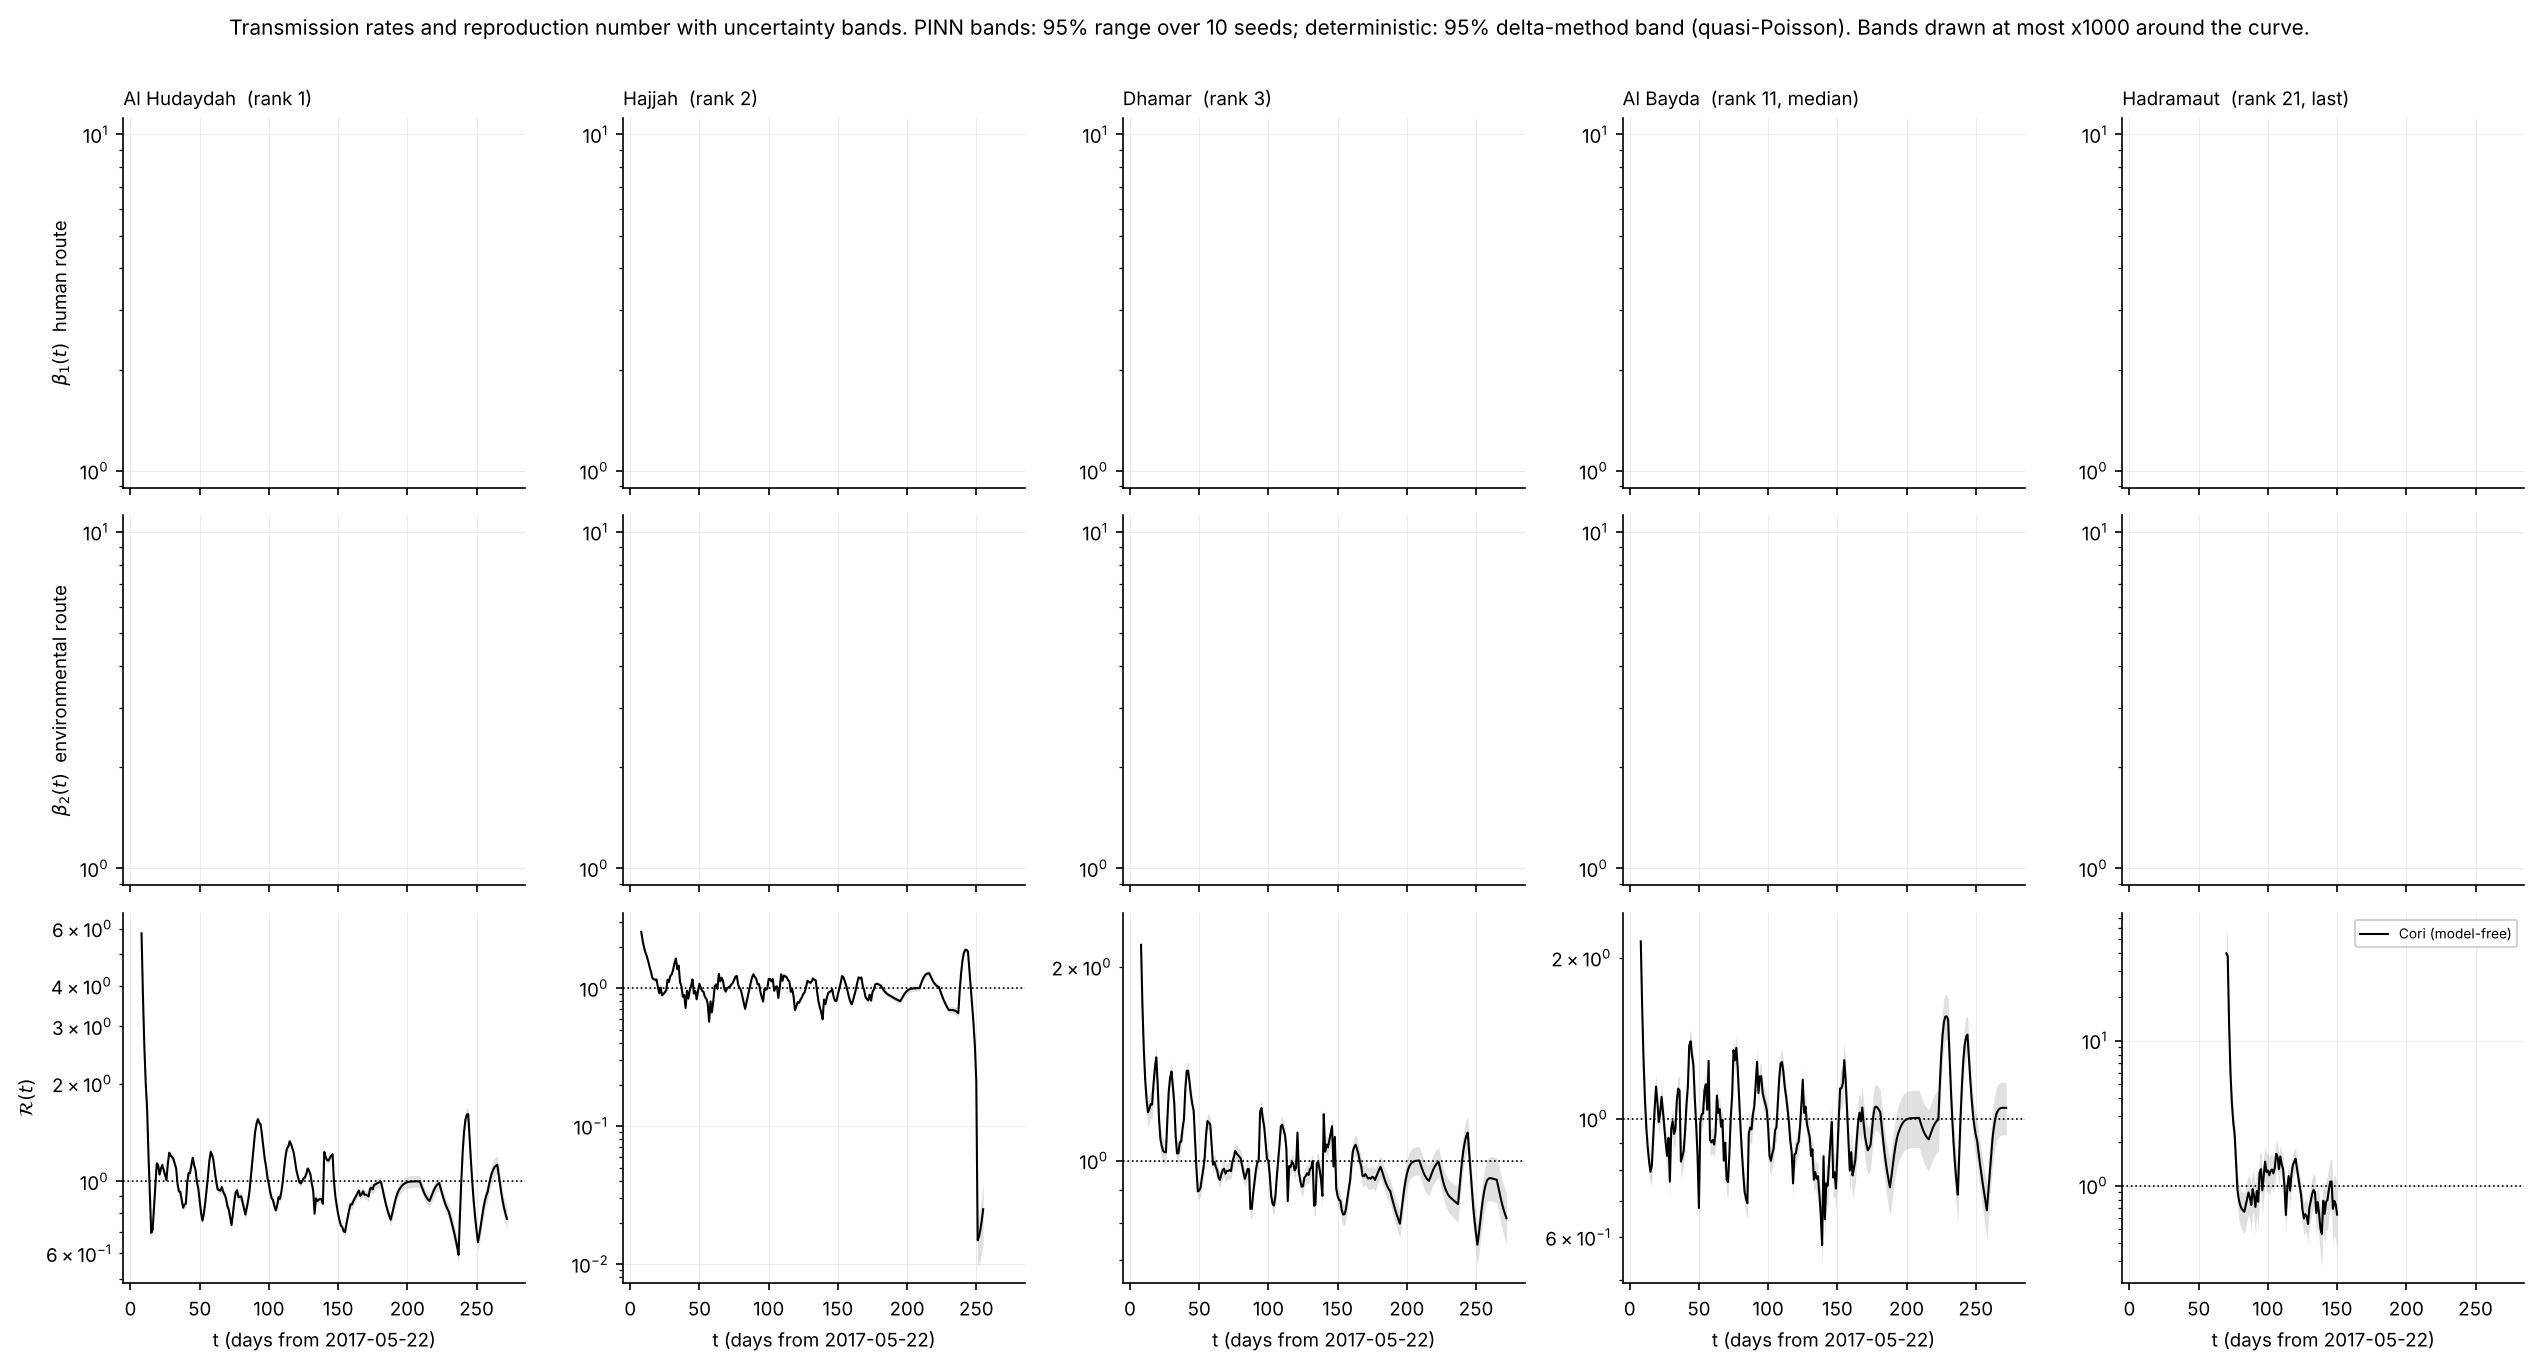

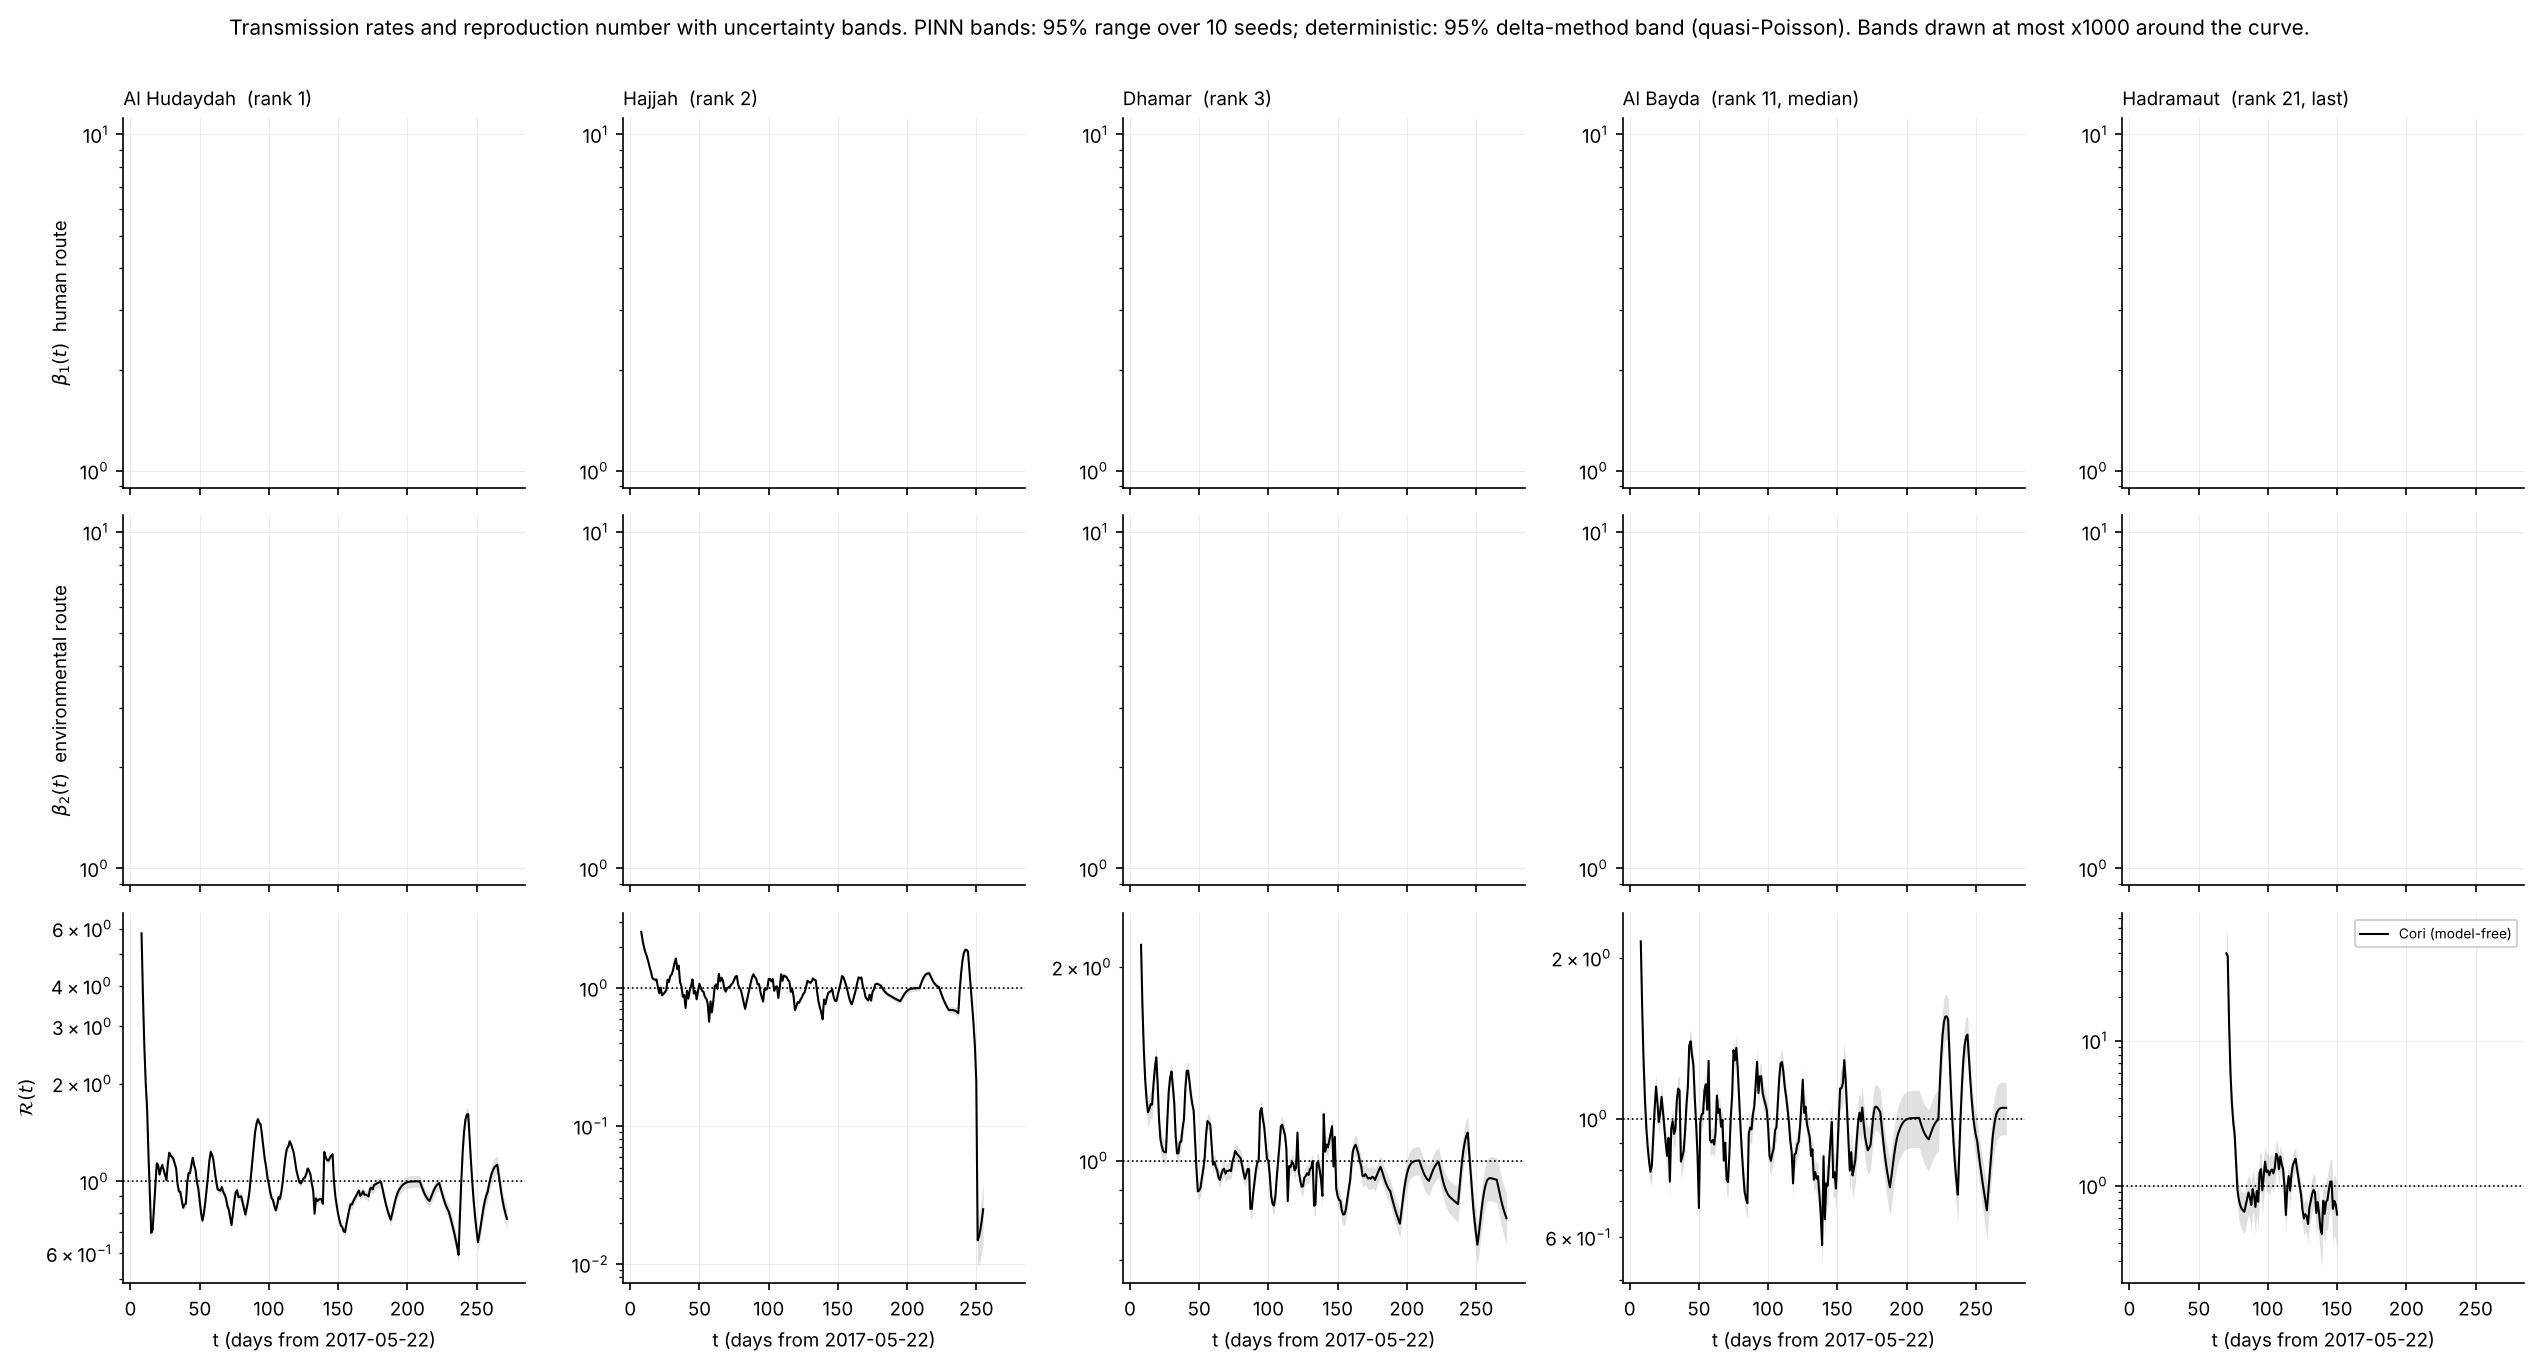

In [25]:
def _cell():
    cori = A.cori_all(panel, panel.names)
    cori_short = A.cori_all(panel, panel.names, si=epiestim.SI_SHORT)
    A.fig_bands(recs, idx, f"{FIG}/E3a_bands_main.png", arms=("det", "dpinn", "ff"), cori=cori)
    display(Image(f"{FIG}/E3a_bands_main.png"))
    A.fig_bands(recs, idx, f"{FIG}/E3b_bands_factorial.png", arms=("det", "dpinn_fs", "fdpinn"), cori=cori)
    display(Image(f"{FIG}/E3b_bands_factorial.png"))
    globals().update(locals())
_safe(_cell)

In [26]:
def _cell():
    # Band widths: median over the window of hi/lo, a scale-free width
    rows = []
    for c in FOCUS:
        for a in ("det", "sir", *A.PINN):
            for key in ("beta10", "beta20", "R"):
                b = A.band_of(recs, idx, c, a, key)
                if b is None:
                    continue
                t, lo, mid, hi, kind = b
                rows.append(dict(city=c, arm=a, quantity=key, band=kind,
                                 median_hi_over_lo=float(np.median(hi / np.maximum(lo, 1e-300)))))
    bw = pd.DataFrame(rows).pivot_table(index=["city", "arm"], columns="quantity",
                                        values="median_hi_over_lo").reset_index()
    display(fmt(bw, 2))
    globals().update(locals())
_safe(_cell)

[not available yet: KeyError: 'median_hi_over_lo']


*Interpretation of this section is added once every run it depends on is complete (see the run-status table at the top).*

## 4. Does the method recover known values?

**4a. A literature-calibrated truth.** No published study gives $\beta_1(t)$ or $\beta_2(t)$ for
Yemen, so recovery is tested on synthetic counts whose generating values are known and whose
$\mathcal R(t)$ is set to the published second-wave picture: about 2 at the May 2017 surge
(Camacho et al. 2018 report a median $R_t>2$ in 13 of 23 governorates; an initial-stage estimate
from culture-confirmed cases is 2.2 [2.1, 2.3]), between 1 and 2 through the summer, and below 1
by October 2017. The route split is unknown in the literature, so two opposite truths are used:
20 % and 70 % environmental. Counts are Poisson draws on each focus governorate's **real** bulletin
calendar and population, generated from the same single-location model that is fitted, so the
truth is exactly attainable and any miss is the method's. Counts are drawn negative-binomial with
each governorate's own estimated $k$, so the synthetic noise is as heavy as the record's. Three
replicate datasets per truth.

In [27]:
def _cell():
    rt = A.recovery_table(recs, idx)
    if rt.empty:
        print("recovery runs not finished yet")
    else:
      rsum = (rt.groupby(["truth", "arm"])
                  .agg(n=("seed", "size"), true_share=("true_share", "first"),
                     est_share_mean=("est_share", "mean"), est_share_sd=("est_share", "std"),
                     R_relerr=("R_relerr", "median"), beta1_relerr=("beta1_relerr", "median"),
                     beta2_relerr=("beta2_relerr", "median"), fit_MAE=("fit_MAE", "mean"),
                     truth_MAE=("truth_MAE", "mean")).reset_index())
      display(fmt(rsum, 3))
      A.fig_recovery(recs, idx, rt, f"{FIG}/E4a_recovery.png")
      display(Image(f"{FIG}/E4a_recovery.png"))
    globals().update(locals())
_safe(_cell)

recovery runs not finished yet


**4b. Against published estimates.** The fitted $\mathcal R(t)$ on the real record, averaged over
three windows where published estimates exist, next to the model-free Cori estimate, and the
record's own attack rates against those WHO EMRO reported for the second wave. The attack rates
check the data rather than the method: if they did not match, no fitted quantity could.

In [28]:
def _cell():
    lt = A.literature_table(recs, idx, cori)
    display(fmt(lt, 2))
    ar = A.attack_rates(panel)
    display(fmt(ar[ar.WHO_EMRO_2nd_wave_per_10k.notna() | ar.governorate.isin(FOCUS)], 1))
    globals().update(locals())
_safe(_cell)

city,method,"early (d 0-20, late May-June)",summer (d 30-100),October (d 132-162)
Al Hudaydah,Cori (SI 5 d),1.80,1.02,0.91
Hajjah,Cori (SI 5 d),1.55,1.02,0.92
Dhamar,Cori (SI 5 d),1.41,1.05,0.96
Al Bayda,Cori (SI 5 d),1.12,1.02,0.87
Hadramaut,Cori (SI 5 d),nan,4.13,0.77
National,Cori (SI 5 d),1.43,1.00,0.88


governorate,record_attack_per_10k,WHO_EMRO_2nd_wave_per_10k
Amran,863.6,902.3
Al Mahwit,827.2,878.9
Al Dhale'e,625.2,639.8
Dhamar,504.9,524.9
Hajjah,500.6,nan
Al Hudaydah,462.9,nan
Al Bayda,382.8,nan
Hadramaut,7.2,nan


*Interpretation of this section is added once every run it depends on is complete (see the run-status table at the top).*

## 5. An outside reference for $\mathcal R(t)$

The Cori et al. (2013) estimator used by EpiEstim, implemented in `epiestim.py`. It uses only the
counts and a serial interval, nothing from the SEIP model. Bulletin totals are spread uniformly
across the days of their interval; $R_t$ is estimated over trailing 7-day windows with the EpiEstim
default Gamma(1, 5) prior. Two serial intervals: mean 5.0 d (the value used for the 2017 Yemen
record) and mean 3.7 d (reconstructed from the 1853 Danish epidemics), to show how much the
reference itself depends on that choice.

The table scores each arm's $\mathcal R(t)$ (seed median for PINNs) against the Cori curve: mean
absolute difference, median log-ratio (0 = no bias), the fraction of days inside the Cori 95 %
credible interval, and the rank correlation.

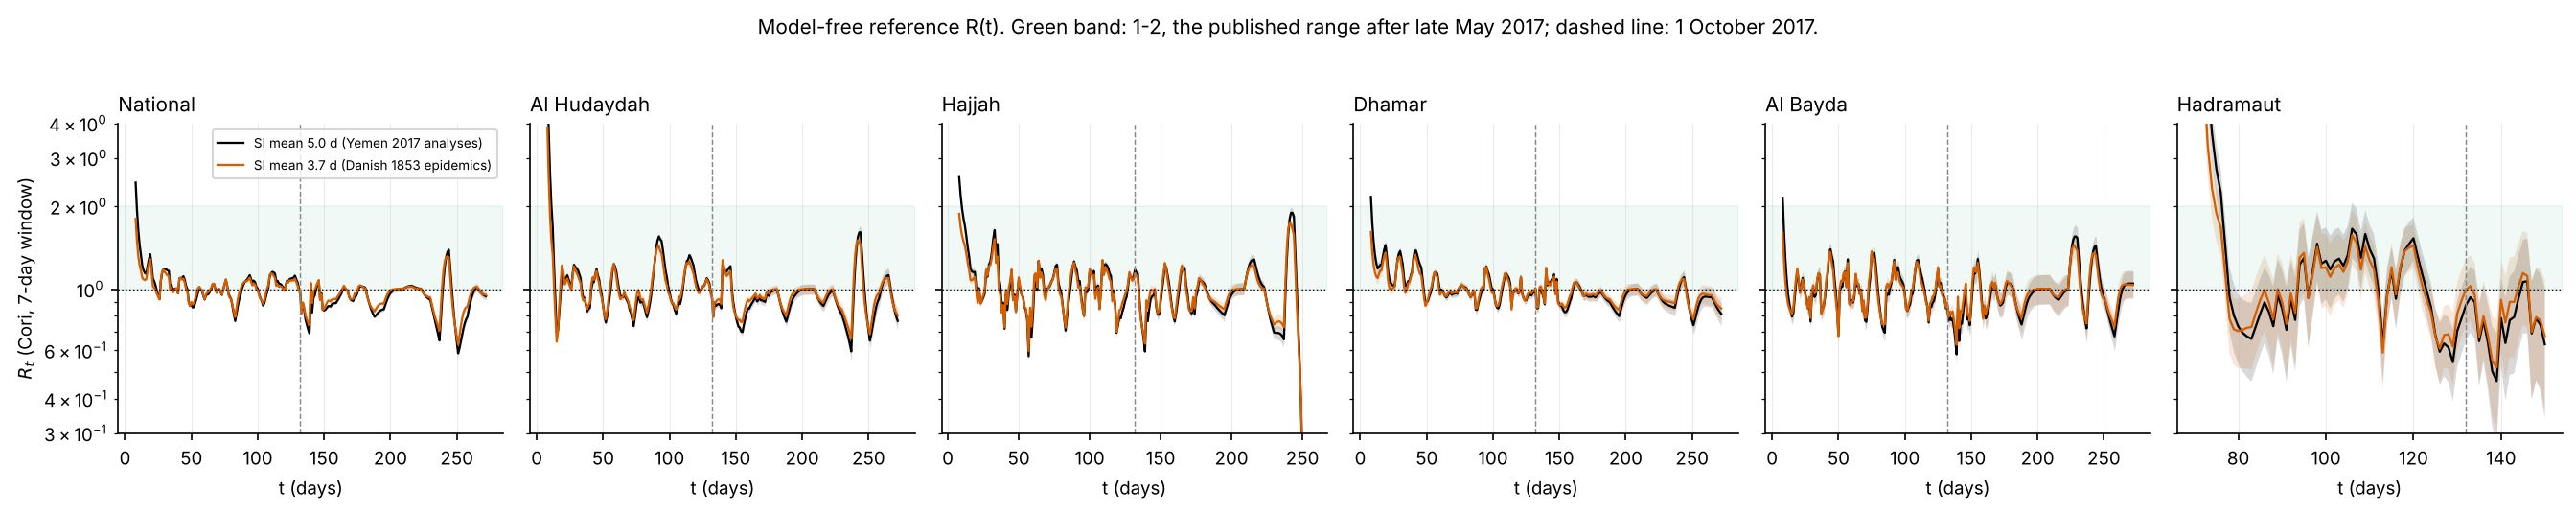

In [29]:
def _cell():
    A.fig_cori(cori, cori_short, f"{FIG}/E5_cori.png")
    display(Image(f"{FIG}/E5_cori.png"))
    ag = A.cori_agreement(recs, idx, cori)
    display(fmt(ag, 3))
    globals().update(locals())
_safe(_cell)

*Interpretation of this section is added once every run it depends on is complete (see the run-status table at the top).*

## 6. Sensitivity to the fixed modelling choices

Each row changes one choice and refits on the full record; `dMAE_%` and `dRmean_%` are changes
relative to the baseline fit for that city and arm.

| variant | change |
|---|---|
| `trunc` | initial stocks from the truncated-system occupancy instead of the untruncated identity (1.575× and 1.582× smaller) |
| `age_eq`, `age_ln` | exponential (equilibrium) or log-normal initial age profile instead of flat |
| `onset` | observe infectious onsets $\int\sigma E\,da$ instead of the force of infection |
| `nowinsor` | no winsorisation of the 0.5 % largest rates |
| `poisson` | the original Poisson deviance instead of negative binomial |
| `wls` | weighted least squares instead of a deviance |
| `M2`, `M6` | Fourier order of $\beta$: 2 or 6 instead of 4 |
| `wren5`, `wren80` | PINN renewal-coupling weight 5 or 80 instead of 20 (PINN arms only, seed 0) |

Diffusion is the remaining fixed choice; it only exists in the spatial model and is swept in §10.

In [30]:
def _cell():
    st = A.sensitivity_table(recs, idx)
    if st.empty or "variant" not in st:
        st = pd.DataFrame(columns=["city", "arm", "variant", "MAE", "dMAE_%", "R_mean", "dRmean_%", "R_min", "R_max", "env_share"])
    cols = ["city", "arm", "variant", "MAE", "dMAE_%", "R_mean", "dRmean_%", "R_min", "R_max", "env_share"]
    for arm in ("det", "dpinn", "ff"):
        t = st[st.arm == arm]
        if len(t):
            print(f"--- {A.ARM[arm][0]} ---")
            display(fmt(t[cols].sort_values(["city", "variant"]), 3))
    spread = (st.groupby(["arm", "variant"]).agg(dMAE_med=("dMAE_%", "median"),
              dR_med=("dRmean_%", "median"), dR_max=("dRmean_%", lambda v: v.abs().max()))
              .reset_index())
    display(fmt(spread, 1))
    globals().update(locals())
_safe(_cell)

arm,variant,dMAE_med,dR_med,dR_max


*Interpretation of this section is added once every run it depends on is complete (see the run-status table at the top).*

## 7. Residual diagnostics

For each full-record fit (seed 0), Pearson residuals under the **negative-binomial** variance the
fit used ($\mu+\mu^2/k$): the dispersion $\hat\phi=\sum r_i^2/(n-p)$ (1 when the variance model is
right), the same quantity under a Poisson variance for comparison (`dispersion_vs_poisson`, the
pilot's ~80), lag-1 autocorrelation and a Ljung–Box test over 10 lags, and randomized quantile
residuals (Dunn & Smyth), standard normal under a correct model (`rqr_sd` ≈ 1, Shapiro p not small).

In [31]:
def _cell():
    dt, keep = A.diagnostics_table(recs, idx, cities=FOCUS)
    dt["arm"] = pd.Categorical(dt.arm, A.ORDER)
    display(fmt(dt.sort_values(["city", "arm"]), 3))
    A.fig_diagnostics(keep, f"{FIG}/E7_diagnostics.png")
    display(Image(f"{FIG}/E7_diagnostics.png"))
    dall, _ = A.diagnostics_table(recs, idx, cities=panel.names)
    print("all 21 governorates, deterministic arm: dispersion median %.1f (range %.1f-%.1f), "
          "NB size median %.1f"
          % tuple(dall[dall.arm == "det"].dispersion.quantile([.5, 0, 1]).tolist()
                  + [dall[dall.arm == "det"].nb_size.median()]))
    globals().update(locals())
_safe(_cell)

[not available yet: AttributeError: 'DataFrame' object has no attribute 'arm']


*Interpretation of this section is added once every run it depends on is complete (see the run-status table at the top).*

## 8. Simple baselines

* **Spline**: Poisson P-spline regression of incidence on time (24 cubic B-splines, smoothing chosen
  by AIC on the training rows). No epidemic mechanism; the floor any curve-fitter reaches.
* **SIR**: $S'=-\beta(t)SI$, $I'=\beta(t)SI-\gamma I$, $\gamma=1/7$ d, $\beta(t)$ an order-4 Fourier
  series, Poisson deviance. The simplest mechanistic model with a reproduction number.

Both run through the same rotated 4-fold holdout as every other arm. Held-out MAE at all 21
governorates:

In [32]:
def _cell():
    b = cvs[cvs.arm.isin(["det", "sir", "spline"])]
    piv = b.pivot_table(index="city", columns="arm", values="out_MAE")
    piv["sir/det"] = piv["sir"] / piv["det"]; piv["spline/det"] = piv["spline"] / piv["det"]
    display(piv.reindex([c for c in panel.names if c in piv.index]).style.format("{:.3g}"))
    print("median over 21 governorates: SIR/det %.3f, spline/det %.3f; det best at %d, SIR best at %d, "
          "spline best at %d" % (piv["sir/det"].median(), piv["spline/det"].median(),
          (piv[["det", "sir", "spline"]].idxmin(axis=1) == "det").sum(),
          (piv[["det", "sir", "spline"]].idxmin(axis=1) == "sir").sum(),
          (piv[["det", "sir", "spline"]].idxmin(axis=1) == "spline").sum()))
    globals().update(locals())
_safe(_cell)

[not available yet: NameError: name 'cvs' is not defined]


*Interpretation of this section is added once every run it depends on is complete (see the run-status table at the top).*

## 9. All 21 governorates

The deterministic SEIP arm (with its delta-method band) and the SIR baseline at every governorate,
against the Cori reference. Panels are ordered by distance from Sana'a.

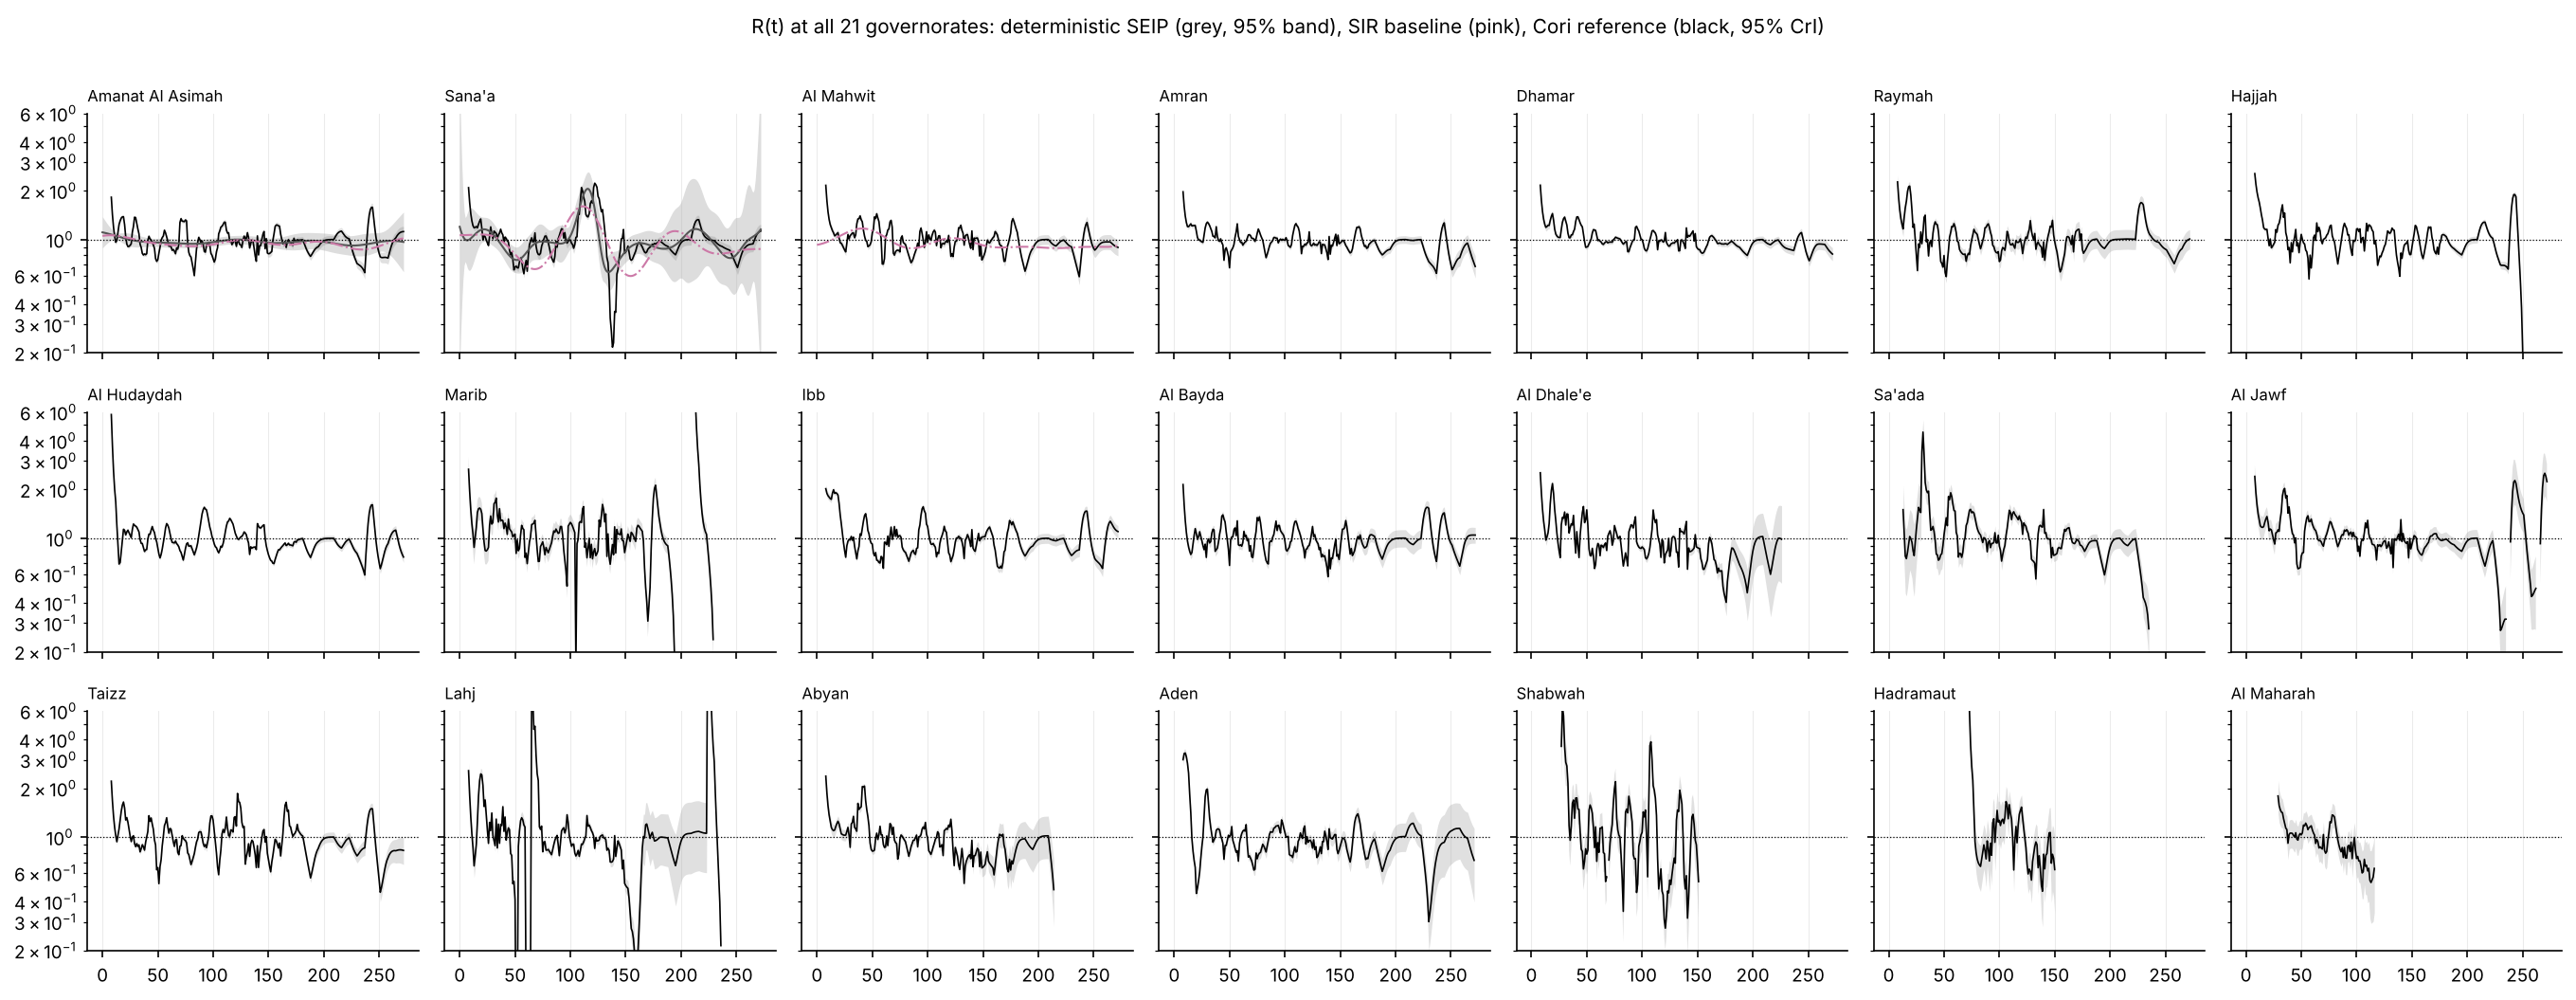

arm,mean_abs_diff,log_ratio_median,frac_in_CrI,spearman
det,0.135,0.006,0.319,0.416
sir,0.129,-0.041,0.245,0.348


city,MAE,nRMSE,R_min,R_mean,R_max,env_share
Amanat Al Asimah,0.000,0.354,0.918,0.971,1.108,0.000
Sana'a,0.000,0.355,0.630,0.998,2.056,0.146


In [33]:
def _cell():
    A.fig_all_cities_R(recs, idx, cori, list(panel.names[i] for i in np.argsort(panel.xg)),
                       f"{FIG}/E9_all_cities_R.png")
    display(Image(f"{FIG}/E9_all_cities_R.png"))
    ag21 = A.cori_agreement(recs, idx, cori, cities=panel.names, arms=("det", "sir"))
    display(fmt(ag21.groupby("arm")[["mean_abs_diff", "log_ratio_median", "frac_in_CrI", "spearman"]]
                .median().reset_index(), 3))
    r21 = []
    for c in panel.names:
        for a in ("det", "sir"):
            ds = A.select(recs, idx, city=c, arm=a, fold=-1, variant="base", truth="")
            if ds:
                r21.append(dict(city=c, arm=a, **A.r_summary(ds[0]), **A.errs(ds[0]["yhat"], ds[0]["y"])))
    r21 = pd.DataFrame(r21)
    display(fmt(r21[r21.arm == "det"][["city", "MAE", "nRMSE", "R_min", "R_mean", "R_max", "env_share"]], 3))
    globals().update(locals())
_safe(_cell)

*Interpretation of this section is added once every run it depends on is complete (see the run-status table at the top).*

## 10. Transmission that varies by location, and a network instead of an axis

All 21 governorates (2,806 intervals) fitted at once by the deterministic solver, NB deviance.

**Original geometry: diffusion along distance from Sana'a**, $x\in[0, 799.4]$ km,
$D_1=\dots=D_4=50$ km²/day:

* `shared_D50`: one $\beta_j(t)$ for the whole country (20 parameters), as in the original §13;
* `governorate_D50`: $\beta_j(t)\cdot k_g$, one offset per governorate common to both routes,
  ridge-shrunk toward 1 (41 parameters); refitted at $D=5$ and $D=250$ because diffusion is the
  one fixed choice §6 cannot test.

**New geometry: a governorate network** (`network_fit.py`). Each governorate is its own node running
the age-structured SEIP system with no diffusion. Susceptibles at $g$ feel the pressure
$\sum_h M_{gh}\,(\text{pressure generated at }h)$ with $M=(1-m)I+mW$,
$W_{gh}\propto N_h/d_{gh}^2$ over great-circle distances between governorate centroids (the IASC
COD boundaries already in the data), and the mixing fraction $m$ estimated:

* `network`: $\beta_j(t)\cdot k_g$ plus estimated $m$ (42 parameters);
* `isolated`: the same with $m=0$, so `network` − `isolated` is the value of the coupling;
* `network_shared`: estimated $m$ but one national $\beta_j(t)$, so `network` − `network_shared` is
  the value of letting transmission differ by governorate.

AIC is deviance + 2 × parameters. In the network models $\mathcal R_g(t)$ uses the local
$\beta_g$ and $S_g$; with small $m$ it is the within-governorate reproduction number.

In [34]:
def _cell():
    if S:
        display(fmt(A.spatial_table(S), 4))
    if "network" in S:
        A.fig_spatial_R(S, f"{FIG}/E10_spatial_R.png")
        display(Image(f"{FIG}/E10_spatial_R.png"))
    rows = []
    for g, nm in enumerate(panel.names):
        m = panel.gov == g
        r = dict(governorate=nm, x_km=panel.xg[g], obs_mean=panel.y[m].mean())
        for key in ("shared_D50", "governorate_D50", "isolated", "network"):
            if key in S:
                r[key] = S[key]["yhat"][m].mean() / max(panel.y[m].mean(), 1e-12)
        rows.append(r)
    print("fitted mean / observed mean, by governorate (1 = unbiased)")
    display(fmt(pd.DataFrame(rows).sort_values("x_km"), 2))
    globals().update(locals())
_safe(_cell)

fitted mean / observed mean, by governorate (1 = unbiased)


governorate,x_km,obs_mean
Amanat Al Asimah,0.00,0.00
Sana'a,15.71,0.00
Al Mahwit,74.91,0.00
Amran,88.74,0.00
Dhamar,93.19,0.00
Raymah,105.57,0.00
Hajjah,127.03,0.00
Al Hudaydah,133.12,0.00
Marib,137.76,0.00
Ibb,151.43,0.00


*Interpretation of this section is added once every run it depends on is complete (see the run-status table at the top).*

## 11. Observed against fitted surfaces

The observed incidence field $I(t,x)$ against each fitted field. Rows are governorates ordered by
distance from Sana'a; each bulletin interval is drawn across its own span, **nothing is
interpolated between bulletins**, and the model is drawn as its interval average, the quantity it
was fitted to. The lower row is the signed residual relative to each governorate's mean incidence.
The 3-D view renders the same interval fields. The per-city fields stitch 21 independent fits
together; the 1-D diffusion and network fields each come from one model of the whole country.

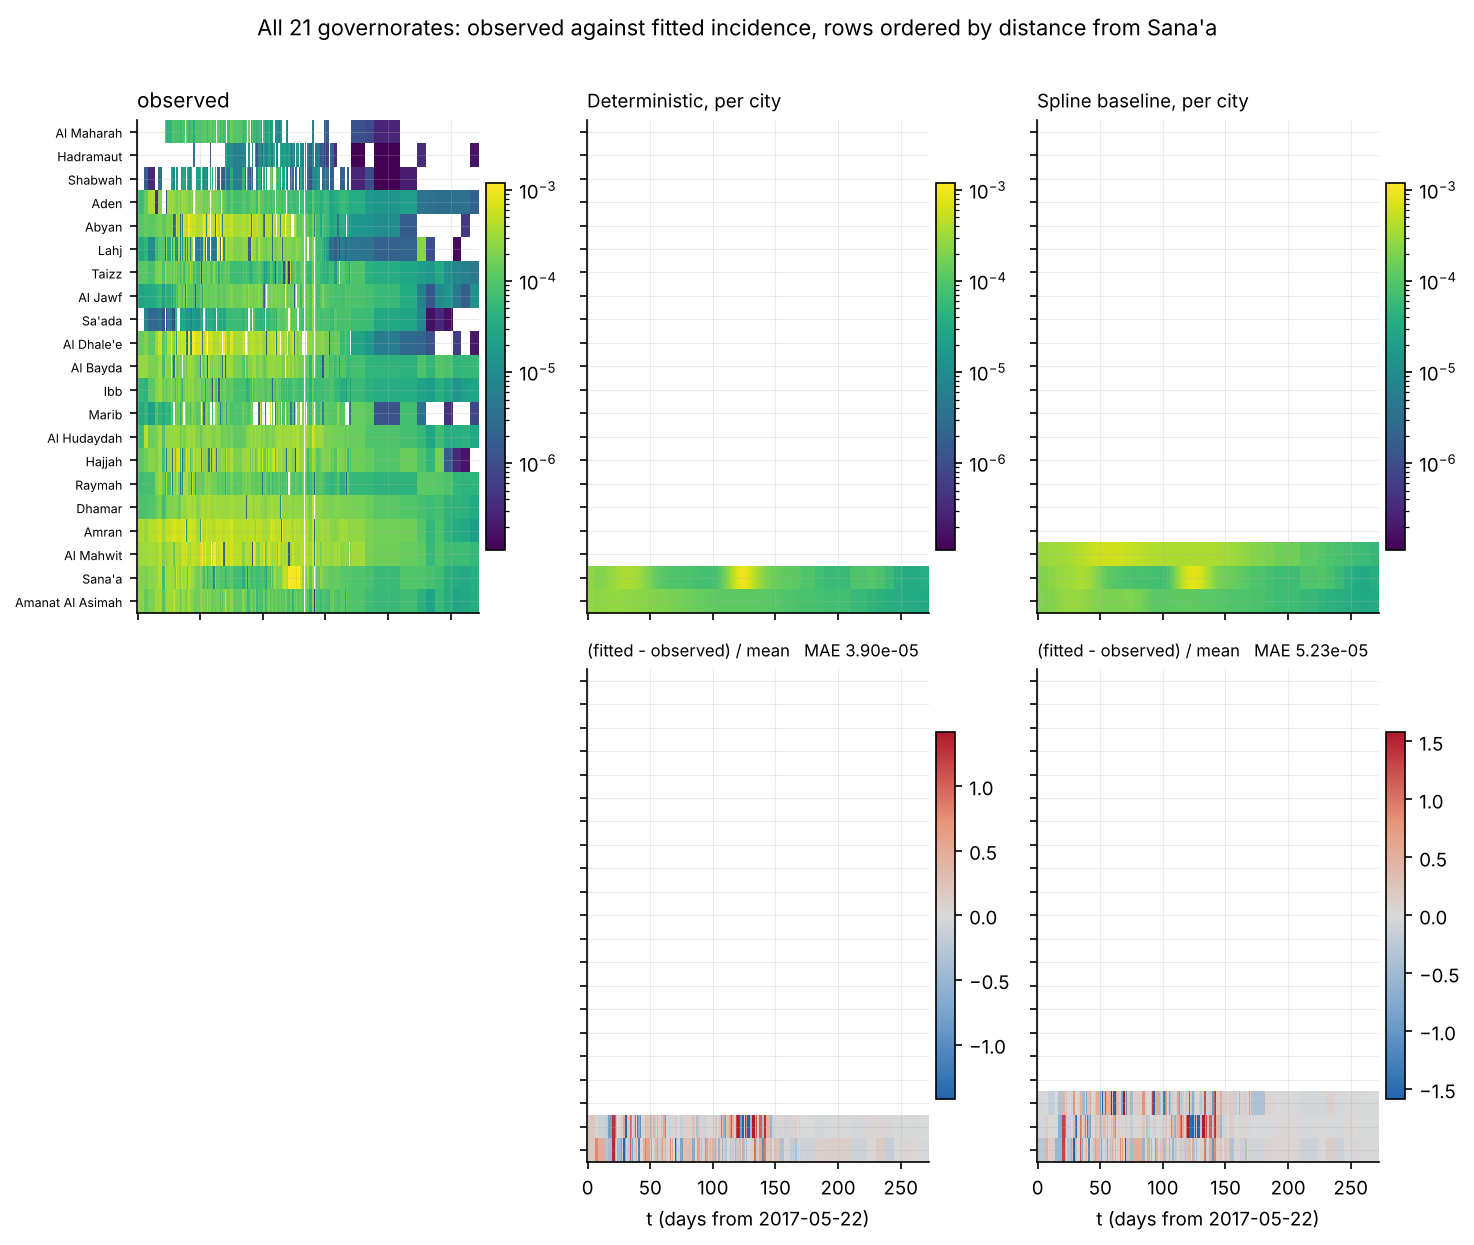

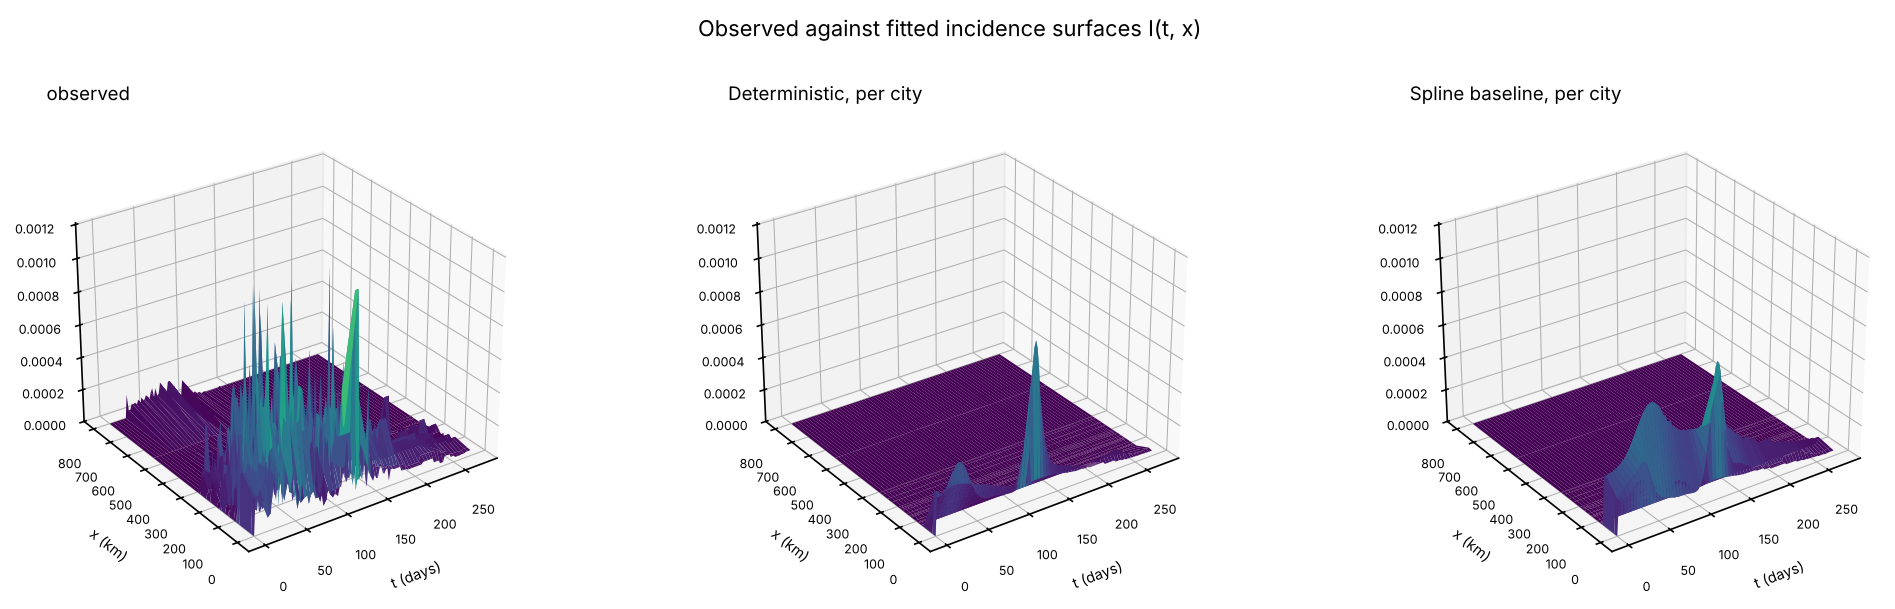

field,cells,MAE,RMSE,nRMSE,corr
"Deterministic, per city",544,0.0000,0.0001,0.3442,0.8867
"Spline baseline, per city",816,0.0001,0.0001,0.3713,0.8481


In [35]:
def _cell():
    fields = {"Deterministic, per city": A.city_fields(recs, idx, panel, "det", panel.names)[1],
              "Spline baseline, per city": A.city_fields(recs, idx, panel, "spline", panel.names)[1]}
    for key, nm in (("shared_D50", "1-D diffusion, shared beta(t)"),
                    ("governorate_D50", "1-D diffusion, beta(t) x k_g"),
                    ("network", "Network, beta(t) x k_g")):
        if key in S:
            fields[nm] = A.spatial_field(S[key], panel)
    A.fig_surfaces(panel, fields, f"{FIG}/E11a_surfaces_all.png",
                   "All 21 governorates: observed against fitted incidence, rows ordered by "
                   "distance from Sana'a")
    display(Image(f"{FIG}/E11a_surfaces_all.png"))
    A.fig_surfaces_3d(panel, fields, f"{FIG}/E11b_surfaces_3d.png")
    display(Image(f"{FIG}/E11b_surfaces_3d.png"))
    display(fmt(A.surface_errors(panel, fields), 4))
    globals().update(locals())
_safe(_cell)

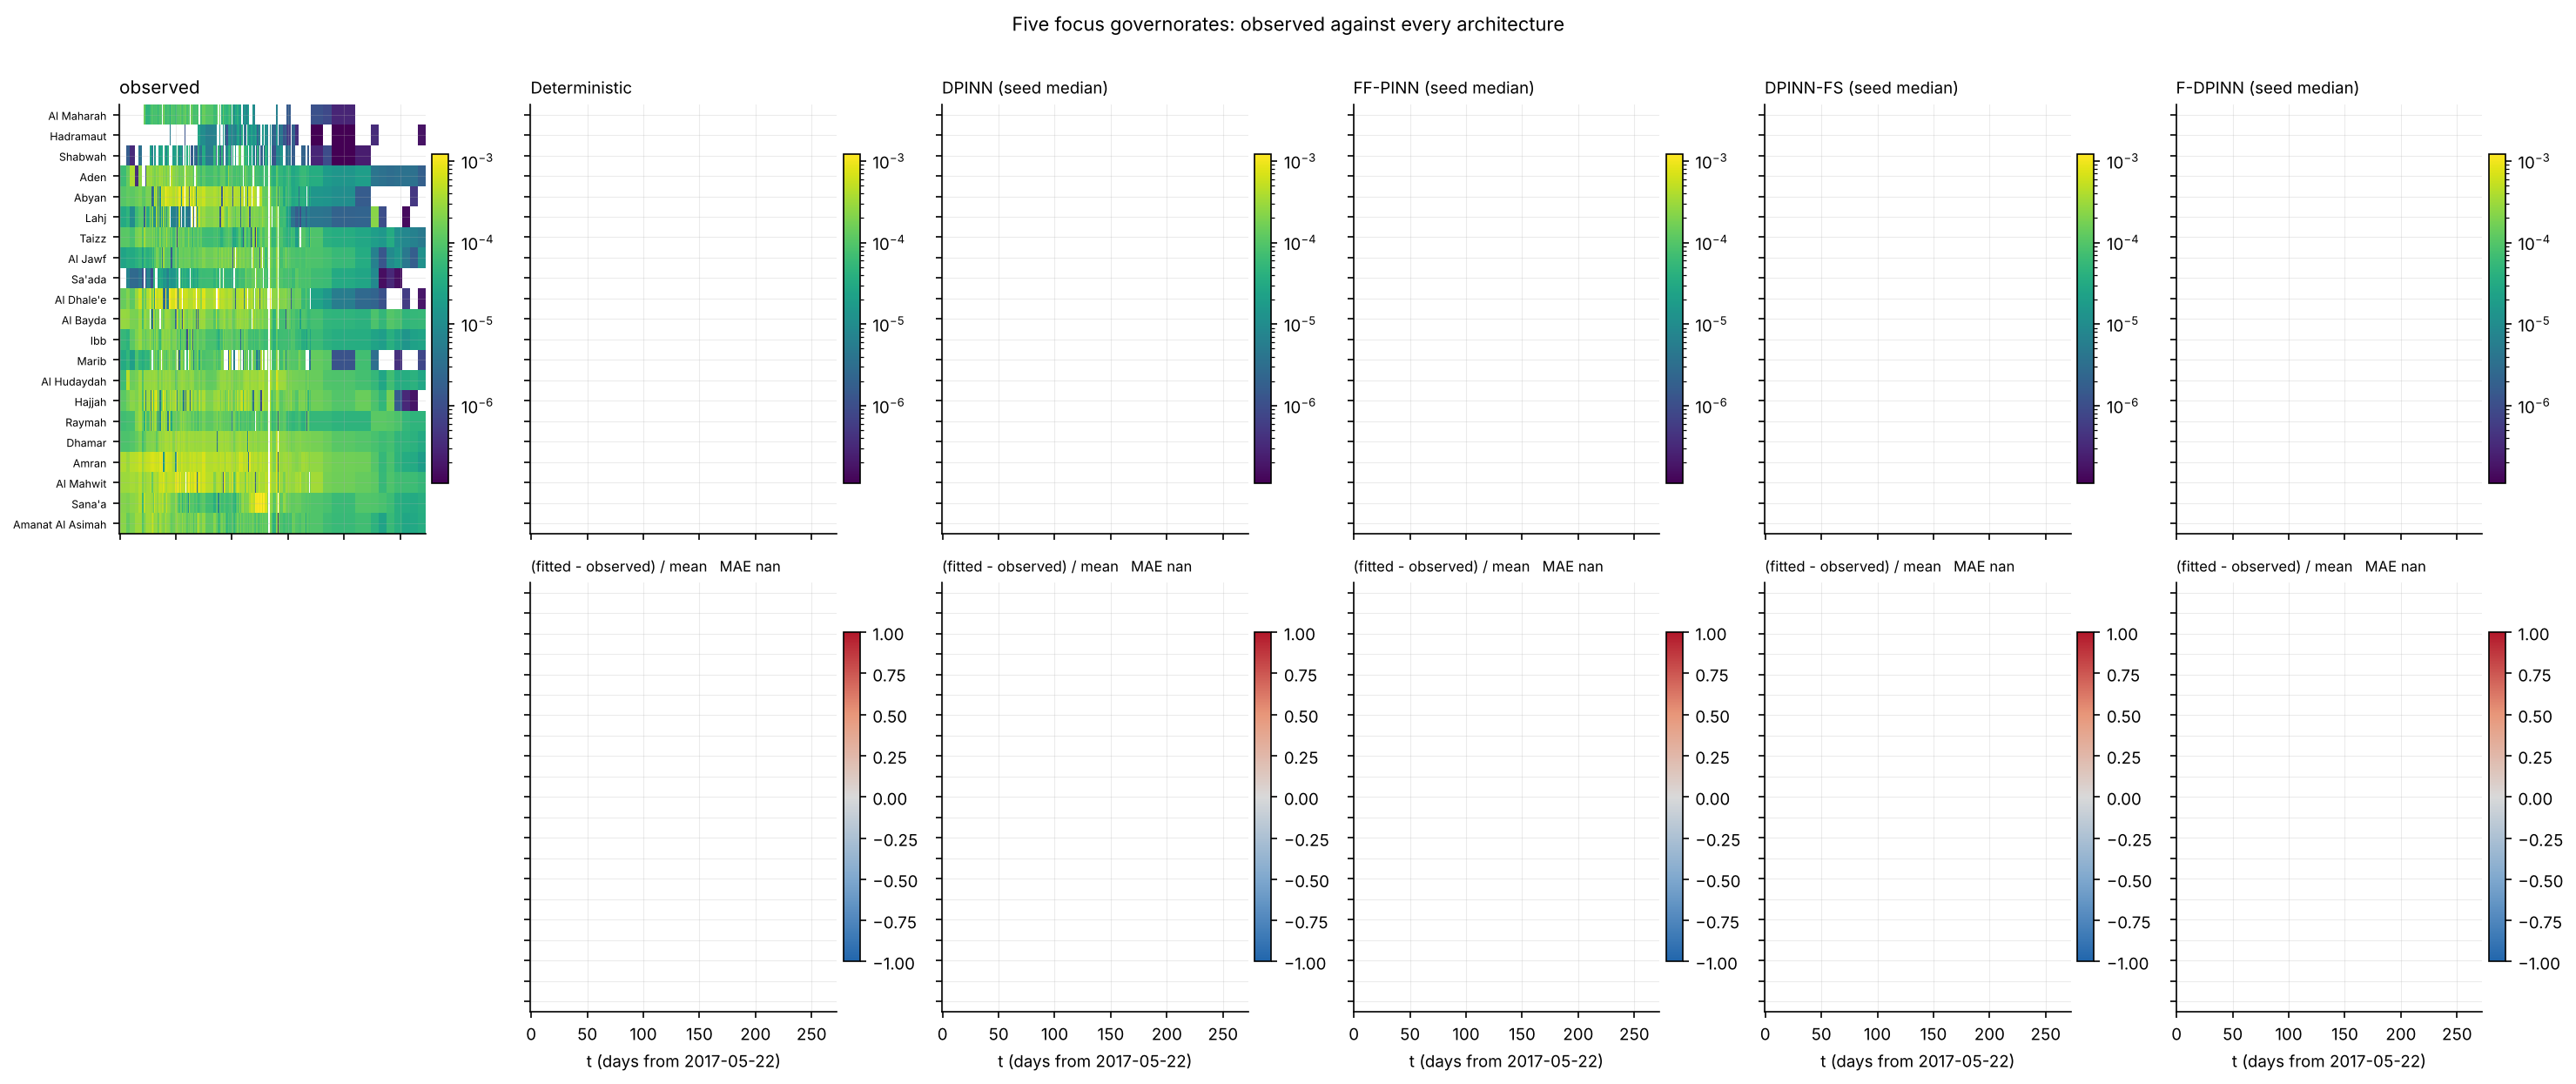

field,cells,MAE,RMSE,nRMSE,corr
Deterministic,0,nan,nan,nan,nan
DPINN (seed median),0,nan,nan,nan,nan
FF-PINN (seed median),0,nan,nan,nan,nan
DPINN-FS (seed median),0,nan,nan,nan,nan
F-DPINN (seed median),0,nan,nan,nan,nan


In [36]:
def _cell():
    # the five focus governorates, where every architecture was fitted
    ff = {"Deterministic": fields["Deterministic, per city"]}
    for a in ("dpinn", "ff", "dpinn_fs", "fdpinn"):
        ff[A.ARM[a][0] + " (seed median)"] = A.city_fields(recs, idx, panel, a, panel.names)[1]
    if "Network, beta(t) x k_g" in fields:
        ff["Network, beta(t) x k_g"] = fields["Network, beta(t) x k_g"]
    foc_idx = [panel.names.index(c) for c in FOCUS]
    mask = np.isin(np.arange(panel.ng), foc_idx)
    sub = {k: np.where(mask[None, :], v, np.nan) for k, v in ff.items()}
    A.fig_surfaces(panel, sub, f"{FIG}/E11c_surfaces_focus.png",
                   "Five focus governorates: observed against every architecture")
    display(Image(f"{FIG}/E11c_surfaces_focus.png"))
    display(fmt(A.surface_errors(panel, ff, cities=FOCUS), 4))
    globals().update(locals())
_safe(_cell)

*Interpretation of this section is added once every run it depends on is complete (see the run-status table at the top).*

## 12. What the extended analysis shows

*Interpretation of this section is added once every run it depends on is complete (see the run-status table at the top).*